In [ ]:
from openpyxl import load_workbook, Workbook
from openpyxl.utils import column_index_from_string
from openpyxl.styles import PatternFill
import os
import math

def export_triplet_blocks_first_col(
    input_xlsx_path: str,
    output_xlsx_path: str = None,
    input_sheet_name: str = "Results",     # CHANGED: default to "Results"
    output_sheet_name: str = "Extracted",
    log_sheet_name: str = "Extracted_log2", # optional: log2 of raw extracted values (with offset)
    normalized_sheet_name: str = "Normalized_log2FC",  # CHANGED: clearer name
    start_row: int = 27,
    end_row: int = 45,
    sample_col_letter: str = "B",
    first_triplet_start_col_letter: str = "D",
    triplet_width: int = 3,
    header_row: int = 16,
    subheader_row: int = None,
    log_offset: float = 0.5,              # CHANGED: used for raw log2 and (optionally) denom safety
    fc_pseudocount: float = 0.0,          # NEW: added to BOTH numerator and denominator before ratio
):
    """
    Creates an output workbook with:
      1) Extracted: raw extracted values
      2) Extracted_log2: log2(raw + log_offset)
      3) Normalized_log2FC: log2( (value + fc_pseudocount) / (A1 + fc_pseudocount) )

    Normalized_log2FC interpretation:
      0   = same as A1
      +1  = 2-fold increase vs A1
      -1  = 2-fold decrease vs A1

    Coloring on Normalized_log2FC:
      - RED  if log2FC >= +1
      - BLUE if log2FC <= -1
    """

    if output_xlsx_path is None:
        in_dir = os.path.dirname(os.path.abspath(input_xlsx_path))
        in_stem, _ = os.path.splitext(os.path.basename(input_xlsx_path))
        output_xlsx_path = os.path.join(in_dir, f"{in_stem}_extracted.xlsx")

    wb = load_workbook(input_xlsx_path, data_only=True)
    ws = wb[input_sheet_name] if input_sheet_name else wb.active

    sample_col = column_index_from_string(sample_col_letter)
    triplet_start = column_index_from_string(first_triplet_start_col_letter)

    def _get_header_value(row_idx: int, col_idx: int) -> str:
        v = ws.cell(row=row_idx, column=col_idx).value
        if v is None:
            for rng in ws.merged_cells.ranges:
                if rng.min_row <= row_idx <= rng.max_row and rng.min_col <= col_idx <= rng.max_col:
                    v = ws.cell(row=rng.min_row, column=rng.min_col).value
                    break
        if v is None:
            return ""
        return str(v).strip()

    triplet_cols = []
    col = triplet_start
    max_col = ws.max_column

    while col <= max_col:
        hdr = _get_header_value(header_row, col)
        any_data = any(ws.cell(row=r, column=col).value is not None for r in range(start_row, end_row + 1))
        if (hdr == "") and (not any_data):
            break

        subhdr = _get_header_value(subheader_row, col) if subheader_row is not None else ""
        triplet_cols.append((col, hdr, subhdr))
        col += triplet_width

    out_wb = Workbook()
    out_ws = out_wb.active
    out_ws.title = output_sheet_name
    log_ws = out_wb.create_sheet(title=log_sheet_name)
    norm_ws = out_wb.create_sheet(title=normalized_sheet_name)

    def _write_headers(target_ws):
        target_ws.cell(row=1, column=1, value="Sample")
        for j, (_, hdr, _) in enumerate(triplet_cols, start=2):
            target_ws.cell(row=1, column=j, value=hdr)

        data_start = 2
        if subheader_row is not None:
            data_start = 3
            target_ws.cell(row=2, column=1, value="")
            for j, (_, _, subhdr) in enumerate(triplet_cols, start=2):
                target_ws.cell(row=2, column=j, value=subhdr)
        return data_start

    data_start_out_row = _write_headers(out_ws)
    data_start_log_row = _write_headers(log_ws)
    data_start_norm_row = _write_headers(norm_ws)

    def _to_float_or_none(x):
        if x is None:
            return None
        try:
            return float(x)
        except (TypeError, ValueError):
            return None

    def _log2_or_none(x):
        xv = _to_float_or_none(x)
        if xv is None:
            return None
        y = xv + float(log_offset)
        if y <= 0:
            return None
        return math.log(y, 2)

    fill_blue = PatternFill(fill_type="solid", fgColor="DDEEFF")
    fill_red = PatternFill(fill_type="solid", fgColor="FFDDDD")

    # Read extracted rows into memory
    extracted_rows = []
    for r in range(start_row, end_row + 1):
        row_vals = [ws.cell(row=r, column=sample_col).value]
        for (src_col, _, _) in triplet_cols:
            row_vals.append(ws.cell(row=r, column=src_col).value)
        extracted_rows.append(row_vals)

    # Write Extracted + Extracted_log2
    out_row = data_start_out_row
    log_row = data_start_log_row
    for row_vals in extracted_rows:
        out_ws.cell(row=out_row, column=1, value=row_vals[0])
        log_ws.cell(row=log_row, column=1, value=row_vals[0])

        for j in range(2, len(row_vals) + 1):
            val = row_vals[j - 1]
            out_ws.cell(row=out_row, column=j, value=val)
            log_ws.cell(row=log_row, column=j, value=_log2_or_none(val))

        out_row += 1
        log_row += 1

    # Denominator row = first data row (assumed A1 row)
    denom = [_to_float_or_none(v) for v in extracted_rows[0]] if extracted_rows else []

    # Write Normalized_log2FC = log2( (x+p)/(A1+p) )
    norm_row = data_start_norm_row
    for row_vals in extracted_rows:
        norm_ws.cell(row=norm_row, column=1, value=row_vals[0])

        for j in range(2, len(row_vals) + 1):
            num = _to_float_or_none(row_vals[j - 1])
            d = denom[j - 1] if (j - 1) < len(denom) else None

            out_cell = norm_ws.cell(row=norm_row, column=j)

            if num is None or d is None:
                out_cell.value = None
                continue

            # ratio with optional pseudocount to avoid divide-by-zero
            num2 = num + float(fc_pseudocount)
            den2 = d + float(fc_pseudocount)
            if den2 <= 0 or num2 <= 0:
                out_cell.value = None
                continue

            log2fc = math.log(num2 / den2, 2)
            out_cell.value = log2fc

            # Color thresholds in log2 space:
            # +1 => >=2-fold increase; -1 => >=2-fold decrease
            if log2fc >= 1:
                out_cell.fill = fill_red
            elif log2fc <= -1:
                out_cell.fill = fill_blue

        norm_row += 1

    out_wb.save(output_xlsx_path)
    return output_xlsx_path

export_triplet_blocks_first_col(
    input_xlsx_path="/Users/allisonpickle/Desktop/Cytokines/Aug-20-2026-Rat-Cytokine-27-Plex-Discovery-Assay®-Kim-72633-Tissue-Cell-Culture-Supernatant.xlsx",
    output_xlsx_path=None,
    # start_row=27,
    start_row = 39,
    end_row=48,
    header_row=16,
    fc_pseudocount=0.0  # set >0 if A1 can be 0
)


Plot Relative Fluorescence with ANOVA + Dunnett post-hoc (if comparing to a control group)

In [ ]:
import os
import re
import pandas as pd
import matplotlib.pyplot as plt

def plot_relative_fluorescence_from_output_excel(
    excel_path: str,
    sheet_name: str = "Extracted",
    samples_to_include=None,              # e.g. ["A1","A2","A3"]
    sample_col_name: str = "Sample",
    output_dir: str = None,               # default: same folder as excel
    file_prefix: str = None,              # default: excel basename
    rotate_xticks: int = 45,
    dpi: int = 200,
    show: bool = False,                   # set True if you want plots displayed in notebook
):
    """
    Reads the output Excel produced by export_triplet_blocks_first_col() and saves one BAR plot per data column.

    - x-axis: Sample
    - y-axis: Relative Fluorescence
    - One plot per analyte/column (each column header in row 1 of the sheet)
    """

    if output_dir is None:
        output_dir = os.path.join(os.path.dirname(os.path.abspath(excel_path)), "Relative Fluorescence Plots")
    os.makedirs(output_dir, exist_ok=True)

    if file_prefix is None:
        file_prefix = os.path.splitext(os.path.basename(excel_path))[0]

    df = pd.read_excel(excel_path, sheet_name=sheet_name, header=0)

    if sample_col_name not in df.columns:
        raise ValueError(f"Could not find '{sample_col_name}' column in sheet '{sheet_name}'. Found: {list(df.columns)}")

    df[sample_col_name] = df[sample_col_name].astype(str).str.strip()
    if samples_to_include is not None:
        wanted = [str(s).strip() for s in samples_to_include]
        df = df[df[sample_col_name].isin(wanted)].copy()

        order_map = {s: i for i, s in enumerate(wanted)}
        df["__order__"] = df[sample_col_name].map(order_map)
        df = df.sort_values("__order__").drop(columns="__order__")

    data_cols = [c for c in df.columns if c != sample_col_name]

    def _safe(s: str) -> str:
        s = str(s)
        s = re.sub(r"[^\w\-\.\(\) ]+", "_", s)
        s = re.sub(r"\s+", " ", s).strip()
        return s[:180]

    x = df[sample_col_name].tolist()
    x_pos = list(range(len(x)))

    # -----------------------
    # USER-DEFINED X LABELS
    # Put your labels here:
    # -----------------------
    sample_label_map = {
        "S1": "Ctrl (6hr)",
         "S2": "5ng/mL LPS (6hr)",
         "S3": "100ng/mL LPS (6hr)",
         "S4": "5ng/mL LPS (24hr)",
         "S5": "100ng/mL LPS (24hr)",
         "S6": "5µg/mL LPS (48hr)",
         "S7": "5ng/mL LPS (72hr)",
         "S8": "100ng/mL LPS (72hr)",
         "S9": "10 µM w3 (24hr)",
         "S10": "2mM (S)-PD (24hr)",
         "S11": "PD (1hr), 100ng/mL LPS (24hr)",
         "S12": "w3 (1hr), 100ng/mL LPS (24hr)",
         "S13": "Ctrl (6hr)",
         "S14": "5ng/mL LPS (6hr)",
         "S15": "5ng/mL LPS (72hr)",
         "S16": "10 µM w3 (24hr)",
         "S17": "R2_2mMSPD_24hr",
         "S18": "100ng/mL LPS (6hr)",
         "S19": "100ng/mL LPS (72hr)",
         "S20": "5µg/mL LPS (48hr)",
         "S21": "w3 (1hr), 100ng/mL LPS (24hr)",
         "S22": "PD (1hr), 100ng/mL LPS (24hr)"
    }
    x_labels = [sample_label_map.get(s, s) for s in x]

    # Better default y-axis labels based on sheet
    if sheet_name == "Normalized_log2FC":
        y_label = "log2(Relative Fluorescence)"
    elif sheet_name in ("Extracted_log2", "Extracted_log"):
        y_label = "log2(Relative Fluorescence)"
    else:
        y_label = "Relative Fluorescence"

    for col in data_cols:
        y = pd.to_numeric(df[col], errors="coerce").tolist()

        fig, ax = plt.subplots(figsize=(max(8, 0.6 * len(x)), 4))
        ax.bar(x_pos, y, width=0.8)

        ax.set_title(str(col))
        ax.set_ylabel(y_label)
        ax.set_xticks(x_pos)
        ax.set_xticklabels(x_labels, rotation=rotate_xticks, ha="right", fontsize=7)
        ax.grid(True, axis="y", alpha=0.25)

        out_path = os.path.join(output_dir, f"{file_prefix}__{_safe(col)}.png")
        fig.tight_layout()
        fig.savefig(out_path, dpi=dpi)
        if show:
            plt.show()
        plt.close(fig)

    return output_dir

plot_dir = plot_relative_fluorescence_from_output_excel(
    excel_path='/Users/allisonpickle/Desktop/Composite Timed LPS.xlsx',
    sheet_name="Inflam_Combo",
    samples_to_include=["S1", "S2", "S3", "S4", "S5", "S6", "S7", "S8", "S9", "S10", "S11", "S12", "S13", "S14", "S15", "S16", "S17", "S18", "S19", "S20", "S21", "S22"
                        ],
    show=False
)
print("Saved plots to:", plot_dir)

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os
import re
from scipy.stats import f_oneway

def plot_cytokine_bars_with_anova(
    excel_path: str,
    sheet_name: str,
    output_folder: str = None,
    sample_col_name: str = "Sample",
    comparison_group: str = None,
    bar_color: str = "skyblue",
    point_colors: list = ["red", "green", "purple"],
    point_size: int = 100,
    significance_level: float = 0.05
):
    """
    Generates bar plots for each cytokine in the given Excel sheet, performs one-way ANOVA against a specified comparison group,
    and annotates the plots with significance levels. Colors individual data points based on their order and plots mean ± SD.

    Parameters:
    - excel_path: str
        Path to the input Excel file.
    - sheet_name: str
        Name of the sheet to process.
    - output_folder: str
        Folder to save the plots. If None, saves in the same directory as the input file.
    - sample_col_name: str
        Name of the column containing sample names (default: "Sample").
    - comparison_group: str
        Name of the sample to use as the comparison group. If None, defaults to the first sample in the dataset.
    - bar_color: str
        Color of the bars in the plots (default: "skyblue").
    - point_colors: list
        List of colors for the individual data points (default: ["red", "green", "purple"]).
    - point_size: int
        Size of the individual data points (default: 100).
    - significance_level: float
        Significance level for ANOVA (default: 0.05).

    Returns:
    - None
    """
    # Read the Excel sheet
    df = pd.read_excel(excel_path, sheet_name=sheet_name)

    if sample_col_name not in df.columns:
        raise ValueError(f"Column '{sample_col_name}' not found in the sheet '{sheet_name}'.")

    # Fill down the Sample column to propagate sample names to all rows
    df[sample_col_name] = df[sample_col_name].fillna(method="ffill")

    # Extract the cytokine names (from the first row)
    cytokines = df.columns[1:]  # Exclude the first column (sample names)

    # Create output folder if not specified
    if output_folder is None:
        output_folder = os.path.join(os.path.dirname(excel_path), "Cytokine_Plots")
    os.makedirs(output_folder, exist_ok=True)

    # Function to sanitize cytokine names for file paths
    def sanitize_filename(name):
        return re.sub(r'[<>:"/\\|?*]', '_', name)

    # Function to determine significance annotation
    def get_significance_label(p_value):
        if p_value < 0.001:
            return "***"
        elif p_value < 0.01:
            return "**"
        elif p_value < 0.05:
            return "*"
        else:
            return "ns"

    # Iterate over each cytokine and create a bar plot
    for cytokine in cytokines:
        # Extract data for the current cytokine
        data = df[[sample_col_name, cytokine]].dropna()

        # Debugging: Print the data being used for plotting
        print(f"Processing cytokine: {cytokine}")
        print(data.head())

        # Preserve the order of samples as they appear in the Excel sheet
        unique_samples = data[sample_col_name].unique()  # Ensure unique categories
        data[sample_col_name] = pd.Categorical(data[sample_col_name], categories=unique_samples, ordered=True)

        # Group by sample and calculate the mean and standard deviation for each sample
        grouped_data = data.groupby(sample_col_name).agg(['mean', 'std'])[cytokine]
        means = grouped_data['mean']
        std_devs = grouped_data['std']

        # Determine the comparison group
        if comparison_group is None:
            comparison_group = unique_samples[0]  # Default to the first sample
        if comparison_group not in unique_samples:
            raise ValueError(f"Comparison group '{comparison_group}' not found in the dataset.")

        # Perform one-way ANOVA against the comparison group
        comparison_data = data[data[sample_col_name] == comparison_group][cytokine]
        anova_results = []
        for sample in unique_samples:
            if sample == comparison_group:
                continue
            sample_data = data[data[sample_col_name] == sample][cytokine]
            f_stat, p_value = f_oneway(comparison_data, sample_data)
            anova_results.append((sample, p_value))

        # Create the bar plot with error bars (mean ± SD)
        plt.figure(figsize=(10, 6))
        bars = plt.bar(means.index, means, yerr=std_devs, color=bar_color, edgecolor="black", capsize=5, label="Mean ± SD")

        # Overlay individual data points with color coding
        for i, sample in enumerate(means.index):
            sample_data = data[data[sample_col_name] == sample][cytokine].reset_index(drop=True)
            for j, value in enumerate(sample_data):
                color = point_colors[j % len(point_colors)]  # Cycle through the point colors
                plt.scatter(
                    i, value,  # X and Y coordinates
                    color=color,
                    s=point_size,  # Size of the points
                    zorder=3
                )

        # Annotate significance levels
        for sample, p_value in anova_results:
            significance_label = get_significance_label(p_value)
            sample_index = list(means.index).index(sample)
            bar_height = means[sample]
            plt.text(
                sample_index, bar_height + std_devs[sample] + 0.1, significance_label,
                ha="center", va="bottom", fontsize=12, color="red"
            )

        # Add labels and title
        plt.title(f"{cytokine} Levels Across Samples\n(Comparison: {comparison_group})", fontsize=14, fontweight="bold")
        plt.xlabel("Sample", fontsize=12)
        plt.ylabel("Value (Mean ± SD)", fontsize=12)
        plt.xticks(range(len(means.index)), means.index, rotation=45, ha="right", fontsize=10)
        plt.legend(loc="upper right")
        plt.tight_layout()

        # Sanitize the cytokine name for the file name
        sanitized_cytokine = sanitize_filename(cytokine)

        # Save the plot
        plot_path = os.path.join(output_folder, f"{sanitized_cytokine}_bar_plot.png")
        plt.savefig(plot_path, dpi=300)
        plt.close()

        print(f"Plot saved: {plot_path}")

    print(f"All plots saved in: {output_folder}")

In [ ]:
plot_cytokine_bars_with_anova(
    excel_path="/Users/allisonpickle/Desktop/Cytokines/Aug-20-2026-Rat-Cytokine-27-Plex-Discovery-Assay®-Kim-72633-Tissue-Cell-Culture-Supernatant_extracted.xlsx",
    sheet_name="IndividualCytokinePlots_NP",
    sample_col_name="Sample",
    comparison_group="100ng_24hr",  # Specify the comparison group
    point_size=10
)

In [ ]:
import os
from pptx import Presentation
from pptx.util import Inches

def create_ppt_from_plots(
    plots_folder: str,
    output_ppt_path: str = "Cytokine_Plots.pptx"
):
    """
    Creates a PowerPoint presentation from a folder of plots.

    Parameters:
    - plots_folder: str
        Path to the folder containing plot images (e.g., .png files).
    - output_ppt_path: str
        Path to save the generated PowerPoint file (default: "Cytokine_Plots.pptx").

    Returns:
    - None
    """
    # Create a PowerPoint presentation object
    prs = Presentation()

    # Get a list of all image files in the folder
    image_files = [f for f in os.listdir(plots_folder) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
    image_files.sort()  # Sort files alphabetically for orderly slides

    if not image_files:
        print("No image files found in the specified folder.")
        return

    # Iterate through each image file and add it to a slide
    for image_file in image_files:
        # Create a new slide
        slide = prs.slides.add_slide(prs.slide_layouts[5])  # Use a blank slide layout

        # Add a title to the slide using the image name (without extension)
        title = slide.shapes.title
        if title:
            title.text = os.path.splitext(image_file)[0]  # Use the image name as the title

        # Add the image to the slide
        image_path = os.path.join(plots_folder, image_file)
        slide.shapes.add_picture(image_path, Inches(1), Inches(1.5), width=Inches(8), height=Inches(5))

    # Save the PowerPoint presentation
    prs.save(output_ppt_path)
    print(f"PowerPoint presentation saved to: {output_ppt_path}")

In [ ]:
create_ppt_from_plots(
    plots_folder="/Users/allisonpickle/Desktop/Cytokines/Cytokine_Plots_Comp100ng",
    output_ppt_path="/Users/allisonpickle/Desktop/Cytokines/Cytokine_Plots_Comp100ng/Cytokine_Plots_Presentation.pptx"
)

261007 UPDATED CYTOKINE ANALYSIS 

In [11]:
def Plot_Cytokine_Bar_Charts(
    file_path,
    sheet_name=0,
    sample_col="B",
    rep_col="A",
    header_row=16,
    start_col="F",
    col_step=3,
    obs_conc_offset=1,
    data_start_row=None,         # <-- NEW: 1-indexed Excel row to start reading data from (defaults to header_row + 1)
    data_end_row=None,           # <-- NEW: 1-indexed Excel row to stop reading data at (inclusive); None = read to end of sheet
    output_dir=None,
    sample_order=None,
    control_sample=None,
    alpha=0.05,
    save_results=True,
    display_results=True,
):
    """
    Parses an Excel sheet of cytokine Obs. Conc. values and generates bar plots
    (mean ± SD across biological replicates) for each cytokine, with individual
    data points colored by bio rep, and optional Dunnett's test vs a control sample.

    Expected layout:
      - sample_col: sample name (repeated across 3 bio reps)
      - rep_col: "Rep 1", "Rep 2", "Rep 3" labels
      - Row `header_row`: cytokine names, starting at `start_col`, every `col_step` columns
      - Obs. Conc. value column = name column + `obs_conc_offset`
      - Data cells: numeric Obs. Conc. values, OR text "OOR <" (out of range, below detection)
        -> treated as 0

    If your sheet has multiple repeated blocks of the same format at different row ranges,
    use `data_start_row` / `data_end_row` (1-indexed, inclusive) to analyze just one block
    at a time. If not specified, data is read starting immediately after `header_row` through
    the end of the sheet.

    If `control_sample` is provided, runs Dunnett's test (scipy.stats.dunnett) for each
    cytokine comparing every other sample's replicate values against the control sample's
    replicate values. Significant comparisons (p < alpha) are marked with '*' above the bar.
    """
    import os
    import re
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from openpyxl.utils import column_index_from_string, get_column_letter
    from scipy import stats as sstats

    # ---- Resolve output directory ----
    if output_dir is None:
        output_dir = os.path.join(os.path.dirname(os.path.abspath(file_path)), "Cytokine Bar Plots")
    os.makedirs(output_dir, exist_ok=True)

    # ---- Read the full sheet with no header (so we can index rows/cols directly) ----
    raw = pd.read_excel(file_path, sheet_name=sheet_name, header=None)

    header_row_idx = header_row - 1
    sample_col_idx = column_index_from_string(sample_col) - 1
    rep_col_idx = column_index_from_string(rep_col) - 1
    start_col_idx = column_index_from_string(start_col) - 1

    n_cols = raw.shape[1]
    n_rows = raw.shape[0]
    cytokine_col_indices = list(range(start_col_idx, n_cols, col_step))

    cytokine_names = {}
    cytokine_data_col = {}
    for col_idx in cytokine_col_indices:
        name = raw.iat[header_row_idx, col_idx] if col_idx < n_cols else None
        if pd.notna(name) and str(name).strip() != "":
            clean_name = str(name).strip()
            cytokine_names[col_idx] = clean_name
            cytokine_data_col[col_idx] = col_idx + obs_conc_offset

    if not cytokine_names:
        print(f"\n⚠ DEBUG: No cytokine names found at row {header_row} (0-indexed row {header_row_idx}).")
        print(f"  Checked columns (0-indexed): {cytokine_col_indices}")
        print(f"  Sheet has {n_cols} columns total, {n_rows} rows total.\n")
        print(f"  Full content of row {header_row} (first 30 columns):")
        for c in range(min(30, n_cols)):
            val = raw.iat[header_row_idx, c]
            col_letter = get_column_letter(c + 1)
            print(f"    Col {col_letter} (idx {c}): {repr(val)}")
        raise ValueError("No cytokine names found in the header row for the specified columns.")

    print(f"Found {len(cytokine_names)} cytokine(s): {list(cytokine_names.values())}")

    # ---- Resolve data row range (1-indexed -> 0-indexed) ----
    if data_start_row is None:
        data_start_idx = header_row_idx + 1
    else:
        data_start_idx = data_start_row - 1

    if data_end_row is None:
        data_end_idx = n_rows  # exclusive upper bound -> read to end of sheet
    else:
        data_end_idx = data_end_row  # 1-indexed inclusive -> becomes exclusive 0-indexed bound

    if data_start_idx < 0 or data_start_idx >= n_rows:
        raise ValueError(f"data_start_row resolves to invalid row index {data_start_idx} (sheet has {n_rows} rows).")
    if data_end_idx <= data_start_idx:
        raise ValueError(f"data_end_row ({data_end_row}) must be greater than data_start_row.")

    data = raw.iloc[data_start_idx:data_end_idx, :].copy()
    data = data.reset_index(drop=True)

    print(f"Reading data rows {data_start_idx + 1}–{min(data_end_idx, n_rows)} (1-indexed, inclusive)")

    def _parse_value(v):
        if pd.isna(v):
            return np.nan
        if isinstance(v, (int, float, np.number)):
            return float(v)
        s = str(v).strip()
        if re.match(r"^OOR\s*<", s, flags=re.IGNORECASE):
            return 0.0
        try:
            return float(s)
        except ValueError:
            return np.nan

    records = []
    for i in range(len(data)):
        sample_name = data.iat[i, sample_col_idx]
        rep_label = data.iat[i, rep_col_idx] if rep_col_idx < data.shape[1] else None

        if pd.isna(sample_name) or str(sample_name).strip() == "":
            continue

        sample_name = str(sample_name).strip()
        rep_label = str(rep_label).strip() if pd.notna(rep_label) else None

        for col_idx, cytokine in cytokine_names.items():
            data_col_idx = cytokine_data_col[col_idx]
            if data_col_idx >= data.shape[1]:
                continue
            raw_val = data.iat[i, data_col_idx]
            val = _parse_value(raw_val)
            records.append({
                "Sample": sample_name,
                "Rep": rep_label,
                "Cytokine": cytokine,
                "Obs_Conc": val,
            })

    long_df = pd.DataFrame(records)

    if long_df.empty:
        raise ValueError("No data rows were parsed. Check row/column settings.")

    print(f"Parsed {len(long_df)} data points across {long_df['Sample'].nunique()} sample(s) "
          f"and {long_df['Cytokine'].nunique()} cytokine(s).")

    long_df_valid = long_df.dropna(subset=["Obs_Conc"])

    summary = (
        long_df_valid
        .groupby(["Cytokine", "Sample"], as_index=False)["Obs_Conc"]
        .agg(mean="mean", std="std", n="count")
    )

    if sample_order is None:
        sample_order_final = list(dict.fromkeys(long_df["Sample"]))
    else:
        sample_order_final = sample_order

    if control_sample is not None and control_sample not in long_df["Sample"].unique():
        raise ValueError(
            f"control_sample '{control_sample}' not found in data. "
            f"Available samples: {list(long_df['Sample'].unique())}"
        )

    rep_colors = {
        "Rep 1": "#E74C3C",
        "Rep 2": "#2ECC71",
        "Rep 3": "#9B59B6",
    }
    default_point_color = "black"

    dunnett_results = []

    saved_paths = []
    for cytokine in cytokine_names.values():
        sub = summary[summary["Cytokine"] == cytokine].copy()
        if sub.empty:
            print(f"  ⊗ No data for cytokine '{cytokine}', skipping plot.")
            continue

        sub = sub.set_index("Sample").reindex(sample_order_final).reset_index()

        means = sub["mean"].values
        stds = sub["std"].fillna(0).values
        samples = sub["Sample"].values

        cyto_points = long_df_valid[long_df_valid["Cytokine"] == cytokine]

        pvals_by_sample = {}
        if control_sample is not None:
            control_vals = cyto_points.loc[
                cyto_points["Sample"] == control_sample, "Obs_Conc"
            ].values

            treatment_samples = [s for s in samples if s != control_sample]
            treatment_value_groups = []
            valid_treatment_samples = []

            for s in treatment_samples:
                vals = cyto_points.loc[cyto_points["Sample"] == s, "Obs_Conc"].values
                if len(vals) >= 2 and len(control_vals) >= 2:
                    treatment_value_groups.append(vals)
                    valid_treatment_samples.append(s)

            if len(treatment_value_groups) > 0:
                try:
                    res = sstats.dunnett(
                        *treatment_value_groups,
                        control=control_vals,
                    )
                    for s, p in zip(valid_treatment_samples, res.pvalue):
                        pvals_by_sample[s] = p
                        dunnett_results.append({
                            "Cytokine": cytokine,
                            "Sample": s,
                            "Control": control_sample,
                            "p_value": p,
                            "significant": p < alpha,
                        })
                except Exception as e:
                    print(f"    ⚠ Dunnett's test failed for '{cytokine}': {e}")

        fig, ax = plt.subplots(figsize=(max(8, len(samples) * 0.6), 6))
        x_pos = np.arange(len(samples))

        ax.bar(x_pos, means, yerr=stds, capsize=4, color="#3498DB",
               edgecolor="black", alpha=0.6, zorder=1)

        rng = np.random.default_rng(42)
        reps_seen = set()
        for xi, sample in zip(x_pos, samples):
            sample_points = cyto_points[cyto_points["Sample"] == sample]
            if sample_points.empty:
                continue

            jitter = rng.uniform(-0.12, 0.12, size=len(sample_points))
            for (jit, (_, row)) in zip(jitter, sample_points.iterrows()):
                rep_label = row["Rep"]
                color = rep_colors.get(rep_label, default_point_color)
                reps_seen.add(rep_label)
                ax.scatter(
                    xi + jit,
                    row["Obs_Conc"],
                    color=color,
                    s=35,
                    zorder=3,
                    edgecolor="white",
                    linewidth=0.5,
                )

        star_positions = []
        if control_sample is not None:
            y_bottom, y_top_limit = ax.get_ylim()
            y_span = max(y_top_limit - y_bottom, abs(y_top_limit) * 0.05, 1e-9)
            for xi, sample, m, sd in zip(x_pos, samples, means, stds):
                if sample == control_sample:
                    continue
                p = pvals_by_sample.get(sample, None)
                if p is None:
                    continue
                if p < 0.001:
                    star = "***"
                elif p < 0.01:
                    star = "**"
                elif p < alpha:
                    star = "*"
                else:
                    star = None
                if star:
                    sample_values = cyto_points.loc[
                        cyto_points["Sample"] == sample, "Obs_Conc"
                    ].values
                    errorbar_top = (m if not np.isnan(m) else 0) + (sd if not np.isnan(sd) else 0)
                    y_top = max(errorbar_top, np.nanmax(sample_values))
                    star_y = y_top + 0.03 * y_span
                    ax.text(xi, star_y, star, ha="center", va="bottom",
                            fontsize=14, fontweight="bold")
                    star_positions.append(star_y)

            if star_positions:
                ax.set_ylim(top=max(y_top_limit, max(star_positions) + 0.12 * y_span))

        legend_handles = [
            plt.Line2D([0], [0], marker='o', color='w',
                       markerfacecolor=rep_colors.get(rep, default_point_color),
                       markersize=8, markeredgecolor='white', label=rep)
            for rep in sorted(reps_seen)
        ]
        if legend_handles:
            ax.legend(handles=legend_handles, title="Bio Rep", loc="upper right", fontsize=8)

        ax.set_xticks(x_pos)
        ax.set_xticklabels(samples, rotation=45, ha="right", fontsize=9)
        ax.set_ylabel("Obs. Conc. (mean ± SD)", fontsize=12)
        title = f"{cytokine}"
        if control_sample is not None:
            title += f"  Dunnett's vs {control_sample}"
        ax.set_title(title, fontsize=12, fontweight="bold")
        ax.grid(axis="y", alpha=0.3, linestyle="--", zorder=0)

        plt.tight_layout()

        if save_results:
            # Convert Greek letters to plain text BEFORE stripping special characters,
            # so e.g. "IL-1α" and "IL-1β" don't both collapse to the same filename.
            safe_cytokine = cytokine
            greek_map = {
                "α": "alpha", "β": "beta", "γ": "gamma", "δ": "delta",
                "ε": "epsilon", "κ": "kappa", "λ": "lambda", "μ": "mu",
                "Α": "Alpha", "Β": "Beta", "Γ": "Gamma", "Δ": "Delta",
            }
            for greek, name in greek_map.items():
                safe_cytokine = safe_cytokine.replace(greek, name)

            safe_name = re.sub(r"[^A-Za-z0-9_\-]+", "_", safe_cytokine)
            out_path = os.path.join(output_dir, f"{safe_name}.png")
            fig.savefig(out_path, dpi=300)
            saved_paths.append(out_path)
            print(f"  ✓ Saved: {os.path.basename(out_path)}")
#

        if display_results:
            plt.show()
        else:
            plt.close(fig)

    print(f"\n✓ Done. {len(saved_paths)} plot(s) saved to: {output_dir}")

    dunnett_df = pd.DataFrame(dunnett_results) if dunnett_results else pd.DataFrame()

    if save_results and not dunnett_df.empty:
        stats_path = os.path.join(output_dir, "Dunnett_Test_Results.xlsx")
        dunnett_df.to_excel(stats_path, index=False)
        print(f"✓ Dunnett's test results saved to: {stats_path}")

    return long_df, summary, dunnett_df


# ================================================================================
# EXAMPLE USAGE
# ================================================================================
file_path = '/Users/allisonpickle/Desktop/261007_Cytokine Reanalysis/Compiled_Cytokines_3BioReps.xlsx'  # <-- CHANGE ME

# Example: analyze just rows 17-40 (1-indexed, inclusive) — one block of repeated-format data
long_df, summary_df, dunnett_df = Plot_Cytokine_Bar_Charts(
    file_path,
    sheet_name='Timed LPS',
    sample_col="B",
    rep_col="A",
    header_row=16,
    start_col="F",
    col_step=3,
    obs_conc_offset=1,
    data_start_row=253,
    data_end_row=276,  
    control_sample="6hr Ctrl",
    alpha=0.05,
    save_results=True,
    display_results=False,
)

Found 27 cytokine(s): ['EGF', 'Eotaxin', 'Fractalkine', 'G-CSF', 'GM-CSF', 'GRO/KC/CINC-1', 'IFNγ', 'IL-1α', 'IL-1β', 'IL-2', 'IL-4', 'IL-5', 'IL-6', 'IL-10', 'IL-12p70', 'IL-13', 'IL-17A', 'IL-18', 'IP-10', 'Leptin', 'LIX', 'MCP-1', 'MIP-1α', 'MIP-2', 'RANTES', 'TNFα', 'VEGF']
Reading data rows 253–276 (1-indexed, inclusive)
Parsed 648 data points across 8 sample(s) and 27 cytokine(s).
  ⊗ No data for cytokine 'EGF', skipping plot.
  ✓ Saved: Eotaxin.png


/Users/allisonpickle/Library/Python/3.9/lib/python/site-packages/scipy/stats/_multicomp.py:429: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  s2 = np.sum([_var(sample, mean=mean)*sample.size
/Users/allisonpickle/Library/Python/3.9/lib/python/site-packages/scipy/stats/_multicomp.py:429: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  s2 = np.sum([_var(sample, mean=mean)*sample.size


  ✓ Saved: Fractalkine.png
  ✓ Saved: G-CSF.png


/Users/allisonpickle/Library/Python/3.9/lib/python/site-packages/scipy/stats/_multicomp.py:429: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  s2 = np.sum([_var(sample, mean=mean)*sample.size
/Users/allisonpickle/Library/Python/3.9/lib/python/site-packages/scipy/stats/_multicomp.py:429: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  s2 = np.sum([_var(sample, mean=mean)*sample.size


  ✓ Saved: GM-CSF.png
  ✓ Saved: GRO_KC_CINC-1.png


/Users/allisonpickle/Library/Python/3.9/lib/python/site-packages/scipy/stats/_multicomp.py:429: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  s2 = np.sum([_var(sample, mean=mean)*sample.size
/Users/allisonpickle/Library/Python/3.9/lib/python/site-packages/scipy/stats/_multicomp.py:429: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  s2 = np.sum([_var(sample, mean=mean)*sample.size


... (19 outputs left out)

/Users/allisonpickle/Library/Python/3.9/lib/python/site-packages/scipy/stats/_multicomp.py:429: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  s2 = np.sum([_var(sample, mean=mean)*sample.size
/Users/allisonpickle/Library/Python/3.9/lib/python/site-packages/scipy/stats/_multicomp.py:429: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  s2 = np.sum([_var(sample, mean=mean)*sample.size


  ✓ Saved: RANTES.png
  ✓ Saved: TNFalpha.png


/Users/allisonpickle/Library/Python/3.9/lib/python/site-packages/scipy/stats/_multicomp.py:429: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  s2 = np.sum([_var(sample, mean=mean)*sample.size
/Users/allisonpickle/Library/Python/3.9/lib/python/site-packages/scipy/stats/_multicomp.py:429: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  s2 = np.sum([_var(sample, mean=mean)*sample.size


  ✓ Saved: VEGF.png

✓ Done. 26 plot(s) saved to: /Users/allisonpickle/Desktop/261007_Cytokine Reanalysis/Cytokine Bar Plots
✓ Dunnett's test results saved to: /Users/allisonpickle/Desktop/261007_Cytokine Reanalysis/Cytokine Bar Plots/Dunnett_Test_Results.xlsx


In [11]:
def plot_cytokine_heatmap(
    file_path,
    sheet_name=0,
    sample_col="B",
    rep_col="A",
    header_row=16,
    start_col="F",
    col_step=3,
    obs_conc_offset=1,
    data_start_row=None,
    data_end_row=None,
    sample_order=None,
    preserve_sample_order=True,
    use_log2fc=False,
    scale_mode=None,          # <-- "none", "log2fc", or "zscore_row". Overrides use_log2fc if set.
    ref_sample=None,
    pseudocount=1e-9,
    cluster_rows=True,
    output_dir=None,
    fontsize_row=7,
    fontsize_col=9,
    sheet_selections=None,
    cytokines=None,
    samples=None,
    run_statistics=True,
    control_sample="6hr Ctrl",
    alpha=0.05,
):
    """
    Builds a cytokine x sample heatmap (mean Obs. Conc. across bio reps) directly from
    the SAME wide-format Excel layout used by Plot_Cytokine_Bar_Charts.
    Exports the heatmap and one raw-concentration bar plot per selected cytokine
    as PNGs. Bar plots use the same selected samples and numeric observations,
    with mean +/- SD, individual observation dots, and distinct Rep counts.
    Technical rows retain equal weight, matching the heatmap's raw means.
    Bars are never scaled. By default, raw biological-replicate means enter
    Kruskal-Wallis and Dunn vs control_sample, with at least 2 numeric reps
    per included group (unequal n is allowed). Technical rows are averaged
    within Sample/Rep for tests only; descriptive bar means remain unchanged.
    Holm adjustment covers all treatment-vs-control contrasts per cytokine;
    BH adjusts valid omnibus p-values across the selected cytokines. Stars
    show Holm-adjusted Dunn p-values, without gating on omnibus significance.
    These asymptotic tests are exploratory at n=2-3 and assume independent
    groups, not matched Rep IDs. Censored values/missing IDs skip testing;
    missing numeric observations are omitted, never imputed. An XLSX records
    counts, p-values, and skip reasons. Set run_statistics=False to disable.
    Keep Cytokine_Heatmap_Statistics.py alongside the notebook. Raw bar plots
    are saved in the output directory's Raw Bar Plots subfolder. Returns unchanged.

    scale_mode options (overrides use_log2fc if provided):
      - "none"        : raw mean Obs. Conc. values (no transform)
      - "log2fc"      : log2 fold-change vs `ref_sample` (per cytokine row)
      - "zscore_row"  : z-score standardization per cytokine row:
                        z = (value - row_mean) / row_std
                        (equivalent to R's scale() applied row-wise / pheatmap's scale="row")

    If scale_mode is None, falls back to use_log2fc (True -> "log2fc", False -> "none").

    Optional sheet_selections is a nonempty list of dictionaries containing
    sheet_name and optional data_start_row/data_end_row (1-based, inclusive).
    Omitted bounds inherit the function's data_start_row/data_end_row settings.
    Each selection may also override header_row (1-based cytokine-name row),
    start_col (Excel column letter), and
    obs_conc_offset (integer column distance from cytokine name to concentration).
    Omitted column settings inherit the function-level defaults. All other
    column settings are shared. Cytokines align by name, not column position;
    pooling and scaling use the combined data from every selected sheet.
    Numeric or duplicate cytokine headers are rejected for combined input.
    Repeat a sheet to select
    disjoint ranges; overlapping ranges are rejected to prevent double-counting.
    Matching sample/cytokine names are pooled across all selected rows before
    scaling. Each valid row has equal weight, not each sheet. Multi-sheet long_df
    includes Sheet and Excel_Row provenance. Without sheet_selections, the
    existing single-sheet behavior and returned columns are unchanged.

    cytokines=None includes all cytokines. Otherwise supply a nonempty list
    of exact, case-sensitive header names (e.g. ["IL-6", "IL-10", "TNFα"]).
    Only those cytokines enter averaging/scaling/clustering and returned long_df.
    Unknown names or selected cytokines with no numeric data raise ValueError.
    With cluster_rows=False, rows follow the list order; otherwise they cluster.

    samples=None includes all samples. Otherwise supply a nonempty list of
    exact, case-sensitive sample names. Both filters apply before averaging,
    scaling, and clustering, and both returned tables contain only this subset.
    With preserve_sample_order=True, columns follow samples list order unless
    sample_order supplies a permutation of that list. X-axis labels show the
    number of distinct Rep IDs with numeric data for each sample. Unknown names or
    samples with no numeric data for the selected cytokines raise ValueError.
    For log2fc, ref_sample must be included. Row z-scores require at least two
    included samples and nonzero variance for a cytokine to remain in the plot.
    """
    import os
    import re
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    import seaborn as sns
    from openpyxl.utils import column_index_from_string

    def _validate_name_list(names, label):
        if names is None:
            return None
        if not isinstance(names, list) or not names:
            raise ValueError(f"{label} must be a nonempty list of names, or None.")
        if any(not isinstance(name, str) or not name.strip() for name in names):
            raise ValueError(f"Each name in {label} must be a nonempty string.")
        names = [name.strip() for name in names]
        if len(set(names)) != len(names):
            raise ValueError(f"{label} must not contain duplicate names.")
        return names

    cytokines = _validate_name_list(cytokines, "cytokines")
    samples = _validate_name_list(samples, "samples")
    if run_statistics:
        if not isinstance(control_sample, str) or not control_sample.strip():
            raise ValueError("control_sample must be a nonempty sample name.")
        control_sample = control_sample.strip()
        if not np.isfinite(alpha) or not 0 < alpha < 1:
            raise ValueError("alpha must be between 0 and 1.")
    if samples is not None and sample_order is not None:
        sample_order = _validate_name_list(sample_order, "sample_order")
        if set(sample_order) != set(samples):
            raise ValueError("When samples is set, sample_order must contain exactly the same sample names.")

    # ---- Resolve scale_mode (backward-compatible with use_log2fc) ----
    if scale_mode is None:
        scale_mode = "log2fc" if use_log2fc else "none"
    valid_modes = {"none", "log2fc", "zscore_row"}
    if scale_mode not in valid_modes:
        raise ValueError(f"scale_mode must be one of {valid_modes}, got '{scale_mode}'.")

    # ---- Resolve output directory ----
    if output_dir is None:
        output_dir = os.path.join(os.path.dirname(os.path.abspath(file_path)), "Cytokine Heatmaps")
    os.makedirs(output_dir, exist_ok=True)

    def _parse_value(v):
        if pd.isna(v):
            return np.nan
        if isinstance(v, (int, float, np.number)):
            return float(v)
        s = str(v).strip()
        if re.match(r"^OOR\s*<", s, flags=re.IGNORECASE):
            return 0.0
        try:
            return float(s)
        except ValueError:
            return np.nan

    records = []
    multi_sheet = sheet_selections is not None
    censored_observations = set()
    selections = sheet_selections if multi_sheet else [{"sheet_name": sheet_name}]
    if not isinstance(selections, list) or not selections:
        raise ValueError("sheet_selections must be a nonempty list of dictionaries.")
    allowed_keys = {"sheet_name", "data_start_row", "data_end_row", "start_col", "obs_conc_offset", "header_row"}
    for selection in selections:
        if not isinstance(selection, dict) or "sheet_name" not in selection:
            raise ValueError("Each sheet selection must be a dictionary containing sheet_name.")
        if set(selection) - allowed_keys:
            raise ValueError(f"Unknown sheet selection keys: {set(selection) - allowed_keys}")

    sample_col_idx = column_index_from_string(sample_col) - 1
    rep_col_idx = column_index_from_string(rep_col) - 1
    if col_step <= 0:
        raise ValueError("col_step must be positive.")
    selected_rows = set()
    source_tags = []
    with pd.ExcelFile(file_path) as workbook:
        sheet_cache = {}
        for selection in selections:
            selected_sheet = selection["sheet_name"]
            if isinstance(selected_sheet, int) and not isinstance(selected_sheet, bool):
                if not 0 <= selected_sheet < len(workbook.sheet_names):
                    raise ValueError(f"Invalid sheet index: {selected_sheet}")
                selected_sheet = workbook.sheet_names[selected_sheet]
            if not isinstance(selected_sheet, str) or selected_sheet not in workbook.sheet_names:
                raise ValueError(f"Unknown sheet {selected_sheet!r}; available: {workbook.sheet_names}")
            selected_start_col = selection.get("start_col", start_col)
            selected_offset = selection.get("obs_conc_offset", obs_conc_offset)
            selected_header_row = selection.get("header_row", header_row)
            if not isinstance(selected_header_row, int) or isinstance(selected_header_row, bool) or selected_header_row < 1:
                raise ValueError(f"header_row must be a positive integer in sheet {selected_sheet!r}.")
            header_row_idx = selected_header_row - 1
            if not isinstance(selected_start_col, str) or not re.fullmatch(r"[A-Za-z]+", selected_start_col):
                raise ValueError(f"start_col must be an Excel column letter in sheet {selected_sheet!r}.")
            start_col_idx = column_index_from_string(selected_start_col) - 1
            if not isinstance(selected_offset, int) or isinstance(selected_offset, bool):
                raise ValueError(f"obs_conc_offset must be an integer in sheet {selected_sheet!r}.")
            if selected_sheet not in sheet_cache:
                sheet_cache[selected_sheet] = pd.read_excel(workbook, sheet_name=selected_sheet, header=None)
            raw = sheet_cache[selected_sheet]
            n_rows, n_cols = raw.shape
            if not 0 <= header_row_idx < n_rows or sample_col_idx >= n_cols:
                raise ValueError(f"Invalid header_row or sample_col for sheet {selected_sheet!r}.")
            cytokine_names = {}
            for col_idx in range(start_col_idx, n_cols, col_step):
                name = raw.iat[header_row_idx, col_idx]
                if pd.notna(name) and str(name).strip():
                    if multi_sheet and (isinstance(name, (int, float, np.number))
                                        or re.fullmatch(r"[+-]?(?:\d+(?:\.\d*)?|\.\d+)(?:[eE][+-]?\d+)?", str(name).strip())):
                        raise ValueError(f"Numeric cytokine header {name!r} in sheet {selected_sheet!r}, row {selected_header_row}. "
                                         "Set this selection's header_row to the row containing cytokine names.")
                    cytokine_names[col_idx] = str(name).strip()
            if not cytokine_names:
                raise ValueError(f"No cytokine names found in sheet {selected_sheet!r} at row {selected_header_row}.")
            if multi_sheet and len(set(cytokine_names.values())) != len(cytokine_names):
                raise ValueError(f"Duplicate cytokine names in sheet {selected_sheet!r}, row {selected_header_row}; check header/column settings.")
            print(f"Sheet {selected_sheet!r}: found {len(cytokine_names)} cytokine(s): {list(cytokine_names.values())}")

            start_row = selection.get("data_start_row", data_start_row)
            end_row = selection.get("data_end_row", data_end_row)
            start_row = selected_header_row + 1 if start_row is None else start_row
            end_row = n_rows if end_row is None else end_row
            for bound in (start_row, end_row):
                if not isinstance(bound, int) or isinstance(bound, bool):
                    raise ValueError(f"Row bounds must be integers in sheet {selected_sheet!r}.")
            if not 1 <= start_row <= n_rows or end_row < start_row:
                raise ValueError(f"Invalid rows {start_row}-{end_row} in sheet {selected_sheet!r} ({n_rows} rows).")
            if multi_sheet and end_row > n_rows:
                raise ValueError(f"End row {end_row} exceeds sheet {selected_sheet!r} ({n_rows} rows).")
            end_row = min(end_row, n_rows)
            row_keys = {(selected_sheet, row) for row in range(start_row, end_row + 1)}
            if selected_rows & row_keys:
                raise ValueError(f"Overlapping row selections in sheet {selected_sheet!r}.")
            selected_rows.update(row_keys)
            source_tags.append(re.sub(r"[^A-Za-z0-9]+", "_", selected_sheet)
                               + f"_rows{start_row}-{end_row}_header{selected_header_row}_start{selected_start_col.upper()}_offset{selected_offset}")
            print(f"Reading sheet {selected_sheet!r}, rows {start_row}-{end_row} (1-indexed, inclusive)")
            records_before = len(records)
            for row_idx in range(start_row - 1, end_row):
                samp = raw.iat[row_idx, sample_col_idx]
                rep = raw.iat[row_idx, rep_col_idx] if rep_col_idx < n_cols else None
                if pd.isna(samp) or not str(samp).strip():
                    continue
                samp = str(samp).strip()
                rep = str(rep).strip() if pd.notna(rep) else None
                for col_idx, cytokine in cytokine_names.items():
                    data_col_idx = col_idx + selected_offset
                    if not 0 <= data_col_idx < n_cols:
                        if multi_sheet:
                            raise ValueError(f"Missing concentration column for {cytokine!r} in sheet {selected_sheet!r}.")
                        continue
                    val = _parse_value(raw.iat[row_idx, data_col_idx])
                    if re.match(r"^OOR\s*<", str(raw.iat[row_idx, data_col_idx]).strip(), re.I):
                        censored_observations.add((samp, rep, cytokine))
                    record = {"Sample": samp, "Rep": rep, "Cytokine": cytokine, "Obs_Conc": val}
                    if multi_sheet:
                        record.update(Sheet=selected_sheet, Excel_Row=row_idx + 1)
                    records.append(record)
            if multi_sheet and len(records) == records_before:
                raise ValueError(f"No data parsed from sheet {selected_sheet!r}, rows {start_row}-{end_row}.")
            if multi_sheet and not any(pd.notna(record["Obs_Conc"]) for record in records[records_before:]):
                raise ValueError(f"No numeric concentrations in sheet {selected_sheet!r}, rows {start_row}-{end_row}.")

    long_df = pd.DataFrame(records)
    if long_df.empty:
        raise ValueError("No data rows were parsed. Check row/column settings.")

    if samples is not None:
        available_samples = sorted(long_df["Sample"].unique())
        unknown_samples = [name for name in samples if name not in available_samples]
        if unknown_samples:
            raise ValueError(f"Unknown samples: {unknown_samples}. Available samples: {available_samples}")
        long_df = long_df.loc[long_df["Sample"].isin(samples)].reset_index(drop=True)
        print(f"Analyzing selected samples: {samples}")

    if cytokines is not None:
        available = sorted(long_df["Cytokine"].unique())
        unknown = [name for name in cytokines if name not in available]
        if unknown:
            raise ValueError(f"Unknown cytokines: {unknown}. Available cytokines: {available}")
        long_df = long_df.loc[long_df["Cytokine"].isin(cytokines)].reset_index(drop=True)
        numeric_names = set(long_df.loc[long_df["Obs_Conc"].notna(), "Cytokine"])
        missing = [name for name in cytokines if name not in numeric_names]
        if missing:
            raise ValueError(f"Selected cytokines have no numeric concentrations in the selected rows: {missing}")
        print(f"Analyzing selected cytokines: {cytokines}")

    if samples is not None:
        numeric_samples = set(long_df.loc[long_df["Obs_Conc"].notna(), "Sample"])
        missing_samples = [name for name in samples if name not in numeric_samples]
        if missing_samples:
            raise ValueError(f"Selected samples have no numeric concentrations for the included cytokines: {missing_samples}")
        if scale_mode == "zscore_row" and len(samples) < 2:
            raise ValueError("Row z-scores require at least two included samples; use scale_mode='none' for one sample.")

    print(f"Parsed {len(long_df)} data points across {long_df['Sample'].nunique()} sample(s) "
          f"and {long_df['Cytokine'].nunique()} cytokine(s).")

    long_df_valid = long_df.dropna(subset=["Obs_Conc"])

    # ---- Collapse bio reps -> mean per Sample x Cytokine ----
    replicate_counts = long_df_valid.groupby("Sample")["Rep"].nunique()
    mean_df = (
        long_df_valid
        .groupby(["Cytokine", "Sample"], as_index=False)["Obs_Conc"]
        .mean()
    )

    # Pivot to Cytokine (rows) x Sample (cols)
    heatmap_data = mean_df.pivot(index="Cytokine", columns="Sample", values="Obs_Conc")
    if cytokines is not None:
        heatmap_data = heatmap_data.reindex(cytokines)

    # ---- Determine sample order ----
    if sample_order is None:
        original_sample_order = samples if samples is not None else list(dict.fromkeys(long_df["Sample"]))
    else:
        original_sample_order = sample_order

    if run_statistics and control_sample not in heatmap_data.columns:
        raise ValueError(f"Control {control_sample!r} must be included in the selected samples; otherwise set run_statistics=False.")

    # =========================================================================
    # Apply scaling mode: none / log2fc / zscore_row
    # =========================================================================
    if scale_mode == "log2fc":
        if ref_sample is None or ref_sample not in heatmap_data.columns:
            raise ValueError(
                f"ref_sample '{ref_sample}' not found. Available samples: {list(heatmap_data.columns)}"
            )
        ref_vals = heatmap_data[ref_sample].astype(float)
        heatmap_data = np.log2((heatmap_data.astype(float) + pseudocount).div(ref_vals + pseudocount, axis=0))
        heatmap_data[ref_sample] = 0.0
        heatmap_title = f"log2 fold-change vs {ref_sample}"
        value_tag = "log2FC"

    elif scale_mode == "zscore_row":
        # z = (value - row_mean) / row_std, computed independently per cytokine (row)
        row_means = heatmap_data.mean(axis=1, skipna=True)
        row_stds = heatmap_data.std(axis=1, skipna=True, ddof=1)

        # Avoid divide-by-zero for cytokines with no variance across samples
        row_stds_safe = row_stds.replace(0, np.nan)

        heatmap_data = heatmap_data.sub(row_means, axis=0).div(row_stds_safe, axis=0)

        n_flat = row_stds.eq(0).sum()
        if n_flat > 0:
            print(f"  ⚠ {n_flat} cytokine(s) had zero variance across samples "
                  f"(all values equal) and could not be z-scored; they will appear blank (NaN).")

        heatmap_title = "Row Z-score (per cytokine, across samples)"
        value_tag = "zscoreRow"

    else:  # "none"
        heatmap_title = "Raw values (mean of bio reps)"
        value_tag = "raw"

    # ---- NEW: Drop any rows that are entirely NaN, and fill remaining scattered NaNs ----
    # (scipy's hierarchical clustering cannot handle NaN/inf values)
    n_rows_before = heatmap_data.shape[0]
    heatmap_data = heatmap_data.dropna(axis=0, how="all")  # drop fully-NaN cytokine rows
    n_dropped = n_rows_before - heatmap_data.shape[0]
    if n_dropped > 0:
        print(f"  ⚠ Dropped {n_dropped} cytokine row(s) that were entirely NaN "
              f"(zero variance or all missing data) before clustering.")

    if heatmap_data.isna().any().any():
        n_remaining_na = int(heatmap_data.isna().sum().sum())
        print(f"  ⚠ {n_remaining_na} remaining NaN cell(s) found; filling with 0 "
              f"to allow clustering (these will appear as the midpoint color).")
        heatmap_data = heatmap_data.fillna(0)

    if heatmap_data.shape[0] == 0:
        raise ValueError("No cytokine rows remain after dropping all-NaN rows. "
                          "Check your data range and scale_mode settings.")

    # ---- Sample (column) order ----
    if preserve_sample_order:
        ordered_cols = [s for s in original_sample_order if s in heatmap_data.columns]
        heatmap_data = heatmap_data[ordered_cols]
        cluster_cols = False
        order_tag = "_ORIGINAL_ORDER"
        print("Using ORIGINAL sample order")
    else:
        cluster_cols = True
        order_tag = "_CLUSTERED"
        print("Using HIERARCHICAL CLUSTERING for sample order")

    # ---- Output file paths ----
    base_name = os.path.splitext(os.path.basename(file_path))[0]
    sheet_tag = re.sub(r"[^A-Za-z0-9]+", "_", str(sheet_name))
    row_tag = f"_rows{data_start_row}-{data_end_row}" if (data_start_row or data_end_row) else ""
    base_tag = f"{base_name}__{sheet_tag}{row_tag}"
    if multi_sheet:
        import hashlib
        selection_id = hashlib.sha256(repr(source_tags).encode("utf-8")).hexdigest()[:10]
        base_tag = f"{base_name}__combined_{len(selections)}selections_{selection_id}"
        print("Combined sources: " + "; ".join(source_tags))
    if cytokines is not None:
        import hashlib
        cytokine_id = hashlib.sha256(repr(cytokines).encode("utf-8")).hexdigest()[:10]
        base_tag += f"__selected{len(cytokines)}_{cytokine_id}"
    if samples is not None:
        import hashlib
        sample_id = hashlib.sha256(repr(samples).encode("utf-8")).hexdigest()[:10]
        base_tag += f"__samples{len(samples)}_{sample_id}"

    heatmap_png = os.path.join(output_dir, f"{base_tag}__heatmap_{value_tag}{order_tag}.png")

    # ---- Color scale ----
    # For z-score, cap the symmetric range at ±3 SD (conventional) unless data range is smaller.
    if scale_mode == "zscore_row":
        finite_vals = heatmap_data.values[np.isfinite(heatmap_data.values)]
        lim = np.nanmax(np.abs(finite_vals)) if finite_vals.size > 0 else 3.0
        lim = min(lim, 3.0)
    else:
        lim = np.nanmax(np.abs(heatmap_data.values))

    if lim == 0 or np.isnan(lim):
        lim = 1.0

    g = sns.clustermap(
        heatmap_data,
        cmap=sns.diverging_palette(240, 10, as_cmap=True),
        vmin=-lim,
        vmax=lim,
        center=0,
        row_cluster=cluster_rows and heatmap_data.shape[0] > 1,
        col_cluster=cluster_cols and heatmap_data.shape[1] > 1,
        figsize=(max(8, heatmap_data.shape[1] * 0.6), max(6, heatmap_data.shape[0] * 0.3)),
        xticklabels=True,
        yticklabels=True,
        dendrogram_ratio=(0.1, 0.1),
        cbar_pos=(1.02, 0.3, 0.03, 0.4),  # moved to the right of the plot
    )

    sample_labels = [
        f"{label.get_text()}\n(n={replicate_counts.get(label.get_text(), 0)})"
        for label in g.ax_heatmap.get_xticklabels()
    ]
    g.ax_heatmap.set_xticklabels(
        sample_labels, rotation=45, ha="right", fontsize=fontsize_col
    )
    g.ax_heatmap.set_yticklabels(
        g.ax_heatmap.get_yticklabels(), rotation=0, fontsize=fontsize_row
    )
    colorbar_title = {
        "none": "Mean conc.",
        "log2fc": "log2FC",
        "zscore_row": "Z-score",
    }[scale_mode]
    g.cax.set_ylabel("")
    g.cax.set_title(colorbar_title, fontsize=fontsize_col, pad=8)
    g.fig.suptitle(heatmap_title, y=1.02, fontsize=14)

    g.savefig(heatmap_png, dpi=200, bbox_inches="tight")
    plt.close(g.fig)

    print(f"Heatmap exported to:\n  {heatmap_png}")

    bar_output_dir = os.path.join(output_dir, "Raw Bar Plots")
    os.makedirs(bar_output_dir, exist_ok=True)
    bar_samples = list(g.data2d.columns)
    bar_cytokines = cytokines if cytokines is not None else list(mean_df["Cytokine"].unique())
    if run_statistics:
        import importlib.util
        from pathlib import Path
        candidates = [base / filename for base in [Path.cwd(), *Path.cwd().parents]
                      for filename in ("Cytokine_Heatmap_Statistics.py", "Cytokine Analysis/Cytokine_Heatmap_Statistics.py")]
        module_path = next((path for path in candidates if path.is_file()), None)
        if module_path is None:
            raise FileNotFoundError("Keep Cytokine_Heatmap_Statistics.py alongside the notebook and run from its folder or the workspace root.")
        spec = importlib.util.spec_from_file_location("_heatmap_statistics", module_path)
        if spec is None or spec.loader is None:
            raise ImportError(f"Could not load {module_path}.")
        statistics_module = importlib.util.module_from_spec(spec)
        spec.loader.exec_module(statistics_module)
        print("Exploratory Kruskal-Wallis / Dunn tests: independent groups, >=2 numeric bio reps; asymptotic p-values may be inaccurate at n=2-3.")
        bio_points, kw_results, dunn_results = statistics_module.analyze_heatmap_groups(
            long_df, bar_samples, bar_cytokines, control_sample, alpha, censored_observations,
        )
        statistics_path = Path(bar_output_dir) / f"{base_tag}__Kruskal_Wallis_Results.xlsx"
        statistics_module.export_heatmap_statistics(
            statistics_path, long_df, bio_points, kw_results, dunn_results, control_sample, alpha,
        )
        print(f"Statistics exported to:\n  {statistics_path}")
    x_positions = np.arange(len(bar_samples))
    for index, cytokine in enumerate(bar_cytokines, start=1):
        observations = long_df_valid.loc[long_df_valid["Cytokine"].eq(cytokine)]
        summary = observations.groupby("Sample")["Obs_Conc"].agg(["mean", "std"])
        summary = summary.reindex(bar_samples)
        counts = observations.groupby("Sample")["Rep"].nunique()
        fig, ax = plt.subplots(figsize=(max(8, len(bar_samples)), 5))
        try:
            ax.bar(x_positions, summary["mean"], color="skyblue", edgecolor="black", zorder=1)
            has_sd = summary["std"].notna().to_numpy()
            if has_sd.any():
                ax.errorbar(x_positions[has_sd], summary.loc[has_sd, "mean"],
                            yerr=summary.loc[has_sd, "std"], fmt="none",
                            color="black", capsize=4, zorder=2)
            for x, sample in enumerate(bar_samples):
                values = observations.loc[observations["Sample"].eq(sample), "Obs_Conc"].to_numpy()
                offsets = np.linspace(-0.15, 0.15, len(values)) if len(values) > 1 else np.zeros(len(values))
                ax.scatter(x + offsets, values, color="black", s=30, zorder=3)
            ax.set_xticks(x_positions)
            ax.set_xticklabels([f"{sample}\n(n={counts.get(sample, 0)})" for sample in bar_samples],
                               rotation=45, ha="right", fontsize=fontsize_col)
            ax.set_ylabel("Obs. Conc. (mean +/- SD)")
            ax.set_title(cytokine)
            ax.axhline(0, color="0.7", linewidth=0.7, zorder=0)
            if run_statistics:
                statistics_module.annotate_heatmap_bar(
                    ax, cytokine, bar_samples, kw_results, dunn_results, control_sample,
                )
            fig.tight_layout()
            safe_name = re.sub(r"[^\w-]+", "_", cytokine).strip("_")
            bar_path = os.path.join(bar_output_dir, f"{base_tag}__bar_{index:02d}_{safe_name}_raw.png")
            fig.savefig(bar_path, dpi=300, bbox_inches="tight")
        finally:
            plt.close(fig)
    print(f"Exported {len(bar_cytokines)} raw-concentration bar plots to:\n  {bar_output_dir}")

    return heatmap_data, long_df


# ================================================================================
# EXAMPLE USAGE
# ================================================================================
file_path = "/Users/allisonpickle/Desktop/261007_Cytokine Reanalysis/Compiled_Cytokines_3BioReps.xlsx"  # <-- CHANGE ME

heatmap_data, long_df = plot_cytokine_heatmap(
    file_path,
    sheet_selections=[
        {
            "sheet_name": "NP Analysis",
            "header_row": 2,
            "data_start_row": 121,
            "data_end_row": 129,
            "start_col": "F",
            "obs_conc_offset": 1,
        },
        {
            "sheet_name": "Timed LPS",
            "header_row": 16,
            "data_start_row": 280,
            "data_end_row": 303,
            "start_col": "F",
            "obs_conc_offset": 1,
        },
    ],
    preserve_sample_order=True,
    scale_mode="zscore_row",
    run_statistics=True, control_sample="6hr Ctrl", alpha=0.05,
    cytokines= ["Fractalkine", "IL-1α", "IL-1β", "IL-6", "IL-10", "TNFα"],  # Example: ["IL-6", "IL-10", "TNFα"]
    samples=["6hr Ctrl", "10w3","6hr 5ng", "6hr 100ng", "24hr 5ng", "24hr 100ng", "1hrw3_5ng, LPS24hr", "1hrw3_100ng, LPS 24hr", "24hr 10w3, 5ng LPS 24hr", "24hr 10w3, 100ng LPS 24hr"],
    cluster_rows=True,
    sample_col="B",
    rep_col="A",
    header_row=16,
    start_col="F",
    col_step=3,
    obs_conc_offset=1,

)

Sheet 'NP Analysis': found 27 cytokine(s): ['EGF', 'Eotaxin', 'Fractalkine', 'G-CSF', 'GM-CSF', 'GRO/KC/CINC-1', 'IFNγ', 'IL-1α', 'IL-1β', 'IL-2', 'IL-4', 'IL-5', 'IL-6', 'IL-10', 'IL-12p70', 'IL-13', 'IL-17A', 'IL-18', 'IP-10', 'Leptin', 'LIX', 'MCP-1', 'MIP-1α', 'MIP-2', 'RANTES', 'TNFα', 'VEGF']
Reading sheet 'NP Analysis', rows 121-129 (1-indexed, inclusive)
Sheet 'Timed LPS': found 27 cytokine(s): ['EGF', 'Eotaxin', 'Fractalkine', 'G-CSF', 'GM-CSF', 'GRO/KC/CINC-1', 'IFNγ', 'IL-1α', 'IL-1β', 'IL-2', 'IL-4', 'IL-5', 'IL-6', 'IL-10', 'IL-12p70', 'IL-13', 'IL-17A', 'IL-18', 'IP-10', 'Leptin', 'LIX', 'MCP-1', 'MIP-1α', 'MIP-2', 'RANTES', 'TNFα', 'VEGF']
Reading sheet 'Timed LPS', rows 280-303 (1-indexed, inclusive)
Analyzing selected samples: ['6hr Ctrl', '10w3', '6hr 5ng', '6hr 100ng', '24hr 5ng', '24hr 100ng', '1hrw3_5ng, LPS24hr', '1hrw3_100ng, LPS 24hr', '24hr 10w3, 5ng LPS 24hr', '24hr 10w3, 100ng LPS 24hr']
Analyzing selected cytokines: ['Fractalkine', 'IL-1α', 'IL-1β', 'IL-6', 

## Cytokine scatter plots and exploratory temporal analysis

Set `include_all_samples=True` to display all selected samples with a sample-name legend: explicit 6/24/48/72 hr labels set x-axis position (the last supported label wins), and names without hour labels go at 0 hr. Controls and NP treatments appear as separate points/means and do not contribute to plain-LPS trends or tests. Unsupported hour labels raise an error. `include_48hr=False` still excludes 48 hr observations. Set `include_all_samples=False` for the original 5/100 ng/mL-only layout.

Optional `sheet_selections` combines multiple sheets/ranges before sample filtering and analysis. Each dictionary accepts `sheet_name` and overrides for `header_row`, `data_start_row`, `data_end_row`, `start_col`, and `obs_conc_offset`; omitted settings inherit the function defaults. Cytokines align by name. Matching sample/biological-replicate IDs across sheets are averaged as technical repeats, not counted as new biological replicates. Combined parsed observations retain `Sheet` and `Excel_Row` provenance. Numeric time-course eligibility still excludes controls and NP treatments; matching 5/100 ng/mL samples from any selected sheet are included.

Use `samples=["6hr 5ng", "6hr 100ng", "24hr 5ng", "24hr 100ng"]` to select groups before averaging, statistics, and plotting; `samples=None` includes all eligible groups. Names must exist in the selected sheet/row range. Numeric time still determines x-axis order. Controls and NP treatments are excluded from this time-course layout, with excluded names reported explicitly.

Plot biological-replicate concentrations for 5 and 100 ng/mL LPS at 6, 24, 48, and 72 hr. The 48 hr time point is used when provided and skipped automatically when absent; set `include_48hr=False` to skip it explicitly. Technical replicates are averaged within biological replicate. The concentration- and replicate-colored scatter points, mean diamonds, PCHIP descriptive curves, legends, and 300-dpi PNG outputs are retained.

Optional exploratory ordinary one-way ANOVA and model-based independent-group time contrasts run separately for each cytokine/concentration. All available biological-replicate measurements are used at each time, without blocking or cross-time matching; at least two measurements per analyzed time are required. This assumes independent biological units across times and equal variances, and is not appropriate for repeated measurements of the same units. All available observations remain in descriptive plots. With 48 hr absent or disabled, the model uses 6, 24, and 72 hr, tests all three pairwise contrasts, and annotates consecutive available contrasts (6 vs 24 and 24 vs 72 hr). Contrasts use pooled ANOVA residual variance and account for unequal group sizes; Holm correction is applied within each cytokine/concentration, while exported 95% confidence intervals are unadjusted. There is no correction across cytokines or overall ANOVA tests. The workbook reports total observations and replicate counts per time rather than paired counts. Censored `OOR <` observations stay flagged and are not treated as true zeros in statistical tests. Supply per-cytokine `lower_quantification_limits`; inference then uses an explicitly documented LLOQ/sqrt(2) substitution. Without an LLOQ, affected tests are flagged and not run. Set `run_statistics=False` for descriptive plots only. Nonnegative panels with pooled skewness greater than 1 use log2(value + 0.5) by default; otherwise raw concentrations are analyzed. Analyses are exploratory at small sample sizes.

The function implementation is in `Cytokine_Scatter_Analysis.py`; the definition cell below loads it while preserving the existing three-value return contract. PNG plots and the analysis workbook are saved directly in the input Excel file's containing folder unless `output_dir` is supplied.

In [3]:
def Plot_Cytokine_Scatter_Plots(
    file_path,
    sheet_name=0,
    sample_col="B",
    rep_col="A",
    header_row=16,
    start_col="F",
    col_step=3,
    obs_conc_offset=1,
    data_start_row=None,
    data_end_row=None,
    output_dir=None,
    sample_order=None,
    show_mean=True,
    save_results=True,
    display_results=True,
):
    """Plot biological-replicate cytokine concentrations without bars or statistical tests.

    Uses the same Excel layout and OOR < -> zero policy as the bar-plot entry.
    Technical repeats within cytokine/sample/Rep are averaged before plotting.
    Only 5 and 100 ng/mL at 6, 24, and 72 hr are plotted. Point colors identify
    biological replicates; curve and mean-diamond colors identify concentration.
    PCHIP splines interpolate biological-replicate means without extrapolation;
    these are descriptive trends, not statistical fits or significance tests.
    """
    from scipy.interpolate import PchipInterpolator
    from pathlib import Path
    import re
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from matplotlib.lines import Line2D
    from openpyxl.utils import column_index_from_string

    raw = pd.read_excel(file_path, sheet_name=sheet_name, header=None)
    first_row = header_row + 1 if data_start_row is None else data_start_row
    last_row = len(raw) if data_end_row is None else data_end_row
    if not (1 <= header_row < first_row <= last_row <= len(raw)):
        raise ValueError("Select valid inclusive Excel data rows after the header.")
    if col_step < 1 or obs_conc_offset < 0:
        raise ValueError("col_step must be positive and obs_conc_offset nonnegative.")
    sample_idx = column_index_from_string(sample_col) - 1
    rep_idx = column_index_from_string(rep_col) - 1
    start_idx = column_index_from_string(start_col) - 1
    if max(sample_idx, rep_idx, start_idx) >= raw.shape[1]:
        raise ValueError("Selected columns are outside the worksheet.")

    cytokines = []
    for idx in range(start_idx, raw.shape[1], col_step):
        name = raw.iat[header_row - 1, idx]
        if pd.notna(name) and str(name).strip():
            if idx + obs_conc_offset >= raw.shape[1]:
                raise ValueError(f"Missing concentration column for {name}.")
            cytokines.append((str(name).strip(), idx + obs_conc_offset))
    if not cytokines or len({name for name, _ in cytokines}) != len(cytokines):
        raise ValueError("Expected unique cytokine headers in the selected columns.")

    records = []
    for row in range(first_row - 1, last_row):
        sample, rep = raw.iat[row, sample_idx], raw.iat[row, rep_idx]
        if pd.isna(sample) or not str(sample).strip():
            continue
        if pd.isna(rep) or not str(rep).strip():
            raise ValueError(f"Missing biological-replicate ID at Excel row {row + 1}.")
        for cytokine, idx in cytokines:
            original = raw.iat[row, idx]
            below_detection = (
                isinstance(original, str)
                and bool(re.match(r"^OOR\s*<", original.strip(), re.I))
            )
            if below_detection:
                value = 0.0
            elif pd.isna(original) or str(original).strip() == "":
                value = np.nan
            else:
                try:
                    value = float(original)
                except (ValueError, TypeError) as exc:
                    raise ValueError(
                        f"Invalid {cytokine} value at Excel row {row + 1}: {original!r}"
                    ) from exc
                if not np.isfinite(value):
                    raise ValueError(
                        f"Nonfinite {cytokine} concentration at Excel row {row + 1}."
                    )
            records.append({
                "Sample": str(sample).strip(), "Rep": str(rep).strip(),
                "Cytokine": cytokine, "Obs_Conc": value,
                "BelowDetection": below_detection,
            })
    if not records:
        raise ValueError("No observations parsed from the selected rows.")
    long_df = pd.DataFrame(records)
    selected_times = [6, 24, 72]
    selected_concentrations = [5, 100]
    labels = long_df['Sample'].str.extract(
        r'^\s*(\d+)\s*(?:hr|h)\s*[_ ]+([\d.]+)\s*ng(?:/mL)?(?:\s*LPS)?\s*$',
        flags=re.IGNORECASE,
    )
    long_df['Time_hr'] = pd.to_numeric(labels[0], errors='coerce')
    long_df['LPS_ng_mL'] = pd.to_numeric(labels[1], errors='coerce')
    selected = long_df['Time_hr'].isin(selected_times) & long_df['LPS_ng_mL'].isin(selected_concentrations)
    print(f'Excluded {int((~selected).sum())} rows outside 5/100 ng/mL at 6/24/72 hr.')
    long_df = long_df.loc[selected].copy()
    if long_df.empty:
        raise ValueError('No samples match 5/100 ng/mL at 6/24/72 hr.')
    valid = long_df.dropna(subset=["Obs_Conc"])
    if valid.empty:
        raise ValueError("No numeric concentrations in the selected rows.")
    below_count = int(long_df["BelowDetection"].sum())
    print(f"Reading Excel rows {first_row}-{last_row}; {below_count} OOR < values assigned zero.")
    missing_count = int(long_df["Obs_Conc"].isna().sum())
    print(f"Missing concentrations omitted from plots: {missing_count}.")

    points = valid.groupby(["Cytokine", "Time_hr", "LPS_ng_mL", "Rep"], sort=False, as_index=False).agg(
        Obs_Conc=("Obs_Conc", "mean"), TechnicalRows=("Obs_Conc", "size"),
    )
    if (points["TechnicalRows"] > 1).any():
        print("Technical repeats averaged: one plotted point per cytokine/sample/biological replicate.")
    summary = points.groupby(["Cytokine", "Time_hr", "LPS_ng_mL"], sort=False, as_index=False)["Obs_Conc"].agg(
        mean="mean", std="std", n="count",
    )
    if sample_order is not None:
        raise ValueError('sample_order is not used for numeric time-trend plots; leave it as None.')
    concentration_colors = {5: "#E65400", 100: '#0072B2'}
    rep_labels = sorted(points['Rep'].unique())
    rep_colors = dict(zip(rep_labels, plt.get_cmap('hsv')(np.linspace(0, 1, len(rep_labels), endpoint=False))))
    rep_colors.update({'Rep 1': '#E74C3C', 'Rep 2': '#2ECC71', 'Rep 3': '#9B59B6'})
    output = Path(output_dir) if output_dir is not None else Path(file_path).resolve().parent / "Cytokine Time Trend Plots"
    if save_results:
        output.mkdir(parents=True, exist_ok=True)
    rng = np.random.default_rng(42)
    saved_paths = []
    for index, (cytokine, _) in enumerate(cytokines, start=1):
        cytokine_points = points[points["Cytokine"] == cytokine]
        if cytokine_points.empty:
            print(f"No numeric data for {cytokine}; no plot generated.")
            continue
        fig, ax = plt.subplots(figsize=(8, 6))
        for concentration in selected_concentrations:
            sample_points = cytokine_points[cytokine_points['LPS_ng_mL'] == concentration]
            if sample_points.empty:
                print(f'No numeric {concentration} ng/mL data for {cytokine}.')
                continue
            color = concentration_colors[concentration]
            jitter = rng.uniform(-0.6, 0.6, len(sample_points))
            ax.scatter(
                sample_points['Time_hr'] + jitter, sample_points["Obs_Conc"],
                color=sample_points['Rep'].map(rep_colors).tolist(),
                s=55, edgecolors="white", linewidths=0.6, zorder=3,
            )
            means = sample_points.groupby('Time_hr')['Obs_Conc'].mean().sort_index()
            if show_mean:
                ax.scatter(means.index, means.values, color=color, marker='D', s=65, edgecolors='black', zorder=4)
            if len(means) >= 3:
                time_grid = np.linspace(means.index.min(), means.index.max(), 200)
                trend = PchipInterpolator(means.index.to_numpy(), means.to_numpy(), extrapolate=False)
                ax.plot(time_grid, trend(time_grid), color=color, linewidth=2)
            elif len(means) == 2:
                print(f'{cytokine}, {concentration} ng/mL: only two times; drawing a straight line.')
                ax.plot(means.index, means.values, color=color, linewidth=2)
            else:
                print(f'{cytokine}, {concentration} ng/mL: only one time; no trend drawn.')
        concentration_handles = [
            Line2D([0], [0], color=concentration_colors[concentration], linewidth=2,
                   marker='D' if show_mean else None, label=f'{concentration} ng/mL')
            for concentration in selected_concentrations
            if concentration in set(cytokine_points['LPS_ng_mL'])
        ]
        concentration_legend = ax.legend(handles=concentration_handles, title='LPS concentration',
                                         loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=9)
        ax.add_artist(concentration_legend)
        rep_handles = [
            Line2D([0], [0], linestyle='none', marker='o', markerfacecolor=rep_colors[rep],
                   markeredgecolor='white', markersize=8, label=rep)
            for rep in rep_labels if rep in set(cytokine_points['Rep'])
        ]
        ax.legend(handles=rep_handles, title='Bio Rep', loc='upper left',
                  bbox_to_anchor=(1.02, 0.65), fontsize=9)
        ax.set_xticks(selected_times)
        ax.set_xticklabels(['6hr', '24hr', '72hr'])
        ax.set_xlim(3, 75)
        ax.set(xlabel='Exposure time', ylabel='Observed concentration', title=cytokine)
        ax.grid(axis="y", alpha=0.3, linestyle="--")
        fig.tight_layout()
        if save_results:
            # The index prevents collisions between cytokine names containing Greek letters.
            safe_name = re.sub(r"[^\w-]+", "_", cytokine, flags=re.UNICODE).strip("_")
            path = output / f"{index:02d}_{safe_name}.png"
            fig.savefig(path, dpi=300)
            saved_paths.append(str(path))
        if display_results:
            plt.show()
        plt.close(fig)
    if save_results:
        with pd.ExcelWriter(output / "Cytokine_Scatter_Data.xlsx") as writer:
            long_df.to_excel(writer, sheet_name="Parsed Observations", index=False)
            points.to_excel(writer, sheet_name="Biological Replicate Points", index=False)
            summary.to_excel(writer, sheet_name="Summary", index=False)
        print(f"Saved {len(saved_paths)} scatter plots and the data workbook to {output}.")
    return long_df, summary, saved_paths

# Use the current implementation while preserving the notebook's existing API.
from pathlib import Path as _Path
import importlib.util as _importlib_util
_notebook_path_candidates = [
    base / filename
    for base in [_Path.cwd(), *_Path.cwd().parents]
    for filename in ("Cytokine_Scatter_Analysis.py", "Cytokine Analysis/Cytokine_Scatter_Analysis.py")
]
_scatter_module_path = next((path for path in _notebook_path_candidates if path.is_file()), None)
if _scatter_module_path is None:
    raise FileNotFoundError("Could not locate Cytokine_Scatter_Analysis.py from the notebook working directory.")
_scatter_spec = _importlib_util.spec_from_file_location("_cytokine_scatter_analysis", _scatter_module_path)
if _scatter_spec is None or _scatter_spec.loader is None:
    raise ImportError(f"Could not load cytokine analysis implementation at {_scatter_module_path}.")
_scatter_module = _importlib_util.module_from_spec(_scatter_spec)
_scatter_spec.loader.exec_module(_scatter_module)
Plot_Cytokine_Scatter_Plots = _scatter_module.Plot_Cytokine_Scatter_Plots


Analyzing selected samples: ['6hr Ctrl', '6hr 5ng', '6hr 100ng', '24hr 5ng', '24hr 100ng', '72hr 5 ng', '72hr 100ng']
Excluded 0 rows by hour eligibility.
Reading '261018 Updated Analysis' rows 194-235; 0 below-detection observations retained and flagged.
Missing concentrations omitted from descriptive summaries: 58.
EGF, 5 ng/mL: Exploratory ordinary one-way ANOVA; independent time groups, no replicate block. 6 hr: n=3; 24 hr: n=2; 72 hr: n=3.
EGF, 100 ng/mL: Exploratory ordinary one-way ANOVA; independent time groups, no replicate block. 6 hr: n=2; 24 hr: n=2; 72 hr: n=3.
Eotaxin, 5 ng/mL: Not run: fewer than two biological replicate measurements at an analyzed time. 6 hr: n=3; 24 hr: n=1; 72 hr: n=3.
Eotaxin, 100 ng/mL: Exploratory ordinary one-way ANOVA; independent time groups, no replicate block. 6 hr: n=3; 24 hr: n=2; 72 hr: n=3.
Fractalkine, 5 ng/mL: Exploratory ordinary one-way ANOVA; independent time groups, no replicate block. 6 hr: n=3; 24 hr: n=2; 72 hr: n=3.
Fractalkine, 

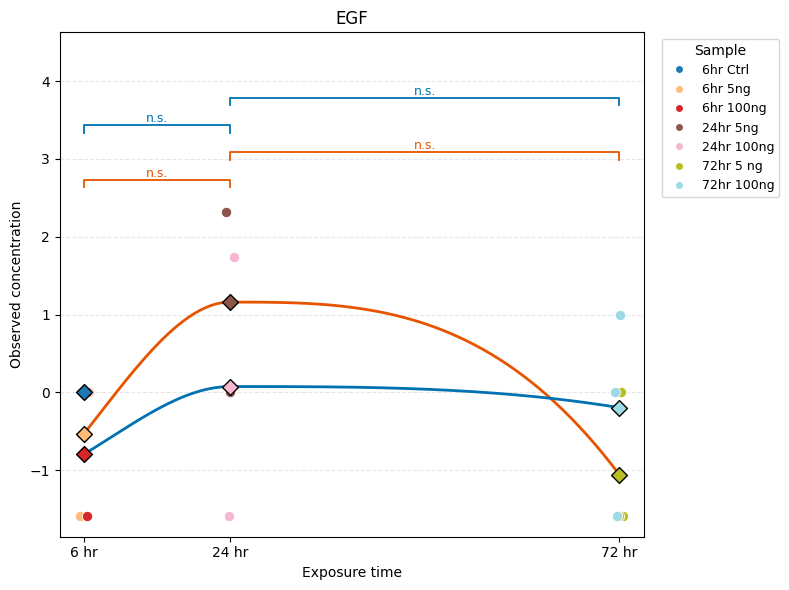

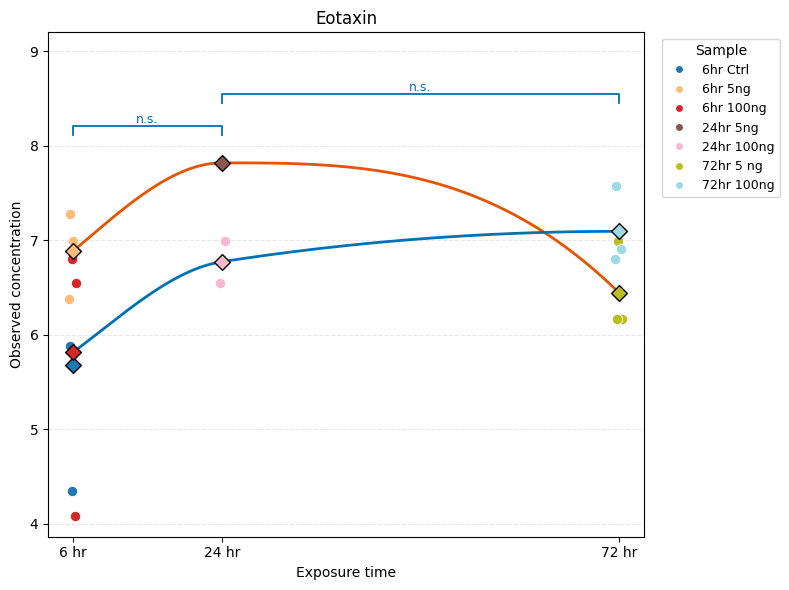

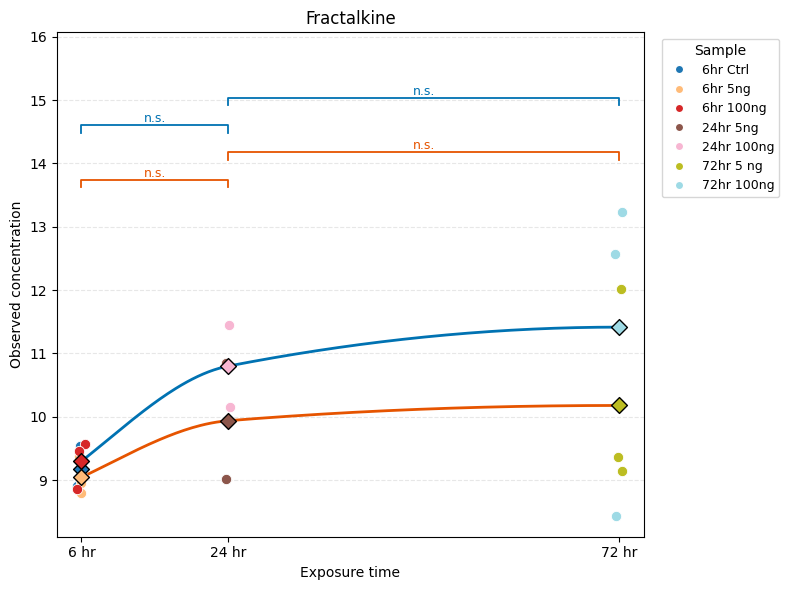

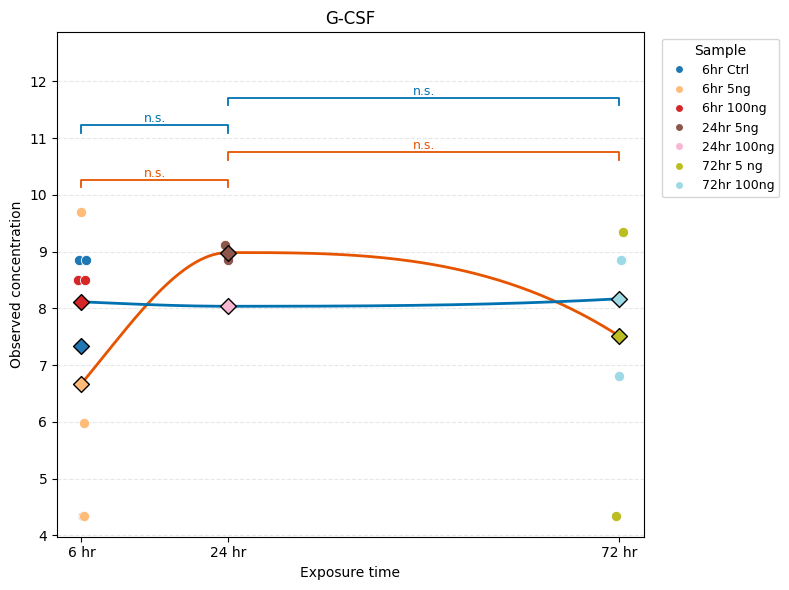

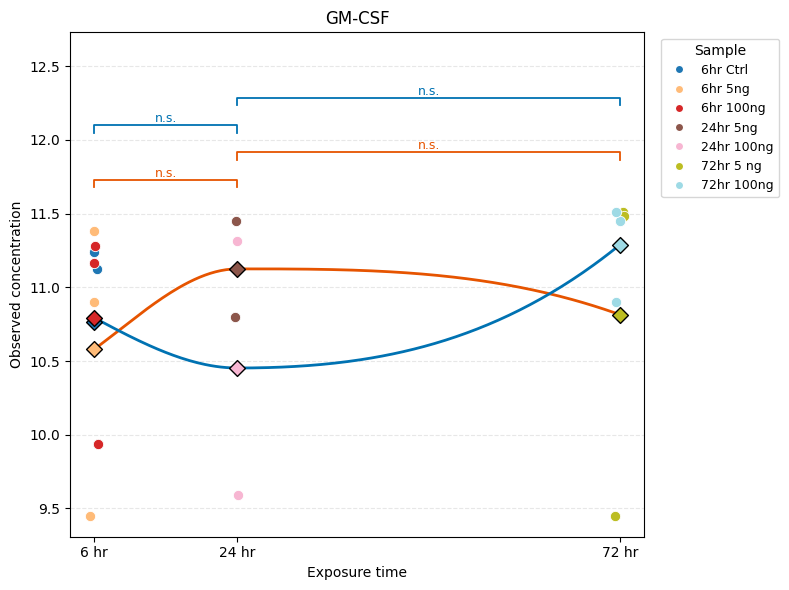

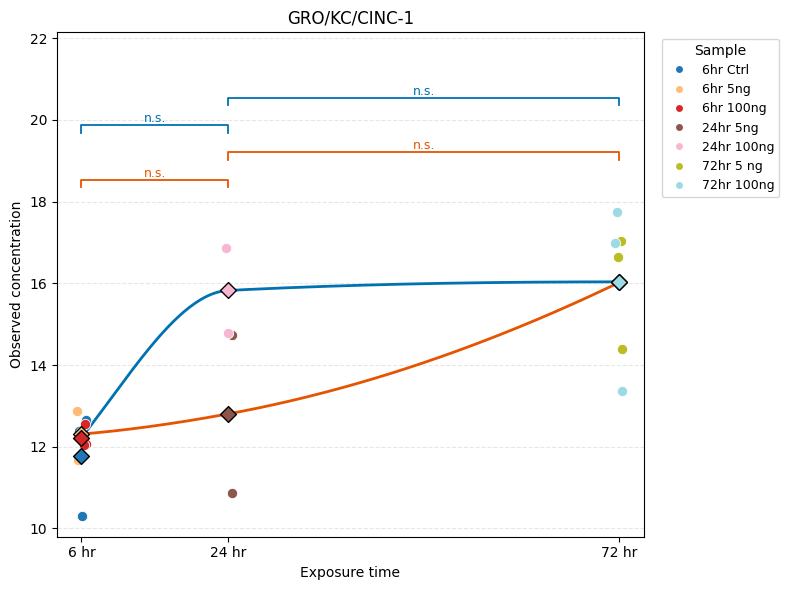

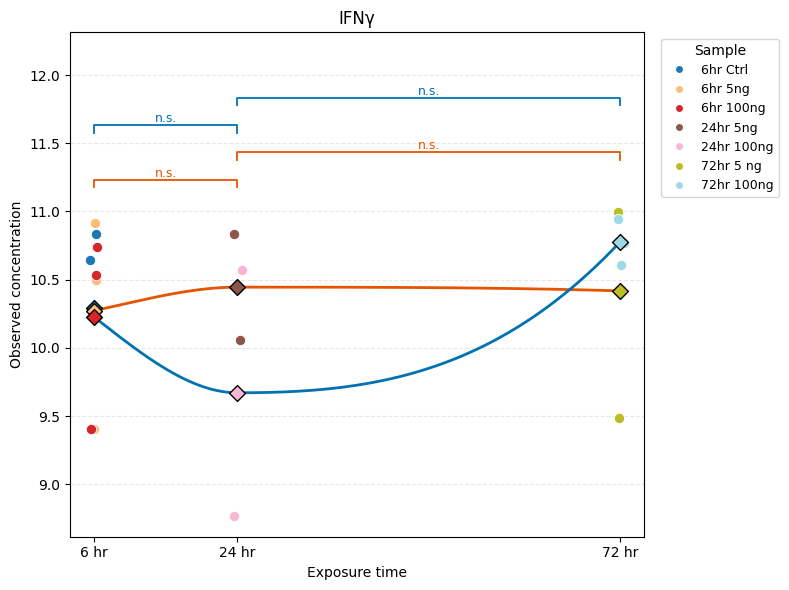

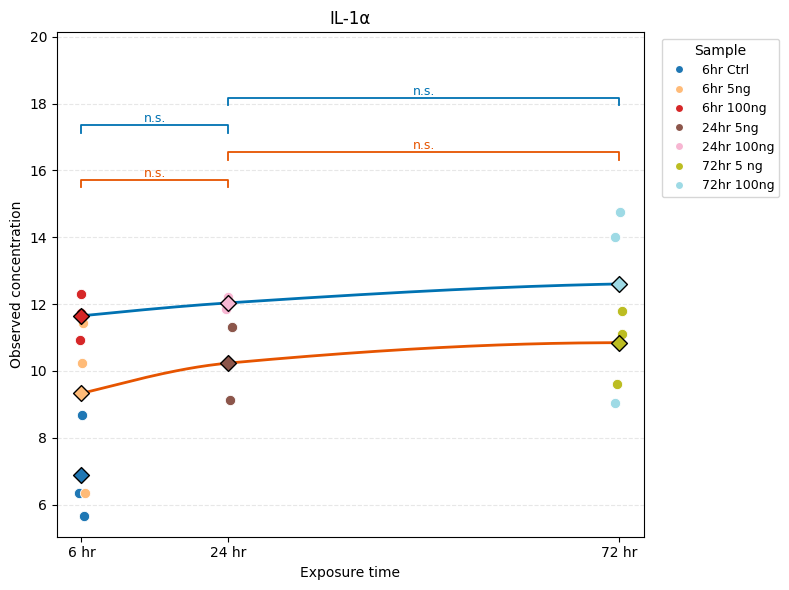

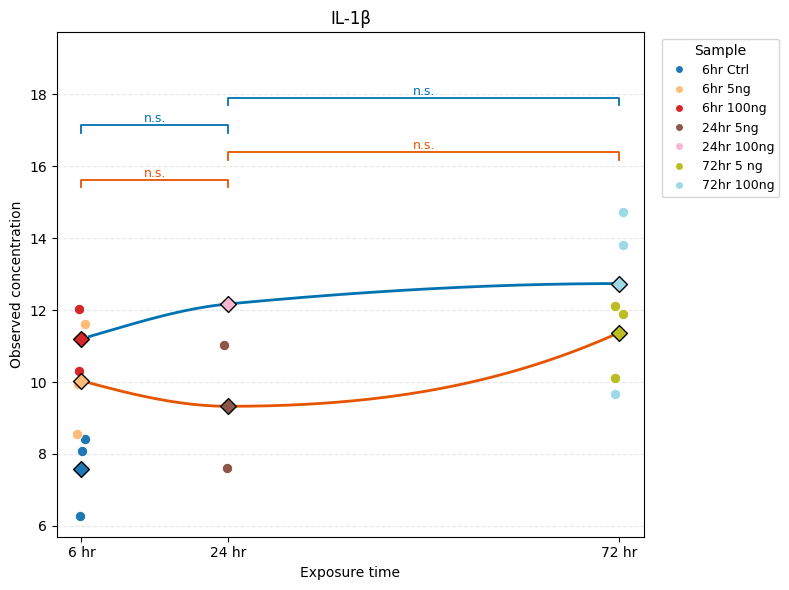

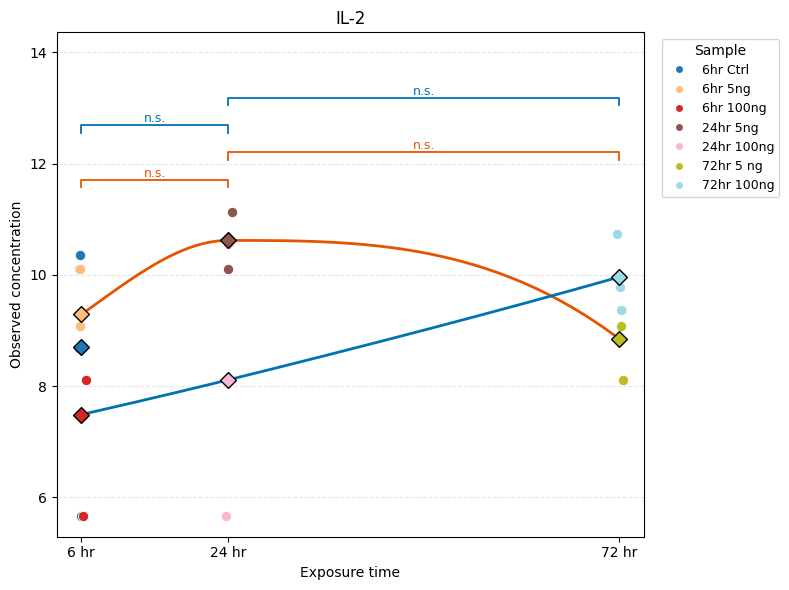

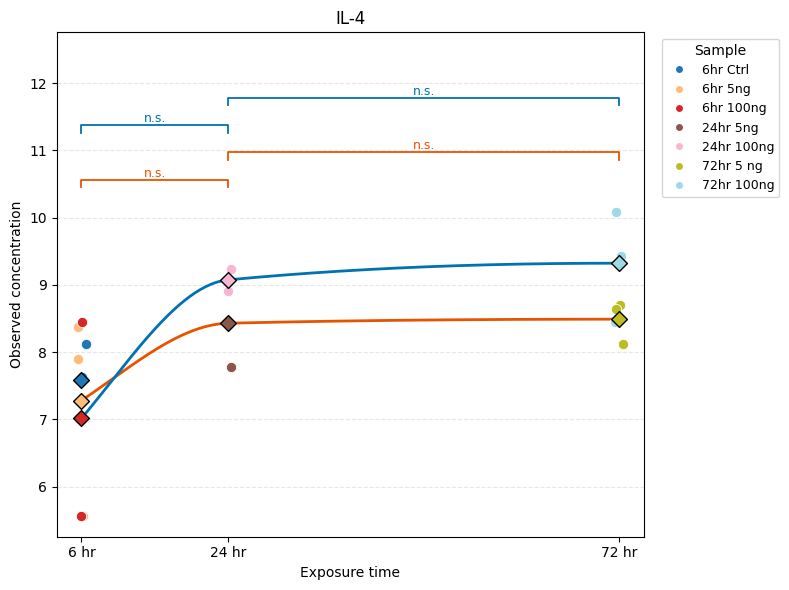

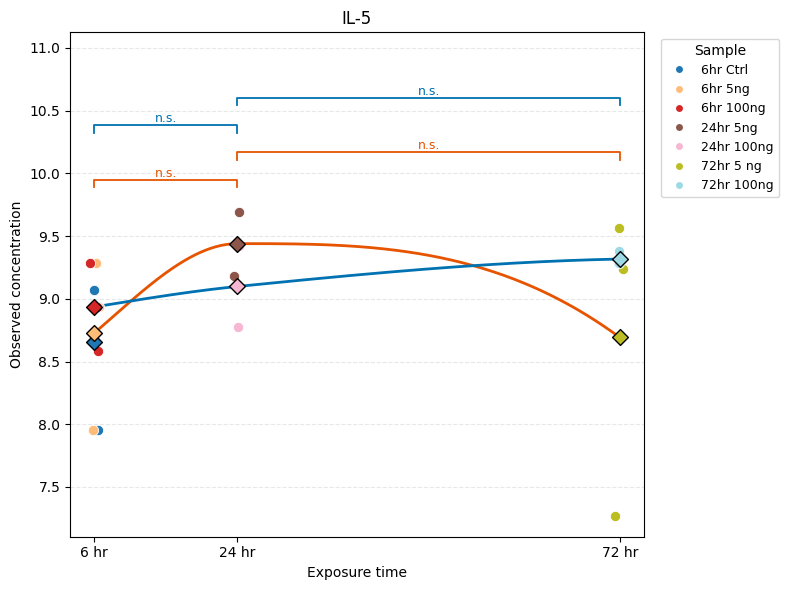

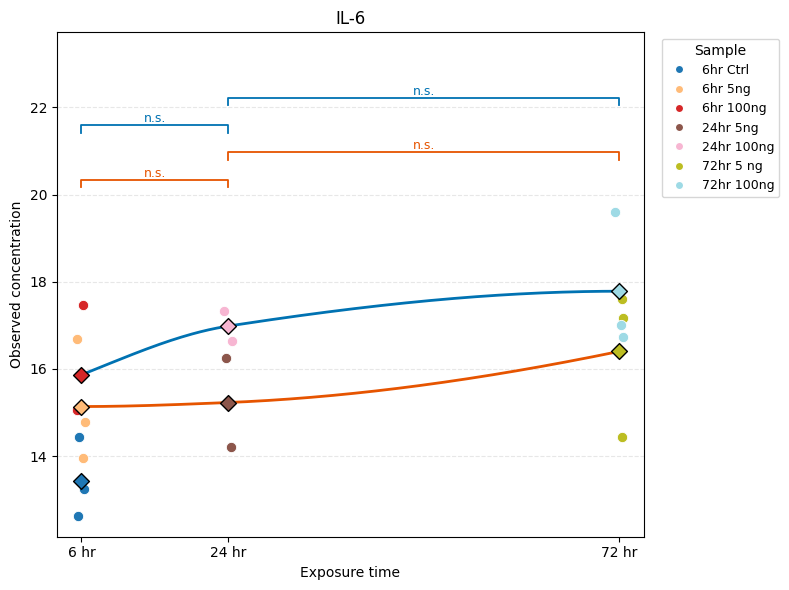

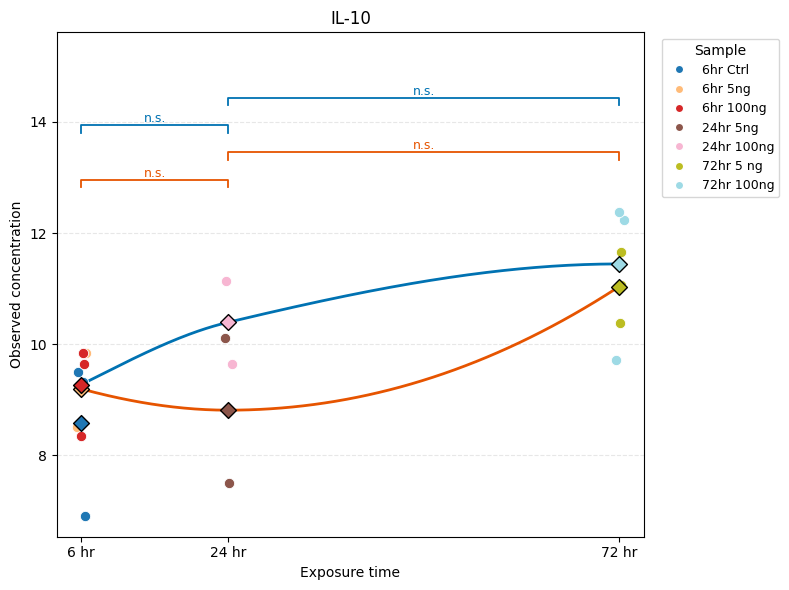

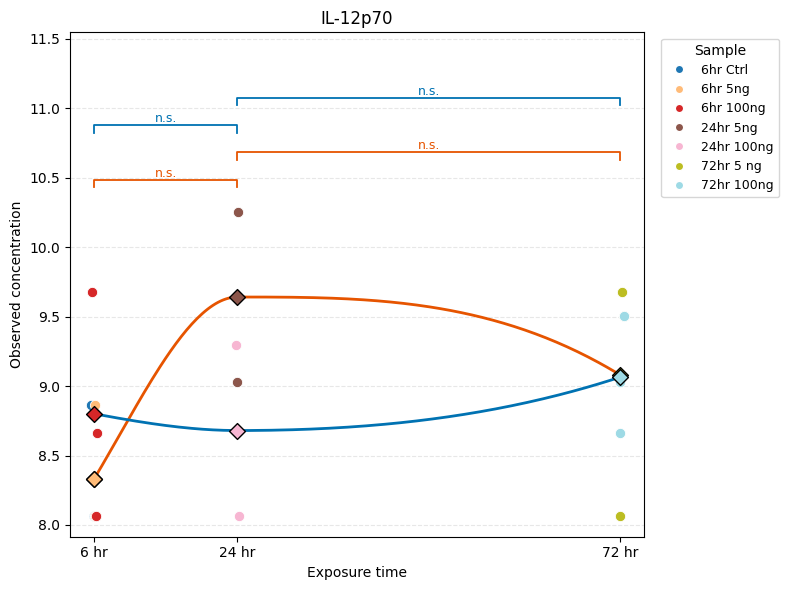

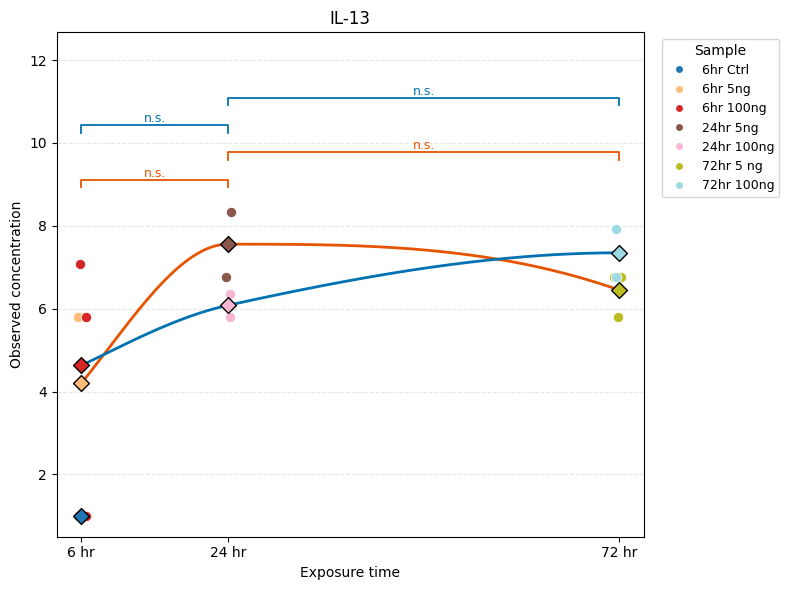

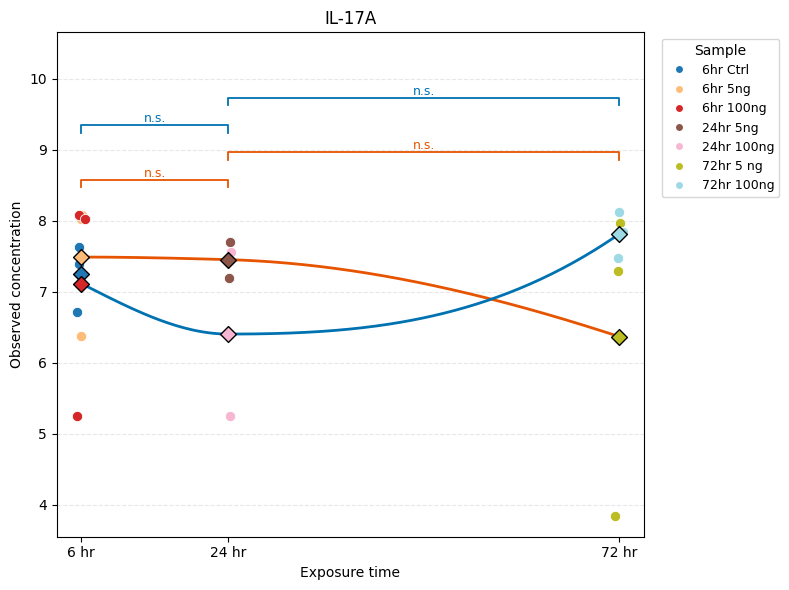

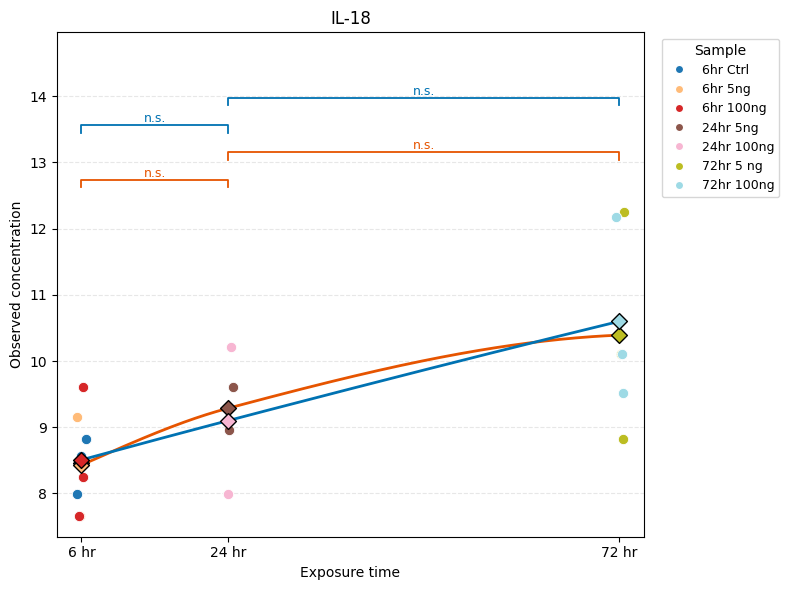

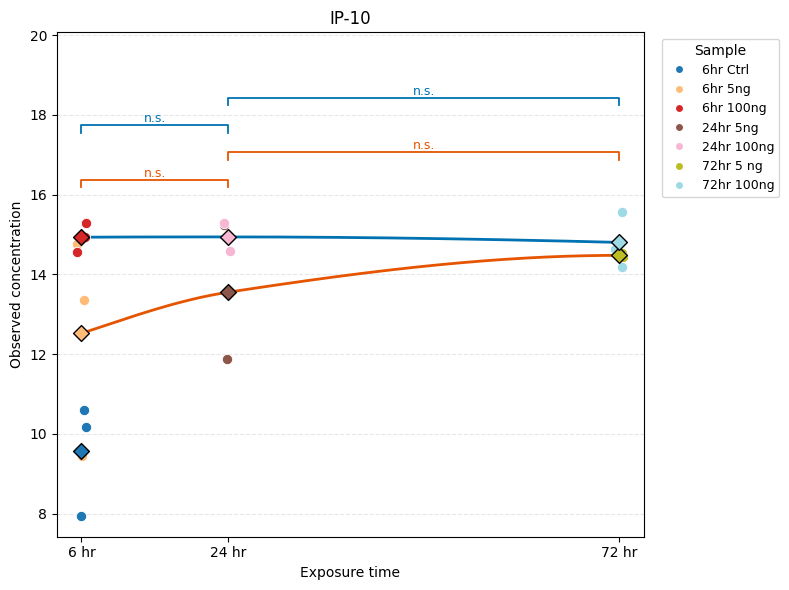

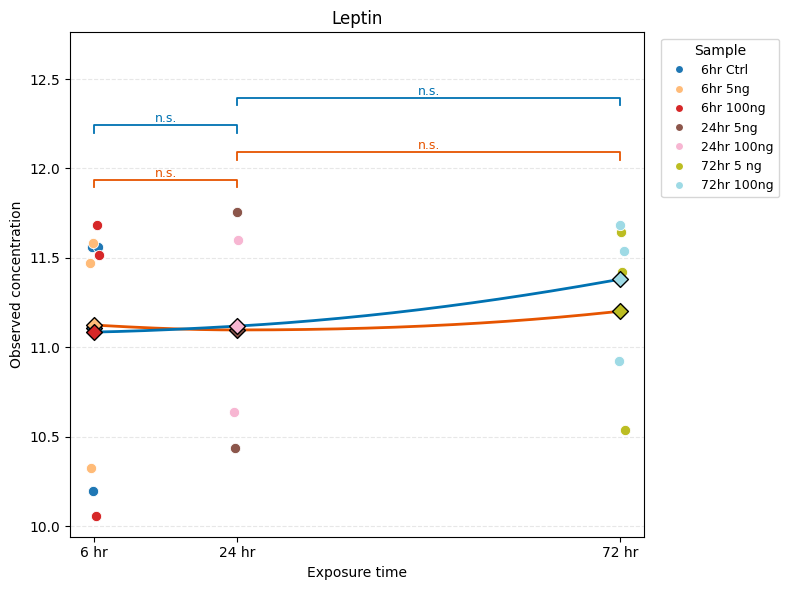

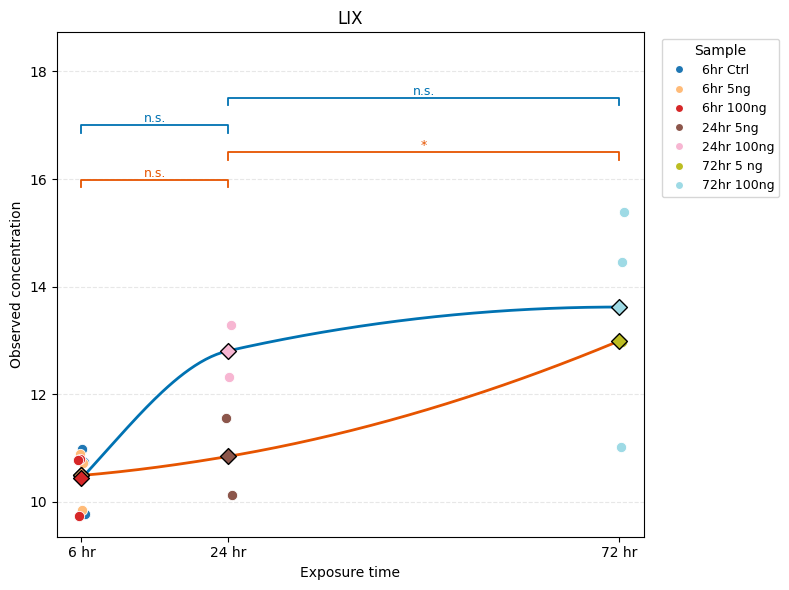

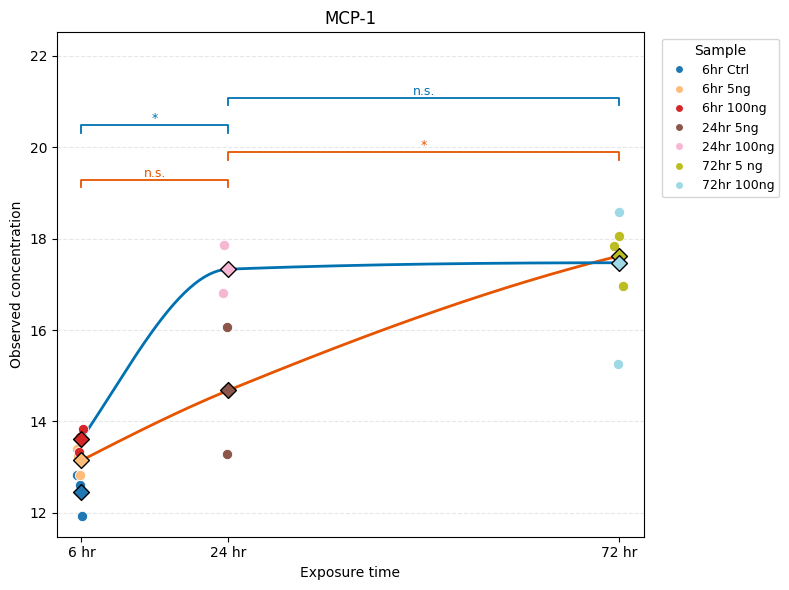

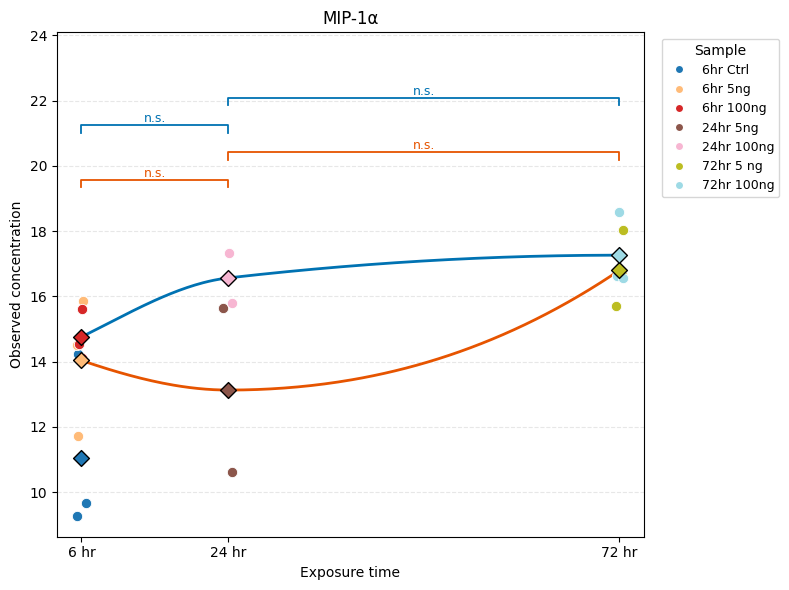

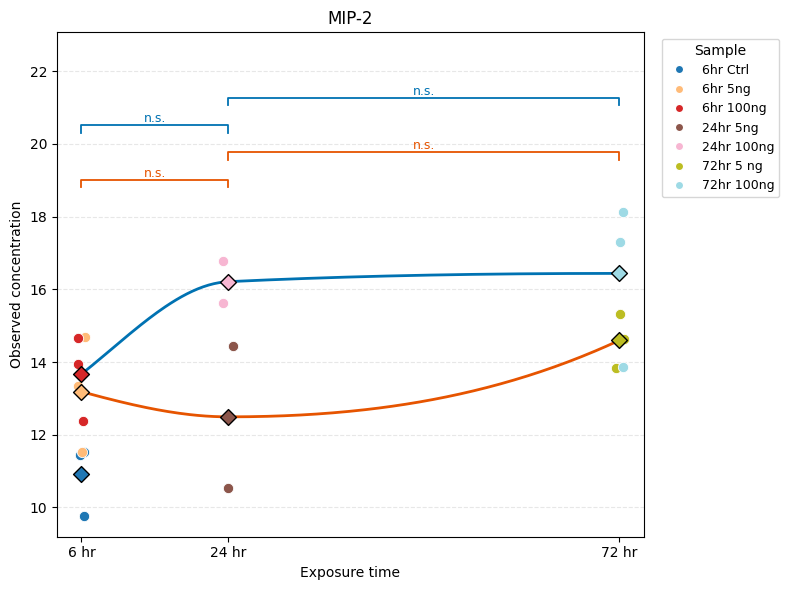

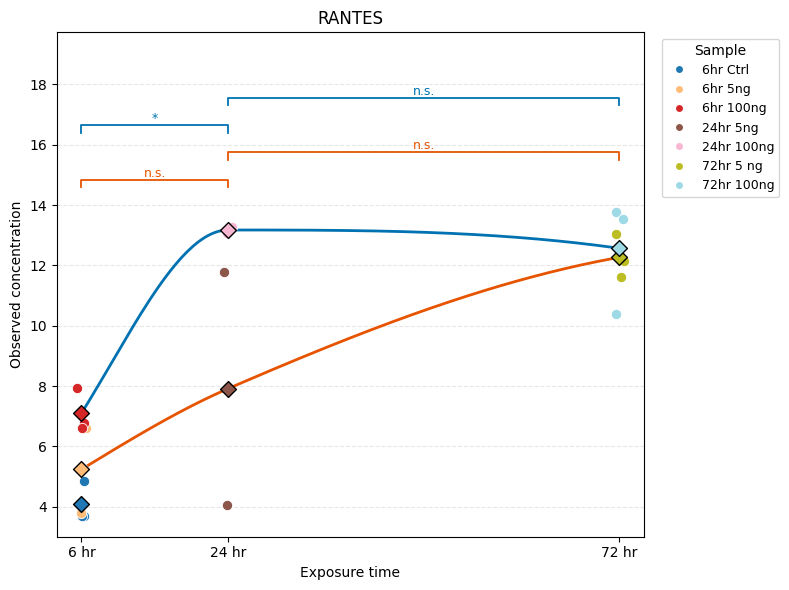

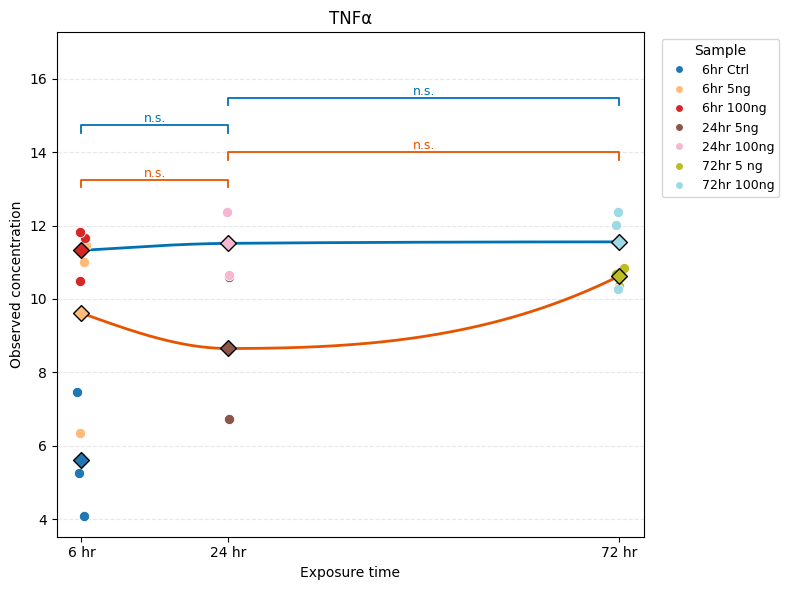

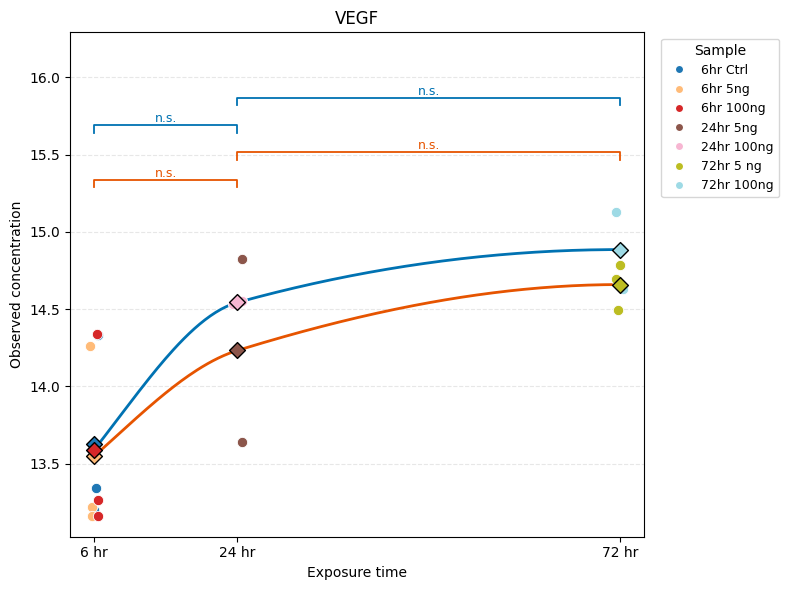

Saved 27 scatter plots and the data workbook to /Users/allisonpickle/Desktop/261007_Cytokine Reanalysis.


,Cytokine,Sample,Time_hr,LPS_ng_mL,mean,std,n
0,EGF,6hr Ctrl,6,NaN,0.000000,0.000000,3
1,Eotaxin,6hr Ctrl,6,NaN,5.677158,1.241461,3
2,Fractalkine,6hr Ctrl,6,NaN,9.167920,0.325779,3
3,G-CSF,6hr Ctrl,6,NaN,7.345585,2.597912,3
4,GM-CSF,6hr Ctrl,6,NaN,10.768158,0.722099,3
...,...,...,...,...,...,...,...
184,MIP-2,72hr 100ng,72,100.0,16.438961,2.258709,3
185,RANTES,72hr 100ng,72,100.0,12.566225,1.896287,3
186,TNFα,72hr 100ng,72,100.0,11.557892,1.115009,3
187,VEGF,72hr 100ng,72,100.0,14.885109,0.249924,3


In [4]:
scatter_file_path = '/Users/allisonpickle/Desktop/261007_Cytokine Reanalysis/Compiled_Cytokines_3BioReps.xlsx'
scatter_long_df, scatter_summary_df, scatter_saved_paths = Plot_Cytokine_Scatter_Plots(
    scatter_file_path, sample_col='B', rep_col='A',
    header_row=16, start_col='F', col_step=3, obs_conc_offset=1,
    sheet_selections=[
        # {'sheet_name': 'NP Analysis', 'header_row': 2,
        #  'data_start_row': 121, 'data_end_row': 129,
        #  'start_col': 'F', 'obs_conc_offset': 1},
        {'sheet_name': '261018 Updated Analysis', 'header_row': 1,
         'data_start_row': 194, 'data_end_row': 235,
         'start_col': 'F', 'obs_conc_offset': 1},
    ],
    samples=[
        "6hr Ctrl",
        "6hr 5ng",
        "6hr 100ng",
        "24hr 5ng",
        "24hr 100ng",
        "72hr 5 ng",
        "72hr 100ng",
    ],
    include_48hr=False, run_statistics=True,
    include_all_samples=True,
    show_mean=True, save_results=True, display_results=True,
)
display(scatter_summary_df)


In [17]:
def plot_cytokine_heatmap(
    file_path,
    sheet_name=0,
    sample_col="B",
    rep_col="A",
    header_row=16,
    start_col="F",
    col_step=3,
    obs_conc_offset=1,
    data_start_row=None,
    data_end_row=None,
    sample_order=None,
    preserve_sample_order=True,
    use_log2fc=False,
    scale_mode=None,          # <-- "none", "log2fc", or "zscore_row". Overrides use_log2fc if set.
    ref_sample=None,
    pseudocount=1e-9,
    cluster_rows=True,
    output_dir=None,
    fontsize_row=7,
    fontsize_col=9,
    sheet_selections=None,
    cytokines=None,
    samples=None,
    run_statistics=True,
    control_sample="6hr Ctrl",
    alpha=0.05,
):
    """
    Builds a cytokine x sample heatmap (mean Obs. Conc. across bio reps) directly from
    the SAME wide-format Excel layout used by Plot_Cytokine_Bar_Charts.
    Exports the heatmap and one raw-concentration bar plot per selected cytokine
    as PNGs. Bar plots use the same selected samples and numeric observations,
    with mean +/- SD, individual observation dots, and distinct Rep counts.
    Technical rows retain equal weight, matching the heatmap's raw means.
    Bars are never scaled. By default, raw biological-replicate means enter
    Kruskal-Wallis and Dunn vs control_sample, with at least 2 numeric reps
    per included group (unequal n is allowed). Technical rows are averaged
    within Sample/Rep for tests only; descriptive bar means remain unchanged.
    Holm adjustment covers all treatment-vs-control contrasts per cytokine;
    BH adjusts valid omnibus p-values across the selected cytokines. Stars
    show Holm-adjusted Dunn p-values, without gating on omnibus significance.
    These asymptotic tests are exploratory at n=2-3 and assume independent
    groups, not matched Rep IDs. Censored values/missing IDs skip testing;
    missing numeric observations are omitted, never imputed. An XLSX records
    counts, p-values, and skip reasons. Set run_statistics=False to disable.
    Keep Cytokine_Heatmap_Statistics.py alongside the notebook. Raw bar plots
    are saved in the output directory's Raw Bar Plots subfolder. Returns unchanged.

    scale_mode options (overrides use_log2fc if provided):
      - "none"        : raw mean Obs. Conc. values (no transform)
      - "log2fc"      : log2 fold-change vs `ref_sample` (per cytokine row)
      - "zscore_row"  : z-score standardization per cytokine row:
                        z = (value - row_mean) / row_std
                        (equivalent to R's scale() applied row-wise / pheatmap's scale="row")

    If scale_mode is None, falls back to use_log2fc (True -> "log2fc", False -> "none").

    Optional sheet_selections is a nonempty list of dictionaries containing
    sheet_name and optional data_start_row/data_end_row (1-based, inclusive).
    Omitted bounds inherit the function's data_start_row/data_end_row settings.
    Each selection may also override header_row (1-based cytokine-name row),
    start_col (Excel column letter), and
    obs_conc_offset (integer column distance from cytokine name to concentration).
    Omitted column settings inherit the function-level defaults. All other
    column settings are shared. Cytokines align by name, not column position;
    pooling and scaling use the combined data from every selected sheet.
    Numeric or duplicate cytokine headers are rejected for combined input.
    Repeat a sheet to select
    disjoint ranges; overlapping ranges are rejected to prevent double-counting.
    Matching sample/cytokine names are pooled across all selected rows before
    scaling. Each valid row has equal weight, not each sheet. Multi-sheet long_df
    includes Sheet and Excel_Row provenance. Without sheet_selections, the
    existing single-sheet behavior and returned columns are unchanged.

    cytokines=None includes all cytokines. Otherwise supply a nonempty list
    of exact, case-sensitive header names (e.g. ["IL-6", "IL-10", "TNFα"]).
    Only those cytokines enter averaging/scaling/clustering and returned long_df.
    Unknown names or selected cytokines with no numeric data raise ValueError.
    With cluster_rows=False, rows follow the list order; otherwise they cluster.

    samples=None includes all samples. Otherwise supply a nonempty list of
    exact, case-sensitive sample names. Both filters apply before averaging,
    scaling, and clustering, and both returned tables contain only this subset.
    With preserve_sample_order=True, columns follow samples list order unless
    sample_order supplies a permutation of that list. X-axis labels show the
    number of distinct Rep IDs with numeric data for each sample. Unknown names or
    samples with no numeric data for the selected cytokines raise ValueError.
    For log2fc, ref_sample must be included. Row z-scores require at least two
    included samples and nonzero variance for a cytokine to remain in the plot.
    """
    import os
    import re
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    import seaborn as sns
    from openpyxl.utils import column_index_from_string

    def _validate_name_list(names, label):
        if names is None:
            return None
        if not isinstance(names, list) or not names:
            raise ValueError(f"{label} must be a nonempty list of names, or None.")
        if any(not isinstance(name, str) or not name.strip() for name in names):
            raise ValueError(f"Each name in {label} must be a nonempty string.")
        names = [name.strip() for name in names]
        if len(set(names)) != len(names):
            raise ValueError(f"{label} must not contain duplicate names.")
        return names

    cytokines = _validate_name_list(cytokines, "cytokines")
    samples = _validate_name_list(samples, "samples")
    if run_statistics:
        if not isinstance(control_sample, str) or not control_sample.strip():
            raise ValueError("control_sample must be a nonempty sample name.")
        control_sample = control_sample.strip()
        if not np.isfinite(alpha) or not 0 < alpha < 1:
            raise ValueError("alpha must be between 0 and 1.")
    if samples is not None and sample_order is not None:
        sample_order = _validate_name_list(sample_order, "sample_order")
        if set(sample_order) != set(samples):
            raise ValueError("When samples is set, sample_order must contain exactly the same sample names.")

    # ---- Resolve scale_mode (backward-compatible with use_log2fc) ----
    if scale_mode is None:
        scale_mode = "log2fc" if use_log2fc else "none"
    valid_modes = {"none", "log2fc", "zscore_row"}
    if scale_mode not in valid_modes:
        raise ValueError(f"scale_mode must be one of {valid_modes}, got '{scale_mode}'.")

    # ---- Resolve output directory ----
    if output_dir is None:
        output_dir = os.path.join(os.path.dirname(os.path.abspath(file_path)), "Cytokine Heatmaps")
    os.makedirs(output_dir, exist_ok=True)

    def _parse_value(v):
        if pd.isna(v):
            return np.nan
        if isinstance(v, (int, float, np.number)):
            return float(v)
        s = str(v).strip()
        if re.match(r"^OOR\s*<", s, flags=re.IGNORECASE):
            return 0.0
        try:
            return float(s)
        except ValueError:
            return np.nan

    records = []
    multi_sheet = sheet_selections is not None
    censored_observations = set()
    selections = sheet_selections if multi_sheet else [{"sheet_name": sheet_name}]
    if not isinstance(selections, list) or not selections:
        raise ValueError("sheet_selections must be a nonempty list of dictionaries.")
    allowed_keys = {"sheet_name", "data_start_row", "data_end_row", "start_col", "obs_conc_offset", "header_row"}
    for selection in selections:
        if not isinstance(selection, dict) or "sheet_name" not in selection:
            raise ValueError("Each sheet selection must be a dictionary containing sheet_name.")
        if set(selection) - allowed_keys:
            raise ValueError(f"Unknown sheet selection keys: {set(selection) - allowed_keys}")

    sample_col_idx = column_index_from_string(sample_col) - 1
    rep_col_idx = column_index_from_string(rep_col) - 1
    if col_step <= 0:
        raise ValueError("col_step must be positive.")
    selected_rows = set()
    source_tags = []
    with pd.ExcelFile(file_path) as workbook:
        sheet_cache = {}
        for selection in selections:
            selected_sheet = selection["sheet_name"]
            if isinstance(selected_sheet, int) and not isinstance(selected_sheet, bool):
                if not 0 <= selected_sheet < len(workbook.sheet_names):
                    raise ValueError(f"Invalid sheet index: {selected_sheet}")
                selected_sheet = workbook.sheet_names[selected_sheet]
            if not isinstance(selected_sheet, str) or selected_sheet not in workbook.sheet_names:
                raise ValueError(f"Unknown sheet {selected_sheet!r}; available: {workbook.sheet_names}")
            selected_start_col = selection.get("start_col", start_col)
            selected_offset = selection.get("obs_conc_offset", obs_conc_offset)
            selected_header_row = selection.get("header_row", header_row)
            if not isinstance(selected_header_row, int) or isinstance(selected_header_row, bool) or selected_header_row < 1:
                raise ValueError(f"header_row must be a positive integer in sheet {selected_sheet!r}.")
            header_row_idx = selected_header_row - 1
            if not isinstance(selected_start_col, str) or not re.fullmatch(r"[A-Za-z]+", selected_start_col):
                raise ValueError(f"start_col must be an Excel column letter in sheet {selected_sheet!r}.")
            start_col_idx = column_index_from_string(selected_start_col) - 1
            if not isinstance(selected_offset, int) or isinstance(selected_offset, bool):
                raise ValueError(f"obs_conc_offset must be an integer in sheet {selected_sheet!r}.")
            if selected_sheet not in sheet_cache:
                sheet_cache[selected_sheet] = pd.read_excel(workbook, sheet_name=selected_sheet, header=None)
            raw = sheet_cache[selected_sheet]
            n_rows, n_cols = raw.shape
            if not 0 <= header_row_idx < n_rows or sample_col_idx >= n_cols:
                raise ValueError(f"Invalid header_row or sample_col for sheet {selected_sheet!r}.")
            cytokine_names = {}
            for col_idx in range(start_col_idx, n_cols, col_step):
                name = raw.iat[header_row_idx, col_idx]
                if pd.notna(name) and str(name).strip():
                    if multi_sheet and (isinstance(name, (int, float, np.number))
                                        or re.fullmatch(r"[+-]?(?:\d+(?:\.\d*)?|\.\d+)(?:[eE][+-]?\d+)?", str(name).strip())):
                        raise ValueError(f"Numeric cytokine header {name!r} in sheet {selected_sheet!r}, row {selected_header_row}. "
                                         "Set this selection's header_row to the row containing cytokine names.")
                    cytokine_names[col_idx] = str(name).strip()
            if not cytokine_names:
                raise ValueError(f"No cytokine names found in sheet {selected_sheet!r} at row {selected_header_row}.")
            if multi_sheet and len(set(cytokine_names.values())) != len(cytokine_names):
                raise ValueError(f"Duplicate cytokine names in sheet {selected_sheet!r}, row {selected_header_row}; check header/column settings.")
            print(f"Sheet {selected_sheet!r}: found {len(cytokine_names)} cytokine(s): {list(cytokine_names.values())}")

            start_row = selection.get("data_start_row", data_start_row)
            end_row = selection.get("data_end_row", data_end_row)
            start_row = selected_header_row + 1 if start_row is None else start_row
            end_row = n_rows if end_row is None else end_row
            for bound in (start_row, end_row):
                if not isinstance(bound, int) or isinstance(bound, bool):
                    raise ValueError(f"Row bounds must be integers in sheet {selected_sheet!r}.")
            if not 1 <= start_row <= n_rows or end_row < start_row:
                raise ValueError(f"Invalid rows {start_row}-{end_row} in sheet {selected_sheet!r} ({n_rows} rows).")
            if multi_sheet and end_row > n_rows:
                raise ValueError(f"End row {end_row} exceeds sheet {selected_sheet!r} ({n_rows} rows).")
            end_row = min(end_row, n_rows)
            row_keys = {(selected_sheet, row) for row in range(start_row, end_row + 1)}
            if selected_rows & row_keys:
                raise ValueError(f"Overlapping row selections in sheet {selected_sheet!r}.")
            selected_rows.update(row_keys)
            source_tags.append(re.sub(r"[^A-Za-z0-9]+", "_", selected_sheet)
                               + f"_rows{start_row}-{end_row}_header{selected_header_row}_start{selected_start_col.upper()}_offset{selected_offset}")
            print(f"Reading sheet {selected_sheet!r}, rows {start_row}-{end_row} (1-indexed, inclusive)")
            records_before = len(records)
            for row_idx in range(start_row - 1, end_row):
                samp = raw.iat[row_idx, sample_col_idx]
                rep = raw.iat[row_idx, rep_col_idx] if rep_col_idx < n_cols else None
                if pd.isna(samp) or not str(samp).strip():
                    continue
                samp = str(samp).strip()
                rep = str(rep).strip() if pd.notna(rep) else None
                for col_idx, cytokine in cytokine_names.items():
                    data_col_idx = col_idx + selected_offset
                    if not 0 <= data_col_idx < n_cols:
                        if multi_sheet:
                            raise ValueError(f"Missing concentration column for {cytokine!r} in sheet {selected_sheet!r}.")
                        continue
                    val = _parse_value(raw.iat[row_idx, data_col_idx])
                    if re.match(r"^OOR\s*<", str(raw.iat[row_idx, data_col_idx]).strip(), re.I):
                        censored_observations.add((samp, rep, cytokine))
                    record = {"Sample": samp, "Rep": rep, "Cytokine": cytokine, "Obs_Conc": val}
                    if multi_sheet:
                        record.update(Sheet=selected_sheet, Excel_Row=row_idx + 1)
                    records.append(record)
            if multi_sheet and len(records) == records_before:
                raise ValueError(f"No data parsed from sheet {selected_sheet!r}, rows {start_row}-{end_row}.")
            if multi_sheet and not any(pd.notna(record["Obs_Conc"]) for record in records[records_before:]):
                raise ValueError(f"No numeric concentrations in sheet {selected_sheet!r}, rows {start_row}-{end_row}.")

    long_df = pd.DataFrame(records)
    if long_df.empty:
        raise ValueError("No data rows were parsed. Check row/column settings.")

    if samples is not None:
        available_samples = sorted(long_df["Sample"].unique())
        unknown_samples = [name for name in samples if name not in available_samples]
        if unknown_samples:
            raise ValueError(f"Unknown samples: {unknown_samples}. Available samples: {available_samples}")
        long_df = long_df.loc[long_df["Sample"].isin(samples)].reset_index(drop=True)
        print(f"Analyzing selected samples: {samples}")

    if cytokines is not None:
        available = sorted(long_df["Cytokine"].unique())
        unknown = [name for name in cytokines if name not in available]
        if unknown:
            raise ValueError(f"Unknown cytokines: {unknown}. Available cytokines: {available}")
        long_df = long_df.loc[long_df["Cytokine"].isin(cytokines)].reset_index(drop=True)
        numeric_names = set(long_df.loc[long_df["Obs_Conc"].notna(), "Cytokine"])
        missing = [name for name in cytokines if name not in numeric_names]
        if missing:
            raise ValueError(f"Selected cytokines have no numeric concentrations in the selected rows: {missing}")
        print(f"Analyzing selected cytokines: {cytokines}")

    if samples is not None:
        numeric_samples = set(long_df.loc[long_df["Obs_Conc"].notna(), "Sample"])
        missing_samples = [name for name in samples if name not in numeric_samples]
        if missing_samples:
            raise ValueError(f"Selected samples have no numeric concentrations for the included cytokines: {missing_samples}")
        if scale_mode == "zscore_row" and len(samples) < 2:
            raise ValueError("Row z-scores require at least two included samples; use scale_mode='none' for one sample.")

    print(f"Parsed {len(long_df)} data points across {long_df['Sample'].nunique()} sample(s) "
          f"and {long_df['Cytokine'].nunique()} cytokine(s).")

    long_df_valid = long_df.dropna(subset=["Obs_Conc"])
    replicate_counts = long_df_valid.groupby("Sample")["Rep"].nunique()

    # ---- Collapse bio reps -> mean per Sample x Cytokine ----
    mean_df = (
        long_df_valid
        .groupby(["Cytokine", "Sample"], as_index=False)["Obs_Conc"]
        .mean()
    )

    # Pivot to Cytokine (rows) x Sample (cols)
    heatmap_data = mean_df.pivot(index="Cytokine", columns="Sample", values="Obs_Conc")
    if cytokines is not None:
        heatmap_data = heatmap_data.reindex(cytokines)

    # ---- Determine sample order ----
    if sample_order is None:
        original_sample_order = samples if samples is not None else list(dict.fromkeys(long_df["Sample"]))
    else:
        original_sample_order = sample_order

    if run_statistics and control_sample not in heatmap_data.columns:
        raise ValueError(f"Control {control_sample!r} must be included in the selected samples; otherwise set run_statistics=False.")

    # =========================================================================
    # Apply scaling mode: none / log2fc / zscore_row
    # =========================================================================
    if scale_mode == "log2fc":
        if ref_sample is None or ref_sample not in heatmap_data.columns:
            raise ValueError(
                f"ref_sample '{ref_sample}' not found. Available samples: {list(heatmap_data.columns)}"
            )
        ref_vals = heatmap_data[ref_sample].astype(float)
        heatmap_data = np.log2((heatmap_data.astype(float) + pseudocount).div(ref_vals + pseudocount, axis=0))
        heatmap_data[ref_sample] = 0.0
        heatmap_title = f"log2 fold-change vs {ref_sample}"
        value_tag = "log2FC"

    elif scale_mode == "zscore_row":
        # z = (value - row_mean) / row_std, computed independently per cytokine (row)
        row_means = heatmap_data.mean(axis=1, skipna=True)
        row_stds = heatmap_data.std(axis=1, skipna=True, ddof=1)

        # Avoid divide-by-zero for cytokines with no variance across samples
        row_stds_safe = row_stds.replace(0, np.nan)

        heatmap_data = heatmap_data.sub(row_means, axis=0).div(row_stds_safe, axis=0)

        n_flat = row_stds.eq(0).sum()
        if n_flat > 0:
            print(f"  ⚠ {n_flat} cytokine(s) had zero variance across samples "
                  f"(all values equal) and could not be z-scored; they will appear blank (NaN).")

        heatmap_title = "Row Z-score (per cytokine, across samples)"
        value_tag = "zscoreRow"

    else:  # "none"
        heatmap_title = "Raw values (mean of bio reps)"
        value_tag = "raw"

    # ---- NEW: Drop any rows that are entirely NaN, and fill remaining scattered NaNs ----
    # (scipy's hierarchical clustering cannot handle NaN/inf values)
    n_rows_before = heatmap_data.shape[0]
    heatmap_data = heatmap_data.dropna(axis=0, how="all")  # drop fully-NaN cytokine rows
    n_dropped = n_rows_before - heatmap_data.shape[0]
    if n_dropped > 0:
        print(f"  ⚠ Dropped {n_dropped} cytokine row(s) that were entirely NaN "
              f"(zero variance or all missing data) before clustering.")

    if heatmap_data.isna().any().any():
        n_remaining_na = int(heatmap_data.isna().sum().sum())
        print(f"  ⚠ {n_remaining_na} remaining NaN cell(s) found; filling with 0 "
              f"to allow clustering (these will appear as the midpoint color).")
        heatmap_data = heatmap_data.fillna(0)

    if heatmap_data.shape[0] == 0:
        raise ValueError("No cytokine rows remain after dropping all-NaN rows. "
                          "Check your data range and scale_mode settings.")

    # ---- Sample (column) order ----
    if preserve_sample_order:
        ordered_cols = [s for s in original_sample_order if s in heatmap_data.columns]
        heatmap_data = heatmap_data[ordered_cols]
        cluster_cols = False
        order_tag = "_ORIGINAL_ORDER"
        print("Using ORIGINAL sample order")
    else:
        cluster_cols = True
        order_tag = "_CLUSTERED"
        print("Using HIERARCHICAL CLUSTERING for sample order")

    # ---- Output file paths ----
    base_name = os.path.splitext(os.path.basename(file_path))[0]
    sheet_tag = re.sub(r"[^A-Za-z0-9]+", "_", str(sheet_name))
    row_tag = f"_rows{data_start_row}-{data_end_row}" if (data_start_row or data_end_row) else ""
    base_tag = f"{base_name}__{sheet_tag}{row_tag}"
    if multi_sheet:
        import hashlib
        selection_id = hashlib.sha256(repr(source_tags).encode("utf-8")).hexdigest()[:10]
        base_tag = f"{base_name}__combined_{len(selections)}selections_{selection_id}"
        print("Combined sources: " + "; ".join(source_tags))
    if cytokines is not None:
        import hashlib
        cytokine_id = hashlib.sha256(repr(cytokines).encode("utf-8")).hexdigest()[:10]
        base_tag += f"__selected{len(cytokines)}_{cytokine_id}"
    if samples is not None:
        import hashlib
        sample_id = hashlib.sha256(repr(samples).encode("utf-8")).hexdigest()[:10]
        base_tag += f"__samples{len(samples)}_{sample_id}"

    heatmap_png = os.path.join(output_dir, f"{base_tag}__heatmap_{value_tag}{order_tag}.png")

    # ---- Color scale ----
    # For z-score, cap the symmetric range at ±3 SD (conventional) unless data range is smaller.
    if scale_mode == "zscore_row":
        finite_vals = heatmap_data.values[np.isfinite(heatmap_data.values)]
        lim = np.nanmax(np.abs(finite_vals)) if finite_vals.size > 0 else 3.0
        lim = min(lim, 3.0)
    else:
        lim = np.nanmax(np.abs(heatmap_data.values))

    if lim == 0 or np.isnan(lim):
        lim = 1.0

    g = sns.clustermap(
        heatmap_data,
        cmap=sns.diverging_palette(240, 10, as_cmap=True),
        vmin=-lim,
        vmax=lim,
        center=0,
        row_cluster=cluster_rows and heatmap_data.shape[0] > 1,
        col_cluster=cluster_cols and heatmap_data.shape[1] > 1,
        figsize=(max(8, heatmap_data.shape[1] * 0.6), max(6, heatmap_data.shape[0] * 0.3)),
        xticklabels=True,
        yticklabels=True,
        dendrogram_ratio=(0.1, 0.1),
        cbar_pos=(1.02, 0.3, 0.03, 0.4),  # moved to the right of the plot
    )

    sample_labels = [
        f"{label.get_text()}\n(n={replicate_counts.get(label.get_text(), 0)})"
        for label in g.ax_heatmap.get_xticklabels()
    ]
    g.ax_heatmap.set_xticklabels(
        sample_labels, rotation=45, ha="right", fontsize=fontsize_col
    )
    g.ax_heatmap.set_yticklabels(
        g.ax_heatmap.get_yticklabels(), rotation=0, fontsize=fontsize_row
    )
    colorbar_title = {
        "none": "Mean conc.",
        "log2fc": "log2FC",
        "zscore_row": "Z-score",
    }[scale_mode]
    g.cax.set_ylabel("")
    g.cax.set_title(colorbar_title, fontsize=fontsize_col, pad=8)
    g.fig.suptitle(heatmap_title, y=1.02, fontsize=14)

    g.savefig(heatmap_png, dpi=200, bbox_inches="tight")
    plt.close(g.fig)

    print(f"Heatmap exported to:\n  {heatmap_png}")

    bar_output_dir = os.path.join(output_dir, "Raw Bar Plots")
    os.makedirs(bar_output_dir, exist_ok=True)
    bar_samples = list(g.data2d.columns)
    bar_cytokines = cytokines if cytokines is not None else list(mean_df["Cytokine"].unique())
    if run_statistics:
        import importlib.util
        from pathlib import Path
        candidates = [base / filename for base in [Path.cwd(), *Path.cwd().parents]
                      for filename in ("Cytokine_Heatmap_Statistics.py", "Cytokine Analysis/Cytokine_Heatmap_Statistics.py")]
        module_path = next((path for path in candidates if path.is_file()), None)
        if module_path is None:
            raise FileNotFoundError("Keep Cytokine_Heatmap_Statistics.py alongside the notebook and run from its folder or the workspace root.")
        spec = importlib.util.spec_from_file_location("_heatmap_statistics", module_path)
        if spec is None or spec.loader is None:
            raise ImportError(f"Could not load {module_path}.")
        statistics_module = importlib.util.module_from_spec(spec)
        spec.loader.exec_module(statistics_module)
        print("Exploratory Kruskal-Wallis / Dunn tests: independent groups, >=2 numeric bio reps; asymptotic p-values may be inaccurate at n=2-3.")
        bio_points, kw_results, dunn_results = statistics_module.analyze_heatmap_groups(
            long_df, bar_samples, bar_cytokines, control_sample, alpha, censored_observations,
        )
        statistics_path = Path(bar_output_dir) / f"{base_tag}__Kruskal_Wallis_Results.xlsx"
        statistics_module.export_heatmap_statistics(
            statistics_path, long_df, bio_points, kw_results, dunn_results, control_sample, alpha,
        )
        print(f"Statistics exported to:\n  {statistics_path}")
    x_positions = np.arange(len(bar_samples))
    for index, cytokine in enumerate(bar_cytokines, start=1):
        observations = long_df_valid.loc[long_df_valid["Cytokine"].eq(cytokine)]
        summary = observations.groupby("Sample")["Obs_Conc"].agg(["mean", "std"])
        summary = summary.reindex(bar_samples)
        counts = observations.groupby("Sample")["Rep"].nunique()
        fig, ax = plt.subplots(figsize=(max(8, len(bar_samples)), 5))
        try:
            ax.bar(x_positions, summary["mean"], color="skyblue", edgecolor="black", zorder=1)
            has_sd = summary["std"].notna().to_numpy()
            if has_sd.any():
                ax.errorbar(x_positions[has_sd], summary.loc[has_sd, "mean"],
                            yerr=summary.loc[has_sd, "std"], fmt="none",
                            color="black", capsize=4, zorder=2)
            for x, sample in enumerate(bar_samples):
                values = observations.loc[observations["Sample"].eq(sample), "Obs_Conc"].to_numpy()
                offsets = np.linspace(-0.15, 0.15, len(values)) if len(values) > 1 else np.zeros(len(values))
                ax.scatter(x + offsets, values, color="black", s=30, zorder=3)
            ax.set_xticks(x_positions)
            ax.set_xticklabels([f"{sample}\n(n={counts.get(sample, 0)})" for sample in bar_samples],
                               rotation=45, ha="right", fontsize=fontsize_col)
            ax.set_ylabel("Obs. Conc. (mean +/- SD)")
            ax.set_title(cytokine)
            ax.axhline(0, color="0.7", linewidth=0.7, zorder=0)
            if run_statistics:
                statistics_module.annotate_heatmap_bar(
                    ax, cytokine, bar_samples, kw_results, dunn_results, control_sample,
                )
            fig.tight_layout()
            safe_name = re.sub(r"[^\w-]+", "_", cytokine).strip("_")
            bar_path = os.path.join(bar_output_dir, f"{base_tag}__bar_{index:02d}_{safe_name}_raw.png")
            fig.savefig(bar_path, dpi=300, bbox_inches="tight")
        finally:
            plt.close(fig)
    print(f"Exported {len(bar_cytokines)} raw-concentration bar plots to:\n  {bar_output_dir}")

    return heatmap_data, long_df


# ================================================================================
# EXAMPLE USAGE
# ================================================================================
file_path = "/Users/allisonpickle/Desktop/261007_Cytokine Reanalysis/Compiled_Cytokines_3BioReps.xlsx"  # <-- CHANGE ME

heatmap_data, long_df = plot_cytokine_heatmap(
    file_path,
    sheet_selections=[
        {
            "sheet_name": "261018 Updated Analysis",
            "header_row": 1,
            "data_start_row": 194,
            "data_end_row": 235,
            "start_col": "F",
            "obs_conc_offset": 1,
        },
    ],
    preserve_sample_order=True,
    scale_mode="zscore_row",
    run_statistics=True, control_sample="6hr Ctrl", alpha=0.05,
    cytokines= ["Fractalkine", "IL-1α", "IL-1β", "IL-6", "IL-10", "TNFα"],  # Example: ["IL-6", "IL-10", "TNFα"]
    samples=[
        "6hr Ctrl",
        "6hr 100ng",
        "24hr 100ng",
        "10w3",
        "10 uM w3, 100ng LPS 24hr"
        # "2mM PD",
        # "2mM PD, 100ng LPS 24hr"
    ],
    cluster_rows=True,
    sample_col="B",
    rep_col="A",
    header_row=16,
    start_col="F",
    col_step=3,
    obs_conc_offset=1

)

Sheet '261018 Updated Analysis': found 27 cytokine(s): ['EGF', 'Eotaxin', 'Fractalkine', 'G-CSF', 'GM-CSF', 'GRO/KC/CINC-1', 'IFNγ', 'IL-1α', 'IL-1β', 'IL-2', 'IL-4', 'IL-5', 'IL-6', 'IL-10', 'IL-12p70', 'IL-13', 'IL-17A', 'IL-18', 'IP-10', 'Leptin', 'LIX', 'MCP-1', 'MIP-1α', 'MIP-2', 'RANTES', 'TNFα', 'VEGF']
Reading sheet '261018 Updated Analysis', rows 194-235 (1-indexed, inclusive)
Analyzing selected samples: ['6hr Ctrl', '6hr 100ng', '24hr 100ng', '10w3', '10 uM w3, 100ng LPS 24hr']
Analyzing selected cytokines: ['Fractalkine', 'IL-1α', 'IL-1β', 'IL-6', 'IL-10', 'TNFα']
Parsed 90 data points across 5 sample(s) and 6 cytokine(s).
Using ORIGINAL sample order
Combined sources: 261018_Updated_Analysis_rows194-235_header1_startF_offset1
Heatmap exported to:
  /Users/allisonpickle/Desktop/261007_Cytokine Reanalysis/Cytokine Heatmaps/Compiled_Cytokines_3BioReps__combined_1selections_c5d684e9cc__selected6_c80996e5df__samples5_6e192b7322__heatmap_zscoreRow_ORIGINAL_ORDER.png
Exploratory Kr

## Cytokine timecourses with microglial morphology

**Morphology time selection:** Set `morphology_timepoints=[6, 24, 48, 72, 96]` (or any nonempty subset, in hours) in the final call. This independently selects morphology timepoints from plain `Treatment` labels such as `96hr_100ng`, even when no cytokine observations exist at that time. Cytokine data and curves remain unchanged; the shared x-axis extends to include morphology-only times. Only 5/100 ng/mL doses present in the selected cytokine data are included. `samples` selects cytokine samples; explicit morphology time selection can add other times for those doses. Missing requested morphology hours are reported per CSV. Set `morphology_timepoints=None` to retain the previous behavior (morphology only for matching cytokine samples). The selection applies to raw/ln individual plots and all compilations; returned morphology data include only selected times. Re-running with another selection overwrites the same plot filenames. When times are explicitly selected, this overrides the older cytokine-matching-only description below.

**Side-by-side compilations:** Saving creates compilations only for **ln Area, ln Perimeter, ln AUC, and raw Circularity**, matching the CSV stems `Area (µm²)`, `Perimeter (µm)`, `AUC`, and `Circularity` exactly. Convex-hull metrics and other morphology metrics are excluded from compilations; all individual raw/ln plots remain unchanged. Each of these four metrics gets three views: 5 ng/mL, 100 ng/mL, and combined-dose. Each compilation places all selected cytokines horizontally in the `cytokines` list order (six panels with the example selection), preserving each plot and legend at full resolution. Filenames are `Compilation_<metric index>_<metric>__<dose view>__morphology_ln.png`, or `__morphology_raw.png` for Circularity, in the same output folder. Only panels generated by the current call are included; missing-data skips are reported above, so a compilation can contain fewer panels. Compilation paths are appended to the returned saved paths. With eight metrics, the total is **300 PNGs: 288 individual plots + 12 selected compilations**. Older compilation files are not automatically deleted.

**Raw + ln morphology:** Every plot described below is generated twice: unchanged raw morphology, and natural-log morphology. For the ln set, images are first averaged within wells, then `ln(well mean)` is calculated, then biological-replicate mean ± SEM across those transformed well means. Cytokine values, axes, and trends remain untransformed. The ln morphology axis is labeled `ln(metric)` and uses ordinary linear spacing of the transformed values. Nonpositive matched well means raise an error with the file and affected wells; no pseudocount is added. Raw filenames are unchanged; transformed filenames add `__morphology_ln` before `.png`, in the same output folder. Returned morphology data include `Morphology_Scale` (`raw` or `ln`); filter this column before further analysis to avoid mixing scales. With the example selections the total is **288 plots: 144 raw + 144 ln-morphology**.

**Combined-dose overlay:** In addition to the two dose-specific plots described below, a third plot overlays both 5 and 100 ng/mL for each cytokine/metric pair. Dose-specific means, SEM, and trends remain separate (orange 5 ng/mL curves, blue 100 ng/mL curves). Combined filenames end in `__5ng_100ng.png`. With six cytokines, eight metrics, and both doses available in both assays, the total is **144 plots** (96 dose-specific + 48 combined). The combined plot is explicitly reported and skipped if either dose lacks numeric data in either assay.

Run the function-definition cell below, then the final example cell. The example loads its own cytokine data from the Excel workbook using the shared scatter parser; it does not require `scatter_long_df` or the earlier scatter cells. Edit its workbook path and sheet/row selections as needed. Cytokines appear on the **right y-axis** (circles, mean diamonds, solid 5/100 ng/mL PCHIP trends); morphology appears on the **left y-axis** (triangles, mean squares, dashed trends). Sample colors follow the scatter plot's `include_all_samples=True` style. Both axes retain their original units; these are descriptive overlays, not correlations or significance tests.

Each top-level CSV in `morphology_folder` must contain `Treatment`, `Biological_Rep`, `Well`, and `Results`, as in the attached Area CSV. The metric label comes from the filename. Images are averaged within each well, then wells within each biological replicate. Each triangle shows a biological-replicate mean ± SEM across its wells (sample SD divided by the square root of the number of wells). For a single well, the mean remains visible, but SEM is unavailable and reported in the output. This SEM describes within-biological-replicate well variation, not variation between biological replicates. Squares and morphology trend lines use equally weighted biological-replicate means, regardless of well counts. Cytokines are unchanged. No statistical tests are performed. Replicate IDs are not paired across assays. Treatment matching ignores case, spaces, and underscores; use `treatment_map={"CSV treatment": "cytokine sample"}` for other differences. Unmatched groups are reported, never imputed; morphology-only times/doses are not added to the cytokine timecourse.

One 300-dpi PNG is saved per **selected cytokine × morphology CSV × LPS concentration**. The 5 ng/mL and 100 ng/mL groups are plotted in separate figures: for example, `6hr_100ng`, `24hr_100ng`, and `72hr_100ng` form one morphology timecourse, overlaid only with 100 ng/mL cytokine data. Timepoints and doses are never pooled together when calculating biological-replicate means or SEM. Controls, NP treatments, and unsupported doses are excluded and reported. `cytokines=None` includes all cytokines; `samples=None` includes all eligible plain 5/100 ng/mL sample names in the input cytokine data. A dose with no numeric data in either assay is reported and skipped. Filenames end in `__5ng.png` or `__100ng.png`; older combined-dose PNGs are not deleted. With six cytokines, eight CSVs, and both doses available, the example creates 96 plots. Set `display_results=True` to also display plots. The function returns cytokine biological-replicate points, morphology biological-replicate points (including `Biological_Rep`, `SEM`, `Number_Wells`, and `Number_Images`), and saved paths. The implementation is shared with `Cytokine_Morphology_Analysis.py`, which must remain alongside this notebook.

In [25]:
def Plot_Cytokine_Morphology_Plots(
    cytokine_data,
    morphology_folder,
    *,
    cytokines=None,
    samples=None,
    treatment_map=None,
    morphology_timepoints=None,
    pd_concentration=None,
    output_dir=None,
    show_mean=True,
    save_results=True,
    display_results=False,
):
    """Plot raw and ln morphology (left) with unchanged cytokines (right).

    pd_concentration='2mM' selects categorical PD 100ng plots from the R batch folder.
    Merge 24hrPD_100ng24hr with 24hrPD_100ng within cytokine replicate.
    The approved cytokine control is 6hr Ctrl, not a time-matched control.
    Exclude CoPD and 5mM: no matching cytokine data. No tests or time trends.
    PD mode saves individual raw/ln panels; timecourse compilations are unchanged.

    Pass parsed observations returned by Plot_Cytokine_Scatter_Plots.
    Required cytokine columns: Sample, Rep, Cytokine, Obs_Conc, Time_hr.
    CSV columns: Treatment, Biological_Rep, Well, Results.
    Returns cytokine replicate points, morphology bio-rep means/SEM, PNG paths.
    Default output folders include cytokine sheet names and selected Excel
    row ranges when provenance is available. Rerun the scatter parser first
    to retain original selection bounds. Explicit output_dir is unchanged;
    source files are never modified.
    """
    from pathlib import Path
    import importlib.util

    candidates = [
        base / filename
        for base in [Path.cwd(), *Path.cwd().parents]
        for filename in (
            "Cytokine_Morphology_Analysis.py",
            "Cytokine Analysis/Cytokine_Morphology_Analysis.py",
        )
    ]
    module_path = next((path for path in candidates if path.is_file()), None)
    if module_path is None:
        raise FileNotFoundError(
            "Could not locate Cytokine_Morphology_Analysis.py from the notebook working directory."
        )
    spec = importlib.util.spec_from_file_location("_cytokine_morphology_analysis", module_path)
    if spec is None or spec.loader is None:
        raise ImportError(f"Could not load morphology implementation at {module_path}.")
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    return module.Plot_Cytokine_Morphology_Plots(
        cytokine_data, morphology_folder,
        cytokines=cytokines, samples=samples, treatment_map=treatment_map,
        morphology_timepoints=morphology_timepoints,
        pd_concentration=pd_concentration,
        output_dir=output_dir, show_mean=show_mean,
        save_results=save_results, display_results=display_results,
    )

In [26]:
from pathlib import Path

import importlib.util

cytokine_file_path = "/Users/allisonpickle/Desktop/261007_Cytokine Reanalysis/Compiled_Cytokines_3BioReps.xlsx"
morphology_folder = "/Users/allisonpickle/Desktop/Super LPS/3 BioReps Analysis/All BioReps Microglia Morphology FINAL"

scatter_candidates = [
    base / filename
    for base in [Path.cwd(), *Path.cwd().parents]
    for filename in ("Cytokine_Scatter_Analysis.py", "Cytokine Analysis/Cytokine_Scatter_Analysis.py")
]
scatter_path = next((path for path in scatter_candidates if path.is_file()), None)
if scatter_path is None:
    raise FileNotFoundError("Could not locate Cytokine_Scatter_Analysis.py from the notebook working directory.")
scatter_spec = importlib.util.spec_from_file_location("_dual_axis_scatter", scatter_path)
if scatter_spec is None or scatter_spec.loader is None:
    raise ImportError(f"Could not load cytokine parser at {scatter_path}.")
scatter_module = importlib.util.module_from_spec(scatter_spec)
scatter_spec.loader.exec_module(scatter_module)

dual_input_df, _, _ = scatter_module.Plot_Cytokine_Scatter_Plots(
    cytokine_file_path,
    sheet_selections=[
        {"sheet_name": "261018 Updated Analysis", "header_row": 1,
         "data_start_row": 194, "data_end_row": 235,
         "start_col": "F", "obs_conc_offset": 1},
    ],
    include_all_samples=False,
    include_48hr=False,
    run_statistics=False,
    save_results=False,
    display_results=False,
)

dual_cytokine_points, dual_morphology_points, dual_saved_paths = Plot_Cytokine_Morphology_Plots(
    dual_input_df,
    morphology_folder,
    cytokines=["Fractalkine", "IL-1α", "IL-1β", "IL-6", "IL-10", "TNFα"],
    samples=None,
    treatment_map=None,
    morphology_timepoints=None,
    pd_concentration=None,
    output_dir=Path(cytokine_file_path).resolve().parent / "Cytokine_Morphology_Plots__261018_Updated_Analysis__rows194-235",
    show_mean=True,
    save_results=True,
    display_results=False,
)
print(f"Created {len(dual_saved_paths)} timed-LPS dual-axis plots.")

Excluded 648 rows by 5/100 ng/mL time-course eligibility.
Reading '261018 Updated Analysis' rows 194-235; 0 below-detection observations retained and flagged.
Missing concentrations omitted from descriptive summaries: 55.
Cytokine missing concentrations omitted: 12.
AUC.csv: unmatched morphology treatments excluded: ['24hr_500ng', '24hr_5ug', '24hr_Ctrl', '48hr_100ng', '48hr_500ng', '48hr_5ng', '48hr_5ug', '48hr_Ctrl', '6hr_500ng', '6hr_5ug', '6hr_Ctrl', '72hr_500ng', '72hr_5ug', '72hr_Ctrl', '96hr_100ng', '96hr_500ng', '96hr_5ng', '96hr_5ug', '96hr_Ctrl']
AUC.csv: cytokine samples without morphology: []
AUC.csv: missing matching morphology values omitted: 0.
Area (µm²).csv: unmatched morphology treatments excluded: ['24hr_500ng', '24hr_5ug', '24hr_Ctrl', '48hr_100ng', '48hr_500ng', '48hr_5ng', '48hr_5ug', '48hr_Ctrl', '6hr_500ng', '6hr_5ug', '6hr_Ctrl', '72hr_500ng', '72hr_5ug', '72hr_Ctrl', '96hr_100ng', '96hr_500ng', '96hr_5ng', '96hr_5ug', '96hr_Ctrl']
Area (µm²).csv: cytokine samp

## Unpaired cytokine comparison: 6hr Ctrl vs 48hr 5ug

Run the following two cells. The example selects `261018 Updated Analysis`, with headers at row 1 and data rows 194-235. Values are used **as-is** (including zeros and negatives), using **Obs Conc.**, not FI. No log2, log, normalization, or other scale transformation is applied. Select the rows containing your desired input scale: raw concentrations remain raw, and already-transformed values remain on their existing scale. Technical repeats with matching treatment/replicate IDs are averaged first. Controls are not assumed to be normalized to zero.

Each cytokine gets two treatment bars showing mean +/- SEM and biological-replicate dots as descriptive summaries. Two-sided Mann-Whitney U tests compare ranks in independent treatment and control groups without matching replicate IDs or assuming normality. This is not a test of mean differences; a location/median interpretation requires similarly shaped distributions. Each group must contain `expected_replicates` biological IDs and that many numeric values per cytokine to be tested. Missing biological values are reported as **not tested**. Constant groups remain testable, including identical values in both groups (p=1). Up to 100,000 possible group allocations, p-values use exhaustive independent-label permutations of U, correctly handling ties; larger samples use the tie-corrected asymptotic test with continuity correction. `U_Statistic` is for treatment as the first group; higher U indicates higher treatment ranks. The workbook records `P_Method`. Means, SEMs, medians, and treatment-minus-control mean differences are descriptive only; Welch confidence intervals, t statistics, and degrees of freedom are not reported. At n=3 per group, the smallest possible two-sided exact p-value is 0.10, even with complete separation. Benjamini-Hochberg FDR correction covers all valid tests in this call. Do not use this independent-groups analysis on fold changes normalized to a shared or matched control without accounting for the resulting dependence. Re-run both cells below to replace previously displayed Welch results and regenerate saved outputs.

The function returns biological-replicate values, statistics, and saved paths. PNGs and a results workbook default to an `Unpaired_Cytokine_Comparison__<sheet>__rows<start>-<end>` subfolder beside the source Excel file (with `_Excluded_Replicates` before the sheet suffix when exclusions are used), leaving previous outputs intact. The sheet name is sanitized for filenames and the end row is the actual last selected row, including when data_end_row=None. An explicit output_dir is used unchanged. Layout settings are 1-based Excel rows/column letters. Optional `cytokines=[...]` selects exact headers and restricts the FDR family to that selection.

In [1]:
def Plot_Unpaired_Cytokine_Comparison(
    file_path,
    sheet_name="Morphology Paper Cytokines",
    *,
    control="6hr Ctrl",
    treatment="48hr 5ug",
    header_row=3,
    data_start_row=6,
    data_end_row=None,
    sample_col="B",
    rep_col="A",
    start_col="F",
    col_step=3,
    obs_conc_offset=1,
    cytokines=None,
    expected_replicates=3,
    exclude_replicates=None,
    output_dir=None,
    save_results=True,
    display_results=True,
):
    """Compare independent groups of supplied values with Mann-Whitney U.

    Returns (bio_points, statistics, saved_paths). Tests require the expected
    replicates per group; missing/censored values are never substituted.
    No transformation or normalization is applied. Technical repeats are
    averaged on the supplied scale. Mean differences are descriptive, in
    supplied units, treatment minus control. U uses treatment
    first. Exact permutation p-values handle ties for up to 100,000 allocations;
    larger samples use the tie- and continuity-corrected asymptotic test.
    exclude_replicates is a list of (group, replicate ID) pairs. Expected
    counts are validated before exclusion, then reduced only in that group.
    """
    from pathlib import Path
    from math import comb
    import re
    import matplotlib.pyplot as plt
    import numpy as np
    import pandas as pd
    from openpyxl.utils import column_index_from_string
    from scipy import stats

    def mann_whitney_u(x, y):
        ranks = stats.rankdata(np.concatenate((x, y)))
        return ranks[:len(x)].sum() - len(x) * (len(x) + 1) / 2

    for label, value in (("header_row", header_row), ("data_start_row", data_start_row),
                         ("col_step", col_step), ("expected_replicates", expected_replicates)):
        if isinstance(value, bool) or not isinstance(value, int) or value < 1:
            raise ValueError(f"{label} must be a positive integer.")
    if expected_replicates < 2:
        raise ValueError("expected_replicates must be at least 2.")
    if isinstance(obs_conc_offset, bool) or not isinstance(obs_conc_offset, int) or not 0 <= obs_conc_offset < col_step:
        raise ValueError("obs_conc_offset must be an integer within each cytokine block.")
    if any(not isinstance(name, str) or not name.strip() for name in (control, treatment)):
        raise ValueError("Treatment names must be nonempty strings.")
    control, treatment = control.strip(), treatment.strip()
    if control == treatment:
        raise ValueError("Control and treatment must be different.")
    exclusions = [] if exclude_replicates is None else exclude_replicates
    if (not isinstance(exclusions, list)
            or any(not isinstance(pair, (tuple, list)) or len(pair) != 2
                   or any(not isinstance(item, str) or not item.strip() for item in pair)
                   for pair in exclusions)):
        raise ValueError("exclude_replicates must be a list of (group, replicate ID) pairs.")
    exclusions = [(group.strip(), rep.strip()) for group, rep in exclusions]
    if len(set(exclusions)) != len(exclusions) or any(group not in (control, treatment) for group, rep in exclusions):
        raise ValueError("Exclusions must be unique and refer to the selected groups.")
    if cytokines is not None:
        if (not isinstance(cytokines, list) or not cytokines
                or any(not isinstance(name, str) or not name.strip() for name in cytokines)):
            raise ValueError("cytokines must be a nonempty list of names, or None.")
        cytokines = [name.strip() for name in cytokines]
        if len(set(cytokines)) != len(cytokines):
            raise ValueError("cytokines contains duplicate names.")
    indices = []
    for column in (sample_col, rep_col, start_col):
        if not isinstance(column, str) or not re.fullmatch(r"[A-Za-z]+", column):
            raise ValueError("Column settings must be Excel column letters.")
        indices.append(column_index_from_string(column) - 1)
    sample_idx, rep_idx, first_idx = indices
    source = Path(file_path).expanduser().resolve()
    with pd.ExcelFile(source) as book:
        if not isinstance(sheet_name, str) or sheet_name not in book.sheet_names:
            raise ValueError(f"Unknown sheet {sheet_name!r}. Available: {book.sheet_names}")
        raw = pd.read_excel(book, sheet_name=sheet_name, header=None)
    last_row = len(raw) if data_end_row is None else data_end_row
    if isinstance(last_row, bool) or not isinstance(last_row, int) or not 1 <= header_row < data_start_row <= last_row <= len(raw):
        raise ValueError("Choose valid inclusive Excel data rows after header_row.")
    if max(indices) >= raw.shape[1]:
        raise ValueError("A selected column lies outside the sheet.")
    headers = {}
    for idx in range(first_idx, raw.shape[1], col_step):
        value = raw.iat[header_row - 1, idx]
        if pd.isna(value) or not str(value).strip():
            continue
        name = str(value).strip()
        if name in headers or idx + obs_conc_offset >= raw.shape[1]:
            raise ValueError(f"Duplicate header or missing value column for {name!r}.")
        headers[name] = idx + obs_conc_offset
    names = list(headers) if cytokines is None else cytokines
    if not names or set(names) - set(headers):
        raise ValueError(f"Choose cytokines from these headers: {list(headers)}")
    rows = raw.iloc[data_start_row - 1:last_row].copy()
    labels = rows.iloc[:, sample_idx].fillna("").astype(str).str.strip()
    absent = [name for name in (control, treatment) if not labels.eq(name).any()]
    if absent:
        raise ValueError(f"Missing groups {absent}. Available: {sorted(set(labels) - {''})}")
    records = []
    for row_idx in rows.index[labels.isin([control, treatment])]:
        rep = raw.iat[row_idx, rep_idx]
        if pd.isna(rep) or not str(rep).strip():
            raise ValueError(f"Missing biological replicate ID at Excel row {row_idx + 1}.")
        for name in names:
            value = raw.iat[row_idx, headers[name]]
            if pd.isna(value) or (isinstance(value, str) and not value.strip()):
                value = np.nan
            else:
                try:
                    value = float(value)
                except (TypeError, ValueError) as exc:
                    raise ValueError(f"Nonnumeric/censored {name} at Excel row {row_idx + 1}: {value!r}. Resolve on the supplied scale first.") from exc
                if not np.isfinite(value):
                    raise ValueError(f"Nonfinite {name} at Excel row {row_idx + 1}.")
            records.append((labels.loc[row_idx], str(rep).strip(), name, value, row_idx + 1))
    observations = pd.DataFrame(records, columns=["Sample", "Rep", "Cytokine", "Value", "Excel_Row"])
    rep_sets = [set(observations.loc[observations.Sample.eq(group), "Rep"]) for group in (control, treatment)]
    if any(len(ids) != expected_replicates for ids in rep_sets):
        raise ValueError(f"Expected {expected_replicates} biological IDs per group; found {control}: {sorted(rep_sets[0])}; {treatment}: {sorted(rep_sets[1])}.")
    excluded_observations = observations.iloc[:0].copy()
    expected_counts = {control: expected_replicates, treatment: expected_replicates}
    excluded_mask = pd.Series(False, index=observations.index)
    for group, rep in exclusions:
        matches = observations.Sample.eq(group) & observations.Rep.eq(rep)
        if not matches.any():
            raise ValueError(f"Excluded replicate not found: {group}: {rep}.")
        excluded_mask |= matches
        expected_counts[group] -= 1
    if min(expected_counts.values()) < 2:
        raise ValueError("Exclusions must leave at least two biological replicates in each group.")
    exclusion_note = "; ".join(f"{group}: {rep}" for group, rep in exclusions) or "none"
    if exclusions:
        excluded_observations = observations.loc[excluded_mask].copy()
        observations = observations.loc[~excluded_mask].copy()
        print(f"Sensitivity analysis; excluded {exclusion_note}.")
    bio_points = observations.groupby(["Cytokine", "Sample", "Rep"], sort=False, as_index=False).agg(
        Value=("Value", "mean"), Number_Values=("Value", "count"), Number_Rows=("Value", "size"))
    missing_count = int(observations.Value.isna().sum())
    print(f"Independent groups: {expected_counts}. Missing input values: {missing_count}. Values used as supplied, without transformation; technical repeats averaged on the supplied scale.")
    results, group_values = [], {}
    for name in names:
        metric = bio_points.loc[bio_points.Cytokine.eq(name)]
        groups = {group: metric.loc[metric.Sample.eq(group)].set_index("Rep").Value for group in (control, treatment)}
        group_values[name] = groups
        control_values, treatment_values = (groups[group].dropna() for group in (control, treatment))
        nc, nt = len(control_values), len(treatment_values)
        difference = treatment_values.mean() - control_values.mean()
        row = dict(Cytokine=name, Control=control, Treatment=treatment,
                   N_Control=nc, N_Treatment=nt,
                   Mean_Control=control_values.mean(), SEM_Control=control_values.sem(),
                   Mean_Treatment=treatment_values.mean(), SEM_Treatment=treatment_values.sem(),
                   Median_Control=control_values.median(), Median_Treatment=treatment_values.median(),
                   Mean_Difference=difference, U_Statistic=np.nan,
                   P_Value=np.nan, Q_BH=np.nan, P_Method="not tested",
                   Status="tested",
                   Missing_Control_IDs=", ".join(groups[control].index[groups[control].isna()]),
                   Missing_Treatment_IDs=", ".join(groups[treatment].index[groups[treatment].isna()]))
        if nc != expected_counts[control] or nt != expected_counts[treatment]:
            row["Status"] = f"not tested: requires {expected_counts[control]} numeric control and {expected_counts[treatment]} numeric treatment replicates"
        else:
            if comb(nc + nt, nt) <= 100_000:
                test = stats.permutation_test(
                    (treatment_values.to_numpy(), control_values.to_numpy()),
                    mann_whitney_u, permutation_type="independent",
                    alternative="two-sided", n_resamples=np.inf, vectorized=False)
                row["P_Method"] = "exact permutation (ties included)"
            else:
                test = stats.mannwhitneyu(treatment_values, control_values,
                                          alternative="two-sided", method="asymptotic",
                                          use_continuity=True)
                row["P_Method"] = "asymptotic (tie and continuity corrected)"
            if not np.isfinite(test.statistic) or not np.isfinite(test.pvalue):
                raise ValueError(f"Nonfinite Mann-Whitney U result for {name!r}.")
            row.update(U_Statistic=float(test.statistic), P_Value=float(test.pvalue))
        results.append(row)
    statistics = pd.DataFrame(results)
    valid = statistics.P_Value.dropna().sort_values()
    if len(valid):
        adjusted = valid.to_numpy() * len(valid) / np.arange(1, len(valid) + 1)
        statistics.loc[valid.index, "Q_BH"] = np.minimum.accumulate(adjusted[::-1])[::-1].clip(0, 1)
    statistics["FDR_Family_Size"] = len(valid)
    print(f"Two-sided Mann-Whitney U tests: {len(valid)}/{len(names)} cytokines; BH FDR across {len(valid)} valid tests. Exploratory; planned retained counts: {expected_counts}.")
    if list(expected_counts.values()) == [3, 3]:
        print("At n=3 per group, the smallest possible two-sided exact p-value is 0.10.")
    elif sorted(expected_counts.values()) == [2, 3]:
        print("At n=3 versus n=2, the smallest possible two-sided exact p-value is 0.20.")
    for row in statistics.itertuples():
        if row.Status != "tested":
            print(f"{row.Cytokine}: {row.Status}; missing control IDs: {row.Missing_Control_IDs or 'none'}; missing treatment IDs: {row.Missing_Treatment_IDs or 'none'}.")
    default_folder = "Unpaired_Cytokine_Comparison_Excluded_Replicates" if exclusions else "Unpaired_Cytokine_Comparison"
    sheet_tag = re.sub(r"[^\w-]+", "_", sheet_name).strip("_") or "sheet"
    default_folder += f"__{sheet_tag}__rows{data_start_row}-{last_row}"
    output = Path(output_dir).expanduser().resolve() if output_dir is not None else source.parent / default_folder
    saved_paths = []
    if save_results:
        output.mkdir(parents=True, exist_ok=True)
    colors = plt.get_cmap("tab10")
    group_colors = ("#BDBDBD", "#E69F00")
    for index, row in enumerate(statistics.itertuples(), start=1):
        fig, ax = plt.subplots(figsize=(6, 5))
        try:
            groups = group_values[row.Cytokine]
            for x, group in enumerate((control, treatment)):
                values = groups[group].dropna()
                if len(values):
                    ax.bar(x, values.mean(), width=0.6, color=group_colors[x],
                           edgecolor="black", linewidth=1, alpha=0.65, zorder=1)
                    if len(values) > 1:
                        ax.errorbar(x, values.mean(), yerr=values.sem(), fmt="none",
                                    color="black", capsize=4, zorder=3)
                offsets = np.linspace(-0.16, 0.16, len(groups[group]))
                for rep_index, (rep, value) in enumerate(groups[group].sort_index().items()):
                    ax.scatter(x + offsets[rep_index], value, color=colors((x * expected_replicates + rep_index) % 10),
                               edgecolors="black", linewidths=0.5, s=45, zorder=4, label=f"{group}: {rep}")
            annotation = (f"Mann-Whitney U: p={row.P_Value:.4g}; BH q={row.Q_BH:.4g}"
                          if row.Status == "tested" else row.Status)
            ax.set_title(f"{row.Cytokine}\n{annotation}", fontsize=10)
            if exclusions:
                ax.set_title(f"{row.Cytokine}\n{annotation}\nExcluded: {exclusion_note}", fontsize=10)
            ax.set_xticks([0, 1])
            ax.set_xticklabels([f"{control}\n(n={row.N_Control})", f"{treatment}\n(n={row.N_Treatment})"])
            ax.set_ylabel("Value (as supplied)")
            ax.set_xlim(-0.6, 1.6)
            ax.set_xlabel("Treatment group (bars: mean +/- SEM)")
            ax.axhline(0, color="0.8", linewidth=0.7, zorder=0)
            ax.legend(fontsize=8)
            fig.tight_layout()
            if save_results:
                safe_name = re.sub(r"[^\w-]+", "_", row.Cytokine).strip("_")
                path = output / f"Unpaired_{index:02d}_{safe_name}.png"
                fig.savefig(path, dpi=300, bbox_inches="tight")
                saved_paths.append(str(path))
            if display_results:
                plt.show()
        finally:
            plt.close(fig)
    if save_results:
        workbook_path = output / "Unpaired_Cytokine_Results.xlsx"
        if workbook_path.resolve() == source:
            raise ValueError("Output workbook must not overwrite the source workbook.")
        with pd.ExcelWriter(workbook_path) as writer:
            statistics.to_excel(writer, sheet_name="Unpaired_Statistics", index=False)
            bio_points.to_excel(writer, sheet_name="Biological_Replicates", index=False)
            observations.to_excel(writer, sheet_name="Input_Observations", index=False)
            if exclusions:
                excluded_observations.to_excel(writer, sheet_name="Excluded_Observations", index=False)
            pd.DataFrame({"Setting": ["Source", "Sheet", "Test", "Scale", "FDR family", "Expected replicates per group", "Retained replicate counts", "Excluded replicates", "Excel data rows"],
                          "Value": [str(source), sheet_name, "Two-sided Mann-Whitney U; treatment first; exact permutations up to 100,000 allocations, otherwise tie/continuity-corrected asymptotic; see P_Method. Mean differences descriptive only; no mean-difference CI.",
                                    "Values as supplied; no transformation, normalization, or imputation",
                                    f"BH across {len(valid)} valid tests", str(expected_replicates), str(expected_counts), exclusion_note, f"{data_start_row}-{last_row}"]}).to_excel(writer, sheet_name="Analysis_Notes", index=False)
        saved_paths.append(str(workbook_path))
        print(f"Saved {len(names)} PNGs and results workbook to {output}.")
    return bio_points, statistics, saved_paths


Independent groups: {'6hr Ctrl': 3, '48hr 5ug': 3}. Missing input values: 4. Values used as supplied, without transformation; technical repeats averaged on the supplied scale.
Two-sided Mann-Whitney U tests: 24/27 cytokines; BH FDR across 24 valid tests. Exploratory; planned retained counts: {'6hr Ctrl': 3, '48hr 5ug': 3}.
At n=3 per group, the smallest possible two-sided exact p-value is 0.10.
GM-CSF: not tested: requires 3 numeric control and 3 numeric treatment replicates; missing control IDs: none; missing treatment IDs: Rep 2.
IL-13: not tested: requires 3 numeric control and 3 numeric treatment replicates; missing control IDs: Rep 1, Rep 2; missing treatment IDs: none.
IL-17A: not tested: requires 3 numeric control and 3 numeric treatment replicates; missing control IDs: none; missing treatment IDs: Rep 2.


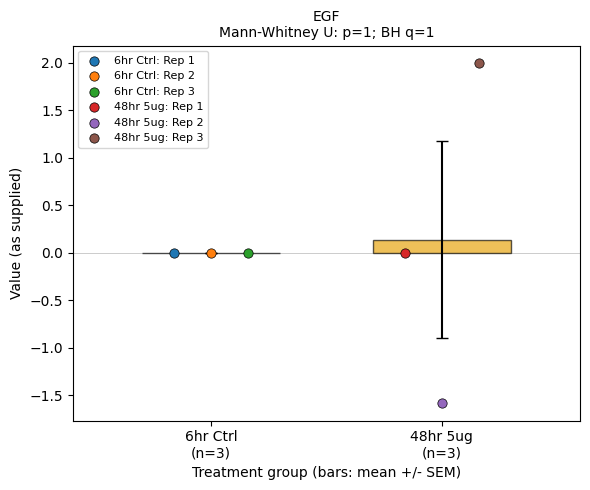

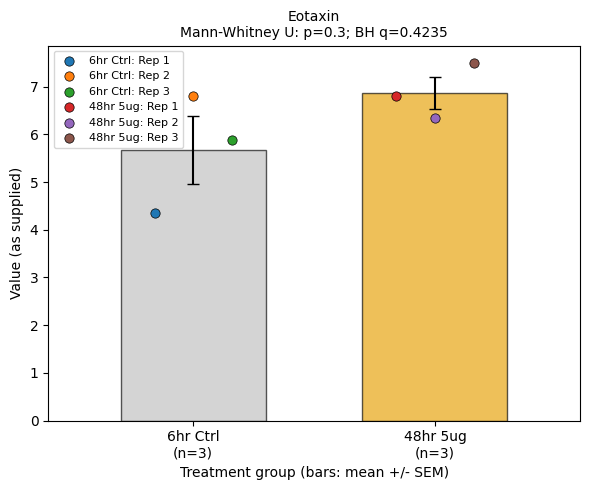

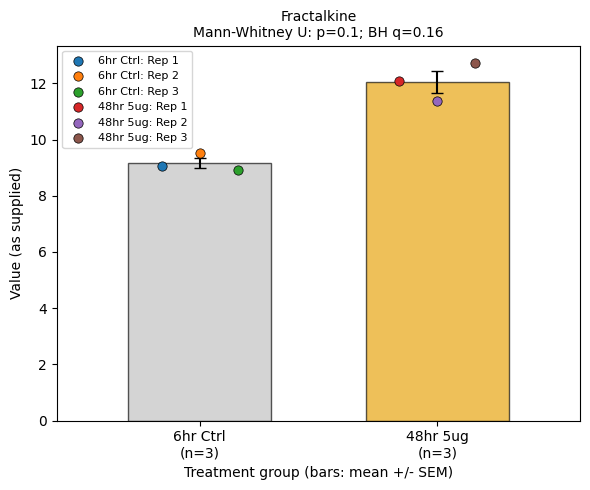

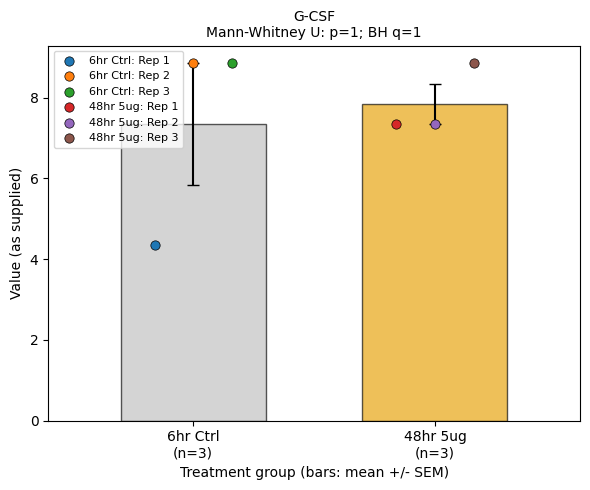

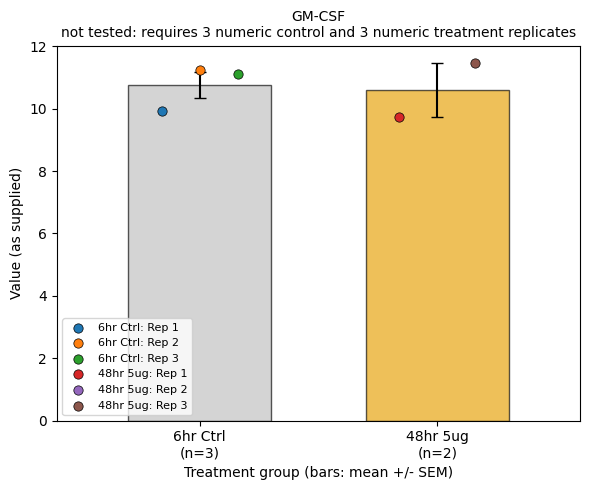

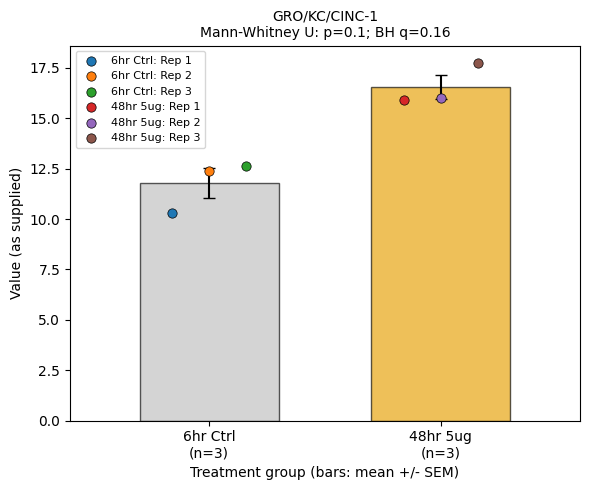

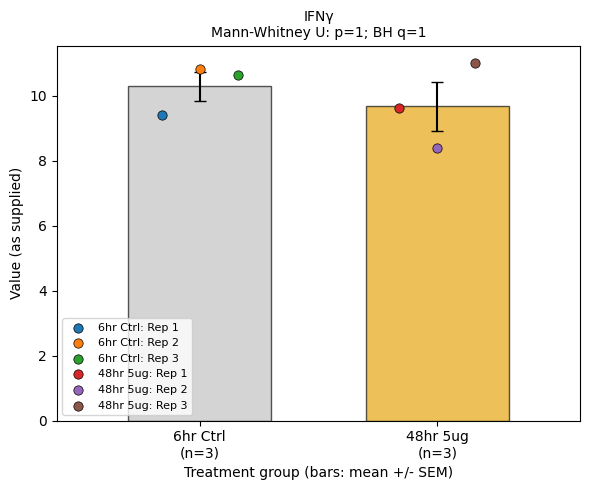

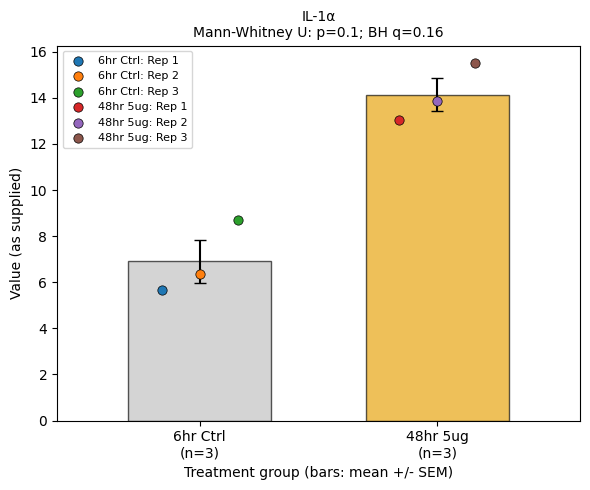

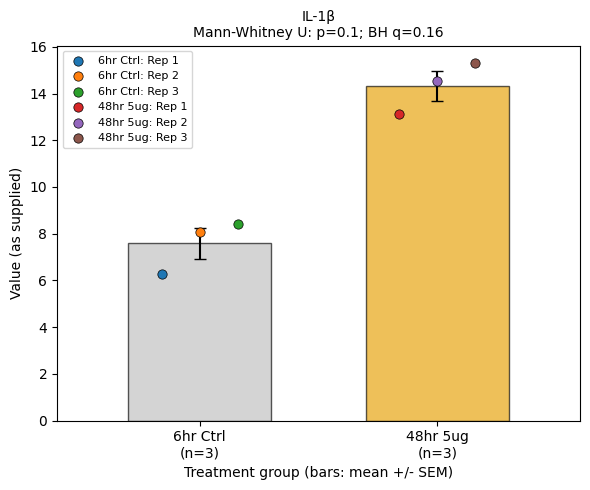

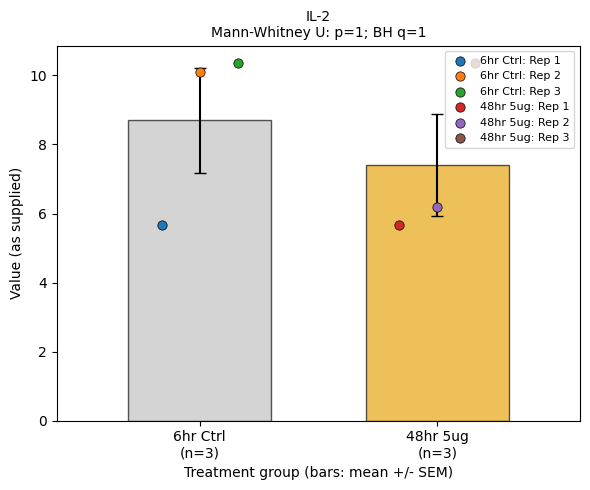

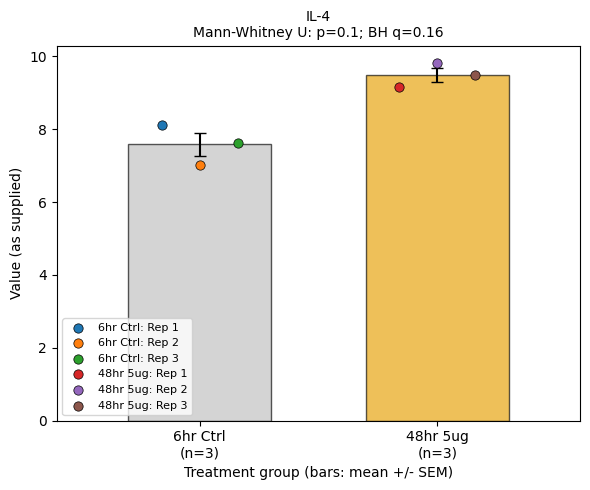

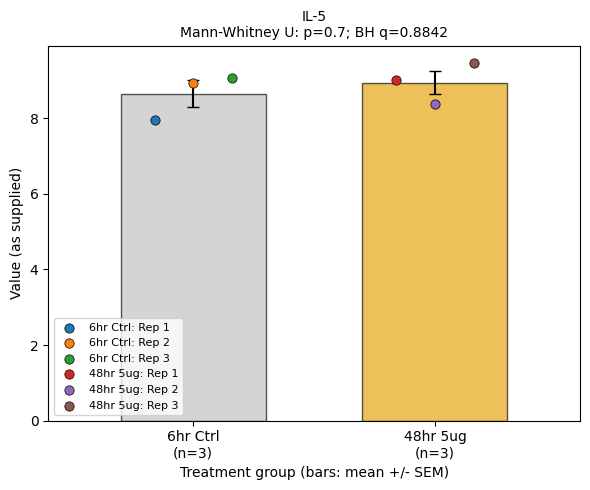

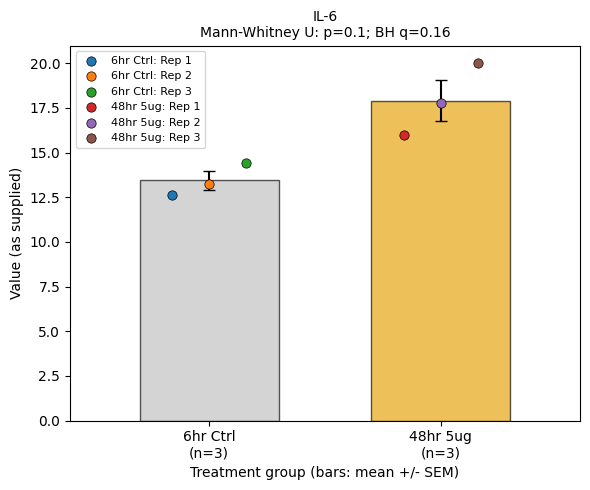

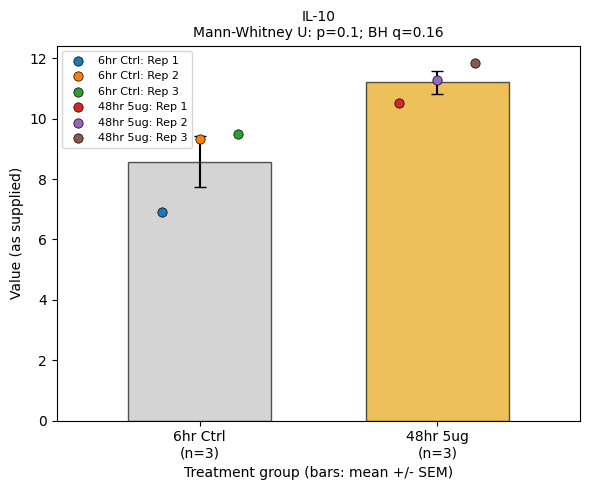

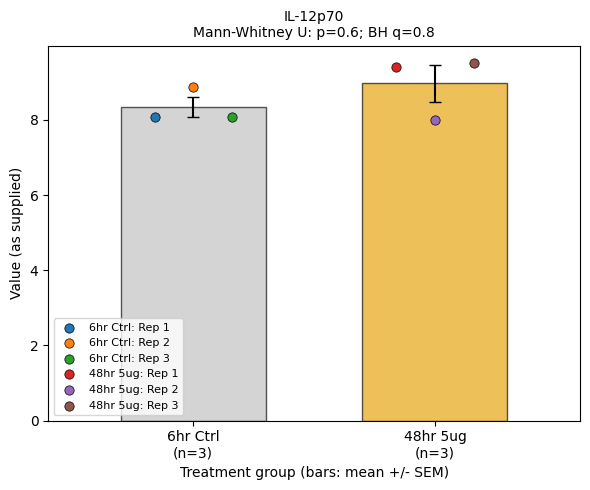

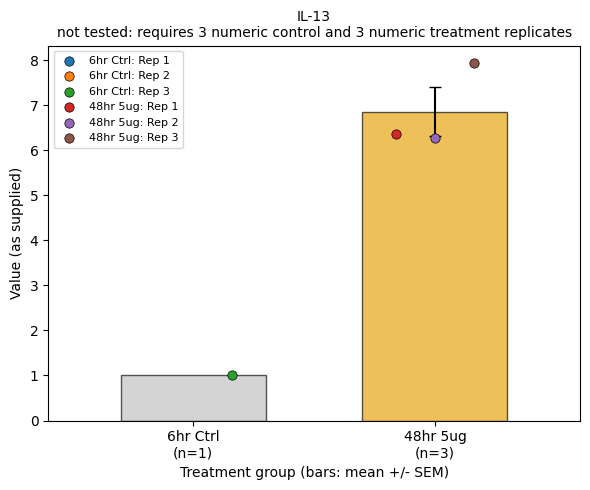

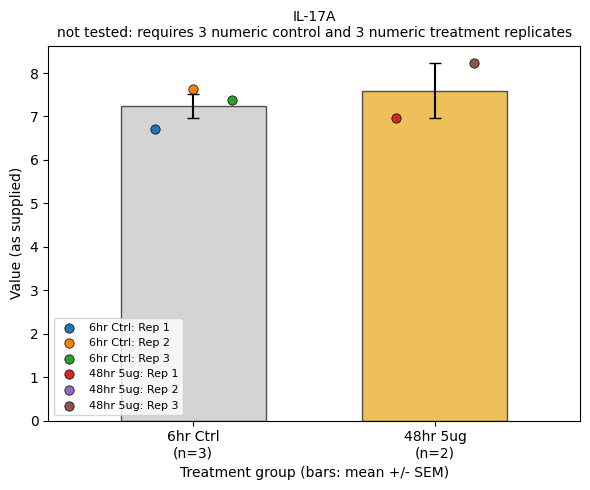

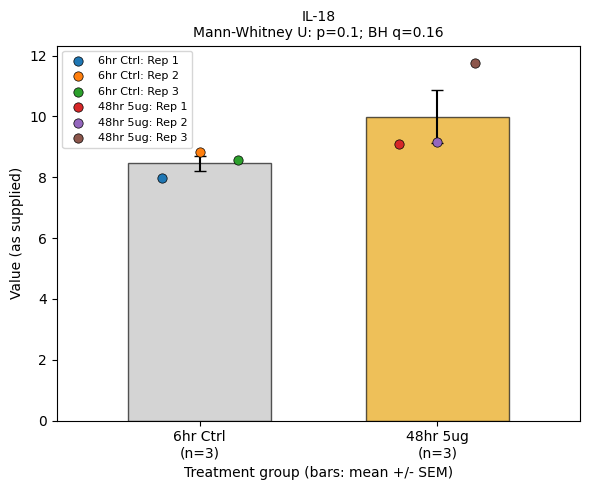

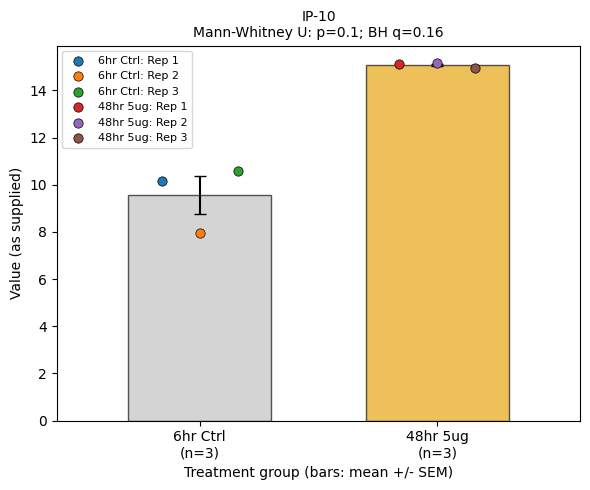

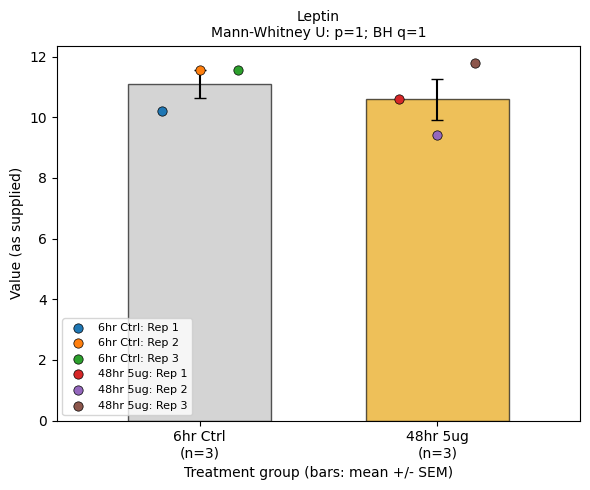

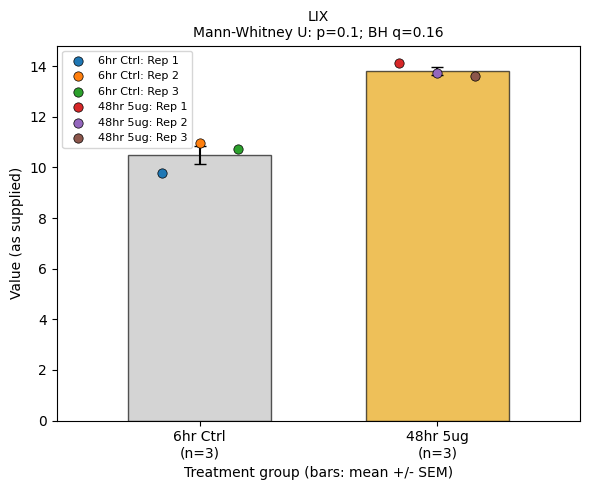

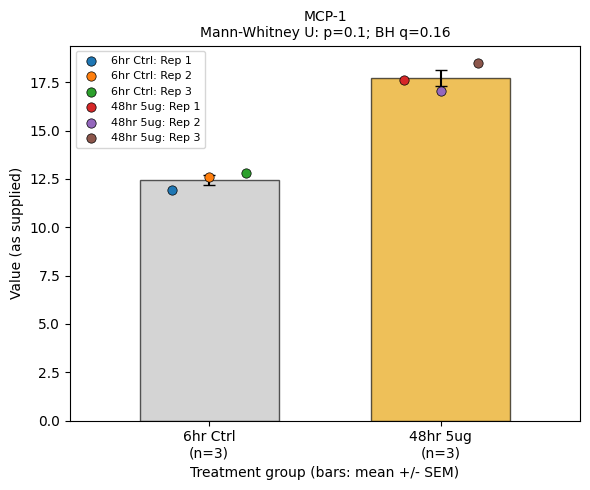

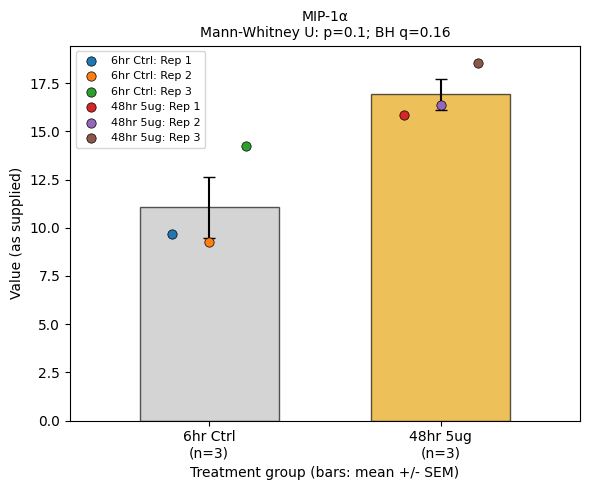

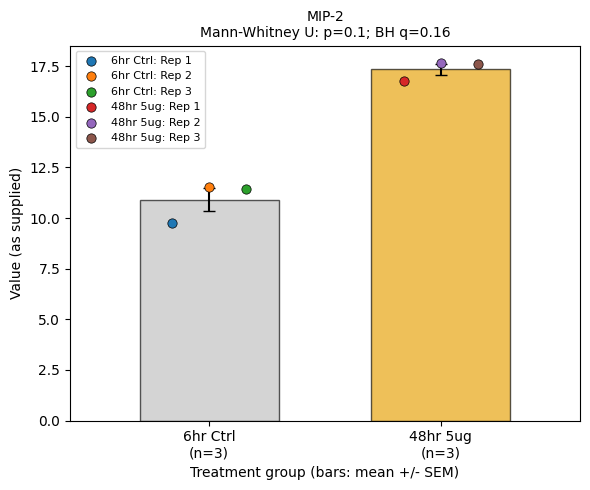

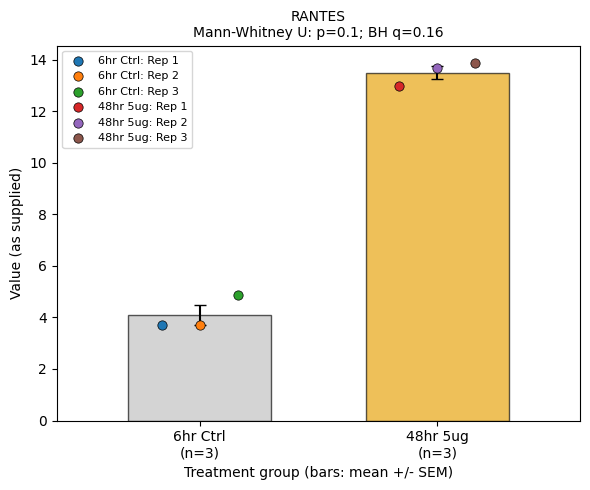

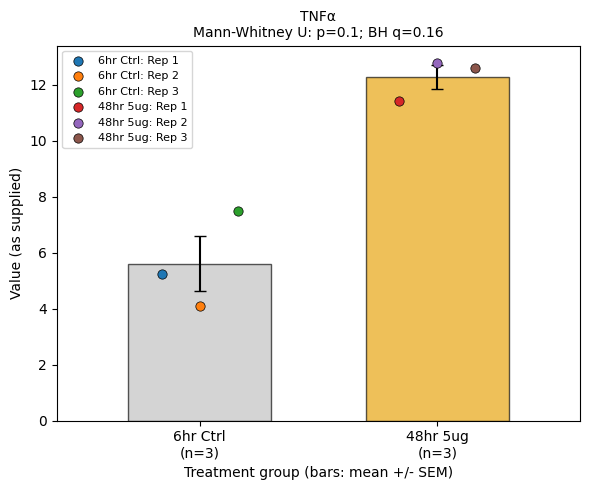

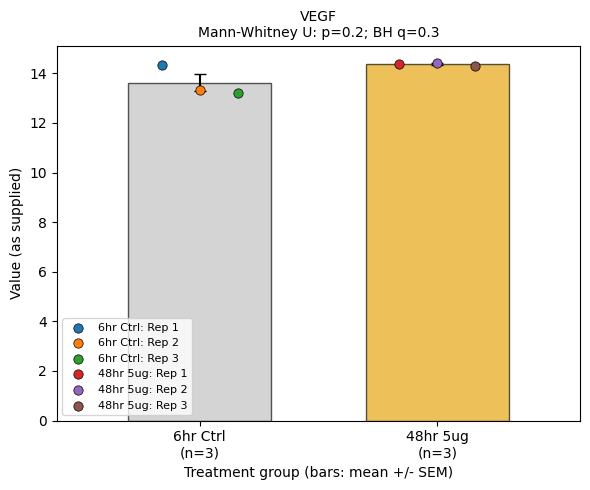

Saved 27 PNGs and results workbook to /Users/allisonpickle/Desktop/261007_Cytokine Reanalysis/Unpaired_Cytokine_Comparison__261018_Updated_48hr__rows194-235.


,Cytokine,Control,Treatment,N_Control,N_Treatment,Mean_Control,SEM_Control,Mean_Treatment,SEM_Treatment,Median_Control,Median_Treatment,Mean_Difference,U_Statistic,P_Value,Q_BH,P_Method,Status,Missing_Control_IDs,Missing_Treatment_IDs,FDR_Family_Size
0,EGF,6hr Ctrl,48hr 5ug,3,3,0.000000,0.000000,0.138346,1.037199,0.000000,0.000000,0.138346,4.5,1.0,1.000000,exact permutation (ties included),tested,,,24
1,Eotaxin,6hr Ctrl,48hr 5ug,3,3,5.677158,0.716758,6.874485,0.334638,5.882643,6.803055,1.197328,7.5,0.3,0.423529,exact permutation (ties included),tested,,,24
2,Fractalkine,6hr Ctrl,48hr 5ug,3,3,9.167920,0.188089,12.050066,0.390687,9.065192,12.074699,2.882145,9.0,0.1,0.160000,exact permutation (ties included),tested,,,24
3,G-CSF,6hr Ctrl,48hr 5ug,3,3,7.345585,1.499905,7.845680,0.499905,8.845490,7.345775,0.500095,4.0,1.0,1.000000,exact permutation (ties included),tested,,,24
4,GM-CSF,6hr Ctrl,48hr 5ug,3,2,10.768158,0.416904,10.583157,0.867195,11.124768,10.583157,-0.185001,NaN,NaN,NaN,not tested,not tested: requires 3 numeric control and 3 n...,,Rep 2,24
5,GRO/KC/CINC-1,6hr Ctrl,48hr 5ug,3,3,11.779559,0.738932,16.548372,0.590873,12.386850,16.009887,4.768814,9.0,0.1,0.160000,exact permutation (ties included),tested,,,24
6,IFNγ,6hr Ctrl,48hr 5ug,3,3,10.291550,0.448331,9.674247,0.752774,10.641751,9.634206,-0.617302,4.0,1.0,1.000000,exact permutation (ties included),tested,,,24
7,IL-1α,6hr Ctrl,48hr 5ug,3,3,6.901893,0.918837,14.137518,0.718427,6.339850,13.873636,7.235625,9.0,0.1,0.160000,exact permutation (ties included),tested,,,24
8,IL-1β,6hr Ctrl,48hr 5ug,3,3,7.591082,0.662366,14.323853,0.628818,8.087463,14.533167,6.732771,9.0,0.1,0.160000,exact permutation (ties included),tested,,,24
9,IL-2,6hr Ctrl,48hr 5ug,3,3,8.707333,1.521485,7.398288,1.483433,10.103725,6.176589,-1.309045,4.0,1.0,1.000000,exact permutation (ties included),tested,,,24


In [2]:
unpaired_bio_points, unpaired_statistics, unpaired_saved_paths = Plot_Unpaired_Cytokine_Comparison(
    file_path="/Users/allisonpickle/Desktop/261007_Cytokine Reanalysis/261118_Compiled_Cytokines_3BioReps.xlsx",
    sheet_name="261018 Updated 48hr",
    control="6hr Ctrl",
    treatment="48hr 5ug",
    header_row=1,
    data_start_row=194,
    data_end_row=235,
    expected_replicates=3,
    cytokines=None,
    save_results=True,
    display_results=True,
)
display(unpaired_statistics)


### Sensitivity analysis: exclude 48hr 5ug, Rep 2

Uses the same supplied-value block (rows 149-190), without transformation, retaining all three control replicates and treatment Rep 1 and Rep 3. All technical rows for treatment Rep 2 are excluded. This is a separately labeled sensitivity analysis, not a replacement for the full-data result; document the scientific/QC reason for exclusion. Outputs go to a separate folder, with excluded input observations recorded in the workbook. Missing values in retained replicates still prevent testing that cytokine. At n=3 versus n=2, the smallest two-sided exact p-value is 0.20. Run the function-definition cell above before running this cell.

In [ ]:
sensitivity_bio_points, sensitivity_statistics, sensitivity_saved_paths = Plot_Unpaired_Cytokine_Comparison(
    file_path="/Users/allisonpickle/Desktop/261007_Cytokine Reanalysis/Compiled_Cytokines_3BioReps.xlsx",
    sheet_name="261018 Updated Analysis",
    control="6hr Ctrl",
    treatment="48hr 5ug",
    header_row=1,
    data_start_row=149,
    data_end_row=190,
    expected_replicates=3,
    exclude_replicates=[("48hr 5ug", "Rep 2")],
    output_dir="/Users/allisonpickle/Desktop/261007_Cytokine Reanalysis/Unpaired_Cytokine_Comparison_Without_48hr5ug_Rep2",
    save_results=True,
    display_results=True,
)
display(sensitivity_statistics)


## Kruskal-Wallis (nonparametric ANOVA) vs 6hr Ctrl, per cytokine

Uses the same workbook block as the unpaired comparison (`261018 Updated Analysis`, header row 1, data rows 149-190, **Obs Conc.** values as supplied, technical repeats averaged within group/Rep). Groups: `6hr Ctrl` (control), `6hr 100ng`, `24hr 100ng`, and `10 uM w3, 100ng LPS 24hr` (3 Rep IDs per group; some `24hr 100ng` concentrations are missing). Edit `groups=[...]` to change the treatment set; names must match the Excel labels exactly.

For each cytokine: a Kruskal-Wallis H test across all included groups (tie-corrected chi-square approximation, df = k - 1), then **Dunn's post-hoc test** of each treatment group vs `6hr Ctrl` (pooled ranks, tie-corrected, two-sided), **Holm-adjusted** across the 3 comparisons within that cytokine. This is the rank-based analog of one-way ANOVA + Dunnett. Omnibus p-values also get Benjamini-Hochberg q-values across cytokines. A cytokine is **not tested** if any group lacks 3 numeric replicates. With n=3 per group, the chi-square approximation is approximate and power is limited.

Plots: bars = mean +/- SEM, dots = biological replicates, stars = Holm-adjusted Dunn's p (* <0.05, ** <0.01, *** <0.001, **** <0.0001). PNGs and `Kruskal_Wallis_Results.xlsx` (sheets: Kruskal_Wallis, Dunn_vs_Control, Biological_Replicates, Input_Observations, Analysis_Notes) are saved to a `Kruskal_Wallis_vs_Control` folder beside the source workbook. Returns `(bio_points, kruskal_statistics, dunn_statistics, saved_paths)`. Run the function cell, then the example cell.

In [1]:
def Plot_Kruskal_Wallis_Cytokine_Comparison(
    file_path,
    sheet_name="261018 Updated Analysis",
    *,
    control="6hr Ctrl",
    groups=("6hr 100ng", "24hr 100ng", "10 uM w3, 100ng LPS 24hr"),
    header_row=1,
    data_start_row=149,
    data_end_row=190,
    sample_col="B",
    rep_col="A",
    start_col="F",
    col_step=3,
    obs_conc_offset=1,
    cytokines=None,
    expected_replicates=3,
    alpha=0.05,
    output_dir=None,
    save_results=True,
    display_results=True,
):
    """Kruskal-Wallis per cytokine, then Dunn's tests of each group vs control.

    Returns (bio_points, kruskal_statistics, dunn_statistics, saved_paths).
    Parsing matches Plot_Unpaired_Cytokine_Comparison: Obs Conc. values as
    supplied, no transformation; technical repeats averaged within group/Rep.
    Kruskal-Wallis H uses scipy's tie-corrected chi-square approximation.
    Dunn's z uses pooled ranks across all included groups, tie-corrected,
    two-sided, Holm-adjusted across the (k - 1) comparisons within each
    cytokine. Omnibus p-values also get BH FDR q-values across cytokines.
    A cytokine is tested only when every group has expected_replicates
    numeric biological values; missing values are never imputed.
    """
    from pathlib import Path
    import re
    import matplotlib.pyplot as plt
    import numpy as np
    import pandas as pd
    from openpyxl.utils import column_index_from_string
    from scipy import stats

    for label, value in (("header_row", header_row), ("data_start_row", data_start_row),
                         ("col_step", col_step), ("expected_replicates", expected_replicates)):
        if isinstance(value, bool) or not isinstance(value, int) or value < 1:
            raise ValueError(f"{label} must be a positive integer.")
    if expected_replicates < 2:
        raise ValueError("expected_replicates must be at least 2.")
    if isinstance(obs_conc_offset, bool) or not isinstance(obs_conc_offset, int) or not 0 <= obs_conc_offset < col_step:
        raise ValueError("obs_conc_offset must be an integer within each cytokine block.")
    if not 0 < alpha < 1:
        raise ValueError("alpha must be between 0 and 1.")
    if not isinstance(control, str) or not control.strip():
        raise ValueError("control must be a nonempty string.")
    control = control.strip()
    if isinstance(groups, str) or not groups or any(not isinstance(g, str) or not g.strip() for g in groups):
        raise ValueError("groups must be a nonempty list of treatment names.")
    others = [g.strip() for g in groups if g.strip() != control]
    if len(set(others)) != len(others) or not others:
        raise ValueError("groups must contain unique names other than the control.")
    order = [control, *others]
    if cytokines is not None:
        if (not isinstance(cytokines, list) or not cytokines
                or any(not isinstance(name, str) or not name.strip() for name in cytokines)):
            raise ValueError("cytokines must be a nonempty list of names, or None.")
        cytokines = [name.strip() for name in cytokines]
        if len(set(cytokines)) != len(cytokines):
            raise ValueError("cytokines contains duplicate names.")
    indices = []
    for column in (sample_col, rep_col, start_col):
        if not isinstance(column, str) or not re.fullmatch(r"[A-Za-z]+", column):
            raise ValueError("Column settings must be Excel column letters.")
        indices.append(column_index_from_string(column) - 1)
    sample_idx, rep_idx, first_idx = indices
    source = Path(file_path).expanduser().resolve()
    with pd.ExcelFile(source) as book:
        if not isinstance(sheet_name, str) or sheet_name not in book.sheet_names:
            raise ValueError(f"Unknown sheet {sheet_name!r}. Available: {book.sheet_names}")
        raw = pd.read_excel(book, sheet_name=sheet_name, header=None)
    last_row = len(raw) if data_end_row is None else data_end_row
    if isinstance(last_row, bool) or not isinstance(last_row, int) or not 1 <= header_row < data_start_row <= last_row <= len(raw):
        raise ValueError("Choose valid inclusive Excel data rows after header_row.")
    if max(indices) >= raw.shape[1]:
        raise ValueError("A selected column lies outside the sheet.")
    headers = {}
    for idx in range(first_idx, raw.shape[1], col_step):
        value = raw.iat[header_row - 1, idx]
        if pd.isna(value) or not str(value).strip():
            continue
        name = str(value).strip()
        if name in headers or idx + obs_conc_offset >= raw.shape[1]:
            raise ValueError(f"Duplicate header or missing value column for {name!r}.")
        headers[name] = idx + obs_conc_offset
    names = list(headers) if cytokines is None else cytokines
    if not names or set(names) - set(headers):
        raise ValueError(f"Choose cytokines from these headers: {list(headers)}")
    rows = raw.iloc[data_start_row - 1:last_row].copy()
    labels = rows.iloc[:, sample_idx].fillna("").astype(str).str.strip()
    absent = [name for name in order if not labels.eq(name).any()]
    if absent:
        raise ValueError(f"Missing groups {absent}. Available: {sorted(set(labels) - {''})}")
    records = []
    for row_idx in rows.index[labels.isin(order)]:
        rep = raw.iat[row_idx, rep_idx]
        if pd.isna(rep) or not str(rep).strip():
            raise ValueError(f"Missing biological replicate ID at Excel row {row_idx + 1}.")
        for name in names:
            value = raw.iat[row_idx, headers[name]]
            if pd.isna(value) or (isinstance(value, str) and not value.strip()):
                value = np.nan
            else:
                try:
                    value = float(value)
                except (TypeError, ValueError) as exc:
                    raise ValueError(f"Nonnumeric/censored {name} at Excel row {row_idx + 1}: {value!r}. Resolve on the supplied scale first.") from exc
                if not np.isfinite(value):
                    raise ValueError(f"Nonfinite {name} at Excel row {row_idx + 1}.")
            records.append((labels.loc[row_idx], str(rep).strip(), name, value, row_idx + 1))
    observations = pd.DataFrame(records, columns=["Sample", "Rep", "Cytokine", "Value", "Excel_Row"])
    rep_sets = {group: set(observations.loc[observations.Sample.eq(group), "Rep"]) for group in order}
    wrong = {group: sorted(ids) for group, ids in rep_sets.items() if len(ids) != expected_replicates}
    if wrong:
        raise ValueError(f"Expected {expected_replicates} biological IDs per group; found {wrong}.")
    bio_points = observations.groupby(["Cytokine", "Sample", "Rep"], sort=False, as_index=False).agg(
        Value=("Value", "mean"), Number_Values=("Value", "count"), Number_Rows=("Value", "size"))
    k = len(order)
    print(f"Groups (k={k}, n={expected_replicates} each): {order}. Missing input values: {int(observations.Value.isna().sum())}. "
          "Values used as supplied, without transformation; technical repeats averaged on the supplied scale.")

    kw_rows, dunn_rows, group_values = [], [], {}
    for name in names:
        metric = bio_points.loc[bio_points.Cytokine.eq(name)]
        values = {group: metric.loc[metric.Sample.eq(group)].set_index("Rep").Value.sort_index() for group in order}
        group_values[name] = values
        clean = {group: series.dropna() for group, series in values.items()}
        missing = "; ".join(f"{g}: {', '.join(s.index[s.isna()])}" for g, s in values.items() if s.isna().any())
        row = dict(Cytokine=name, Control=control, Number_Groups=k,
                   N_Total=sum(len(s) for s in clean.values()), H_Statistic=np.nan, DF=k - 1,
                   P_Value=np.nan, Q_BH=np.nan, P_Method="not tested", Status="tested",
                   Missing_IDs=missing)
        tested = all(len(s) == expected_replicates for s in clean.values())
        if not tested:
            row["Status"] = f"not tested: requires {expected_replicates} numeric replicates in every group"
        else:
            pooled = np.concatenate([clean[g].to_numpy() for g in order])
            n_total = len(pooled)
            ranks = stats.rankdata(pooled)
            _, tie_counts = np.unique(pooled, return_counts=True)
            tie_sum = float(np.sum(tie_counts ** 3 - tie_counts))
            if np.ptp(pooled) == 0:
                h_stat, p_value = 0.0, 1.0
            else:
                h_stat, p_value = stats.kruskal(*(clean[g].to_numpy() for g in order))
            row.update(H_Statistic=float(h_stat), P_Value=float(p_value),
                       P_Method="chi-square approximation (tie corrected)")
            sizes = [len(clean[g]) for g in order]
            bounds = np.cumsum([0, *sizes])
            mean_ranks = {g: ranks[bounds[i]:bounds[i + 1]].mean() for i, g in enumerate(order)}
            variance = n_total * (n_total + 1) / 12 - tie_sum / (12 * (n_total - 1))
            comparisons = []
            for group in others:
                diff = mean_ranks[group] - mean_ranks[control]
                se = np.sqrt(variance * (1 / len(clean[group]) + 1 / len(clean[control]))) if variance > 0 else 0.0
                z = diff / se if se > 0 else 0.0
                comparisons.append((group, diff, z, float(2 * stats.norm.sf(abs(z)))))
            raw_p = np.array([c[3] for c in comparisons])
            holm_order = np.argsort(raw_p)
            holm = np.empty_like(raw_p)
            running = 0.0
            for rank_i, idx in enumerate(holm_order):
                running = max(running, min(1.0, (len(raw_p) - rank_i) * raw_p[idx]))
                holm[idx] = running
            for (group, diff, z, p), p_adj in zip(comparisons, holm):
                dunn_rows.append(dict(
                    Cytokine=name, Group=group, Control=control,
                    N_Group=len(clean[group]), N_Control=len(clean[control]),
                    Mean_Group=clean[group].mean(), SEM_Group=clean[group].sem(),
                    Mean_Control=clean[control].mean(), SEM_Control=clean[control].sem(),
                    Median_Group=clean[group].median(), Median_Control=clean[control].median(),
                    Mean_Rank_Group=mean_ranks[group], Mean_Rank_Control=mean_ranks[control],
                    Mean_Rank_Difference=diff, Z_Statistic=z,
                    P_Unadjusted=p, P_Holm=float(p_adj),
                    Significant=bool(p_adj < alpha),
                    Omnibus_P=float(p_value)))
        kw_rows.append(row)
    kruskal_statistics = pd.DataFrame(kw_rows)
    dunn_statistics = pd.DataFrame(dunn_rows)
    valid = kruskal_statistics.P_Value.dropna().sort_values()
    if len(valid):
        adjusted = valid.to_numpy() * len(valid) / np.arange(1, len(valid) + 1)
        kruskal_statistics.loc[valid.index, "Q_BH"] = np.minimum.accumulate(adjusted[::-1])[::-1].clip(0, 1)
    kruskal_statistics["FDR_Family_Size"] = len(valid)
    print(f"Kruskal-Wallis tests: {len(valid)}/{len(names)} cytokines; BH FDR across {len(valid)} omnibus tests. "
          f"Dunn's post-hoc: {len(others)} comparisons vs {control} per cytokine, Holm-adjusted within cytokine.")
    for row in kruskal_statistics.itertuples():
        if row.Status != "tested":
            print(f"{row.Cytokine}: {row.Status}; missing IDs: {row.Missing_IDs or 'none'}.")

    output = Path(output_dir).expanduser().resolve() if output_dir is not None else source.parent / "Kruskal_Wallis_vs_Control"
    saved_paths = []
    if save_results:
        output.mkdir(parents=True, exist_ok=True)
    rep_ids = sorted(set(bio_points.Rep))
    rep_colors = {rep: plt.get_cmap("tab10")(i % 10) for i, rep in enumerate(rep_ids)}

    def stars(p):
        return "****" if p < 0.0001 else "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < alpha else ""

    for index, row in enumerate(kruskal_statistics.itertuples(), start=1):
        fig, ax = plt.subplots(figsize=(max(6, 1.0 * k + 2), 5))
        try:
            values = group_values[row.Cytokine]
            dunn = (dunn_statistics.loc[dunn_statistics.Cytokine.eq(row.Cytokine)].set_index("Group")
                    if len(dunn_statistics) else pd.DataFrame())
            tops = []
            for x, group in enumerate(order):
                series = values[group].dropna()
                top = np.nan
                if len(series):
                    mean = series.mean()
                    ax.bar(x, mean, width=0.6, color="#BDBDBD" if group == control else "#E69F00",
                           edgecolor="black", linewidth=1, alpha=0.65, zorder=1)
                    sem = series.sem() if len(series) > 1 else 0.0
                    if len(series) > 1:
                        ax.errorbar(x, mean, yerr=sem, fmt="none", color="black", capsize=4, zorder=3)
                    top = max(mean + sem, series.max())
                offsets = np.linspace(-0.16, 0.16, len(values[group])) if len(values[group]) > 1 else [0.0]
                for offset, (rep, value) in zip(offsets, values[group].items()):
                    ax.scatter(x + offset, value, color=rep_colors[rep], edgecolors="black",
                               linewidths=0.5, s=40, zorder=4)
                tops.append(top)
            span = np.nanmax(tops) - min(0.0, np.nanmin([v.min() for v in values.values()])) if np.isfinite(np.nanmax(tops)) else 1.0
            for x, group in enumerate(order[1:], start=1):
                if group in dunn.index and np.isfinite(tops[x]):
                    mark = stars(dunn.at[group, "P_Holm"])
                    if mark:
                        ax.text(x, tops[x] + 0.04 * (span or 1.0), mark, ha="center", va="bottom", fontsize=12)
            annotation = (f"Kruskal-Wallis H={row.H_Statistic:.3g}, p={row.P_Value:.4g}; BH q={row.Q_BH:.4g}"
                          if row.Status == "tested" else row.Status)
            ax.set_title(f"{row.Cytokine}\n{annotation}\nDunn's vs {control} (Holm): * p<{alpha:g}", fontsize=9)
            ax.set_xticks(range(k))
            ax.set_xticklabels([f"{g}\n(n={len(values[g].dropna())})" for g in order], rotation=45, ha="right")
            ax.set_ylabel("Obs Conc. (as supplied)")
            ax.set_xlabel("Treatment group (bars: mean +/- SEM)")
            ax.axhline(0, color="0.8", linewidth=0.7, zorder=0)
            handles = [plt.Line2D([], [], marker="o", linestyle="", markerfacecolor=rep_colors[r],
                                  markeredgecolor="black", label=r) for r in rep_ids]
            ax.legend(handles=handles, fontsize=8, title="Biological replicate", title_fontsize=8)
            ax.set_ylim(top=ax.get_ylim()[1] * 1.08 if ax.get_ylim()[1] > 0 else ax.get_ylim()[1])
            fig.tight_layout()
            if save_results:
                safe_name = re.sub(r"[^\w-]+", "_", row.Cytokine).strip("_")
                path = output / f"KruskalWallis_{index:02d}_{safe_name}.png"
                fig.savefig(path, dpi=300, bbox_inches="tight")
                saved_paths.append(str(path))
            if display_results:
                plt.show()
        finally:
            plt.close(fig)
    if save_results:
        workbook_path = output / "Kruskal_Wallis_Results.xlsx"
        if workbook_path.resolve() == source:
            raise ValueError("Output workbook must not overwrite the source workbook.")
        with pd.ExcelWriter(workbook_path) as writer:
            kruskal_statistics.to_excel(writer, sheet_name="Kruskal_Wallis", index=False)
            dunn_statistics.to_excel(writer, sheet_name="Dunn_vs_Control", index=False)
            bio_points.to_excel(writer, sheet_name="Biological_Replicates", index=False)
            observations.to_excel(writer, sheet_name="Input_Observations", index=False)
            pd.DataFrame({"Setting": ["Source", "Sheet", "Excel data rows", "Groups", "Omnibus test", "Post-hoc test", "Scale", "Omnibus FDR", "Expected replicates per group"],
                          "Value": [str(source), sheet_name, f"{data_start_row}-{last_row}", ", ".join(order),
                                    "Kruskal-Wallis H, tie-corrected chi-square approximation (df = k - 1)",
                                    f"Dunn's z on pooled ranks (tie corrected), two-sided, each group vs {control}; Holm-adjusted across {len(others)} comparisons within each cytokine",
                                    "Values as supplied; no transformation, normalization, or imputation",
                                    f"BH across {len(valid)} valid omnibus tests", str(expected_replicates)]}).to_excel(writer, sheet_name="Analysis_Notes", index=False)
        saved_paths.append(str(workbook_path))
        print(f"Saved {len(names)} PNGs and results workbook to {output}.")
    return bio_points, kruskal_statistics, dunn_statistics, saved_paths

In [10]:
kw_bio_points, kw_statistics, kw_dunn_statistics, kw_saved_paths = Plot_Kruskal_Wallis_Cytokine_Comparison(
    file_path="/Users/allisonpickle/Desktop/261007_Cytokine Reanalysis/Compiled_Cytokines_3BioReps.xlsx",
    sheet_name="261018 Updated Analysis",
    control="6hr Ctrl",
    groups=["6hr 100ng", "24hr 100ng", "10 uM w3, 100ng LPS 24hr"],
    header_row=1,
    data_start_row=149,
    data_end_row=190,
    expected_replicates=3,
    cytokines=None,
    alpha=0.05,
    save_results=False,
    display_results=True,
)
display(kw_statistics)
if kw_dunn_statistics.empty:
    print("No Dunn post-hoc comparisons were run; at least one group is missing numeric replicate data for every cytokine.")
else:
    display(kw_dunn_statistics.loc[kw_dunn_statistics["Significant"]])

NameError: name 'Plot_Kruskal_Wallis_Cytokine_Comparison' is not defined

## Exploratory cytokine-morphology correlation insets (new, separate function)

The correlation plotting function lives in `Cytokine_Morphology_Correlation.py`. Run that script directly for descriptive condition-mean cross plots, or pass `--replicate-map` once per verified same-culture pair. The paired inset uses log2 of observed concentration on x and ln(area + 0.5), averaged within wells then equally across wells, on y. Both are adjusted for categorical time and replicate within each dose. Use `--help` for the label format. The notebook example below does not assume pairing. Source data are not modified.

The example tries **IL-6, TNFα, and IL-1β versus ln(Area)**, with a separate figure for each 5/100 ng/mL dose. Each new figure keeps the dual-axis time course: morphology triangles, mean squares, well SEM and dashed trends on the left; cytokine circles, mean diamonds and solid trends on the right, with matching sample colors. The correlation panel is added alongside it. Change `correlation_cytokines`, `metrics` (exact CSV stems), or `morphology_scale` (`"raw"`/`"ln"`) in the new call to try others. The ln data are already transformed by the morphology reader and are not logged again.

The example shows the three matched condition means (6, 24, 72 hr) as time-labeled points with an unadjusted linear fit. The inset reports unadjusted R² (squared Pearson r), and the legend reports signed Pearson r and the number of matched time-point means. No significance test is performed, and the correlation may reflect a shared time trend. The paired script mode shows partial R² and a residual fit only when a verified replicate map is supplied. Doses are never pooled.

The example also saves the original-style raw/ln dual-axis plots in `Timecourses`. Descriptive inset PNGs and a matched-means workbook are saved in `Cytokine_Morphology_Correlations/Descriptive` next to the cytokine workbook. Verified replicate-level output from the standalone script is saved separately in `Paired_Time_Adjusted`.

In [3]:
def Plot_Cytokine_Morphology_Correlation_Plots(
    cytokine_points,
    morphology_points,
    *,
    cytokines=None,
    metrics=None,
    morphology_scale="ln",
    control_for_time=False,
    descriptive_only=False,
    output_dir=None,
    save_results=True,
    display_results=False,
):
    """New condition-mean correlation plots; original plotting APIs are unchanged."""
    from pathlib import Path
    import importlib.util

    candidates = [
        base / filename
        for base in [Path.cwd(), *Path.cwd().parents]
        for filename in ("Cytokine_Morphology_Correlation.py", "Cytokine Analysis/Cytokine_Morphology_Correlation.py")
    ]
    module_path = next((path for path in candidates if path.is_file()), None)
    if module_path is None:
        raise FileNotFoundError("Could not locate Cytokine_Morphology_Correlation.py from the notebook working directory.")
    spec = importlib.util.spec_from_file_location("_cytokine_morphology_correlations", module_path)
    if spec is None or spec.loader is None:
        raise ImportError(f"Could not load correlation implementation at {module_path}.")
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    return module.Plot_Cytokine_Morphology_Correlation_Plots(
        cytokine_points, morphology_points,
        cytokines=cytokines, metrics=metrics, morphology_scale=morphology_scale,
        control_for_time=control_for_time,
        descriptive_only=descriptive_only,
        output_dir=output_dir, save_results=save_results,
        display_results=display_results,
    )

Excluded 648 rows by 5/100 ng/mL time-course eligibility.
Reading '261018 Updated Analysis' rows 194-235; 0 below-detection observations retained and flagged.
Missing concentrations omitted from descriptive summaries: 56.
Cytokine missing concentrations omitted: 6.
AUC.csv: unmatched morphology treatments excluded: ['24hr_500ng', '24hr_5ug', '24hr_Ctrl', '48hr_100ng', '48hr_500ng', '48hr_5ng', '48hr_5ug', '48hr_Ctrl', '6hr_500ng', '6hr_5ug', '6hr_Ctrl', '72hr_500ng', '72hr_5ug', '72hr_Ctrl', '96hr_100ng', '96hr_500ng', '96hr_5ng', '96hr_5ug', '96hr_Ctrl']
AUC.csv: cytokine samples without morphology: []
AUC.csv: missing matching morphology values omitted: 0.
Area (µm²).csv: unmatched morphology treatments excluded: ['24hr_500ng', '24hr_5ug', '24hr_Ctrl', '48hr_100ng', '48hr_500ng', '48hr_5ng', '48hr_5ug', '48hr_Ctrl', '6hr_500ng', '6hr_5ug', '6hr_Ctrl', '72hr_500ng', '72hr_5ug', '72hr_Ctrl', '96hr_100ng', '96hr_500ng', '96hr_5ng', '96hr_5ug', '96hr_Ctrl']
Area (µm²).csv: cytokine sampl

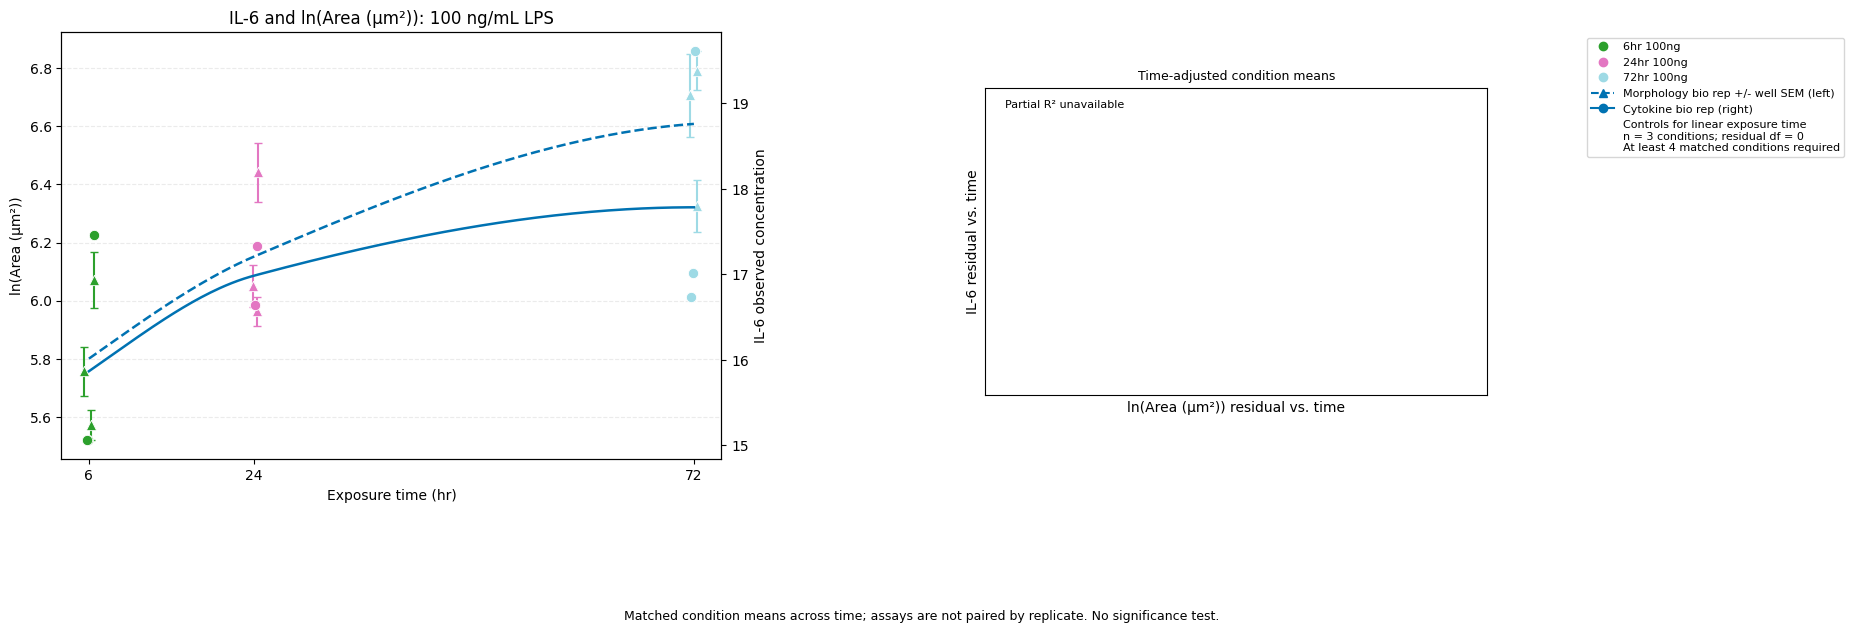

IL-6, Area (µm²), 5 ng/mL: At least 4 matched conditions required; n=3 conditions.


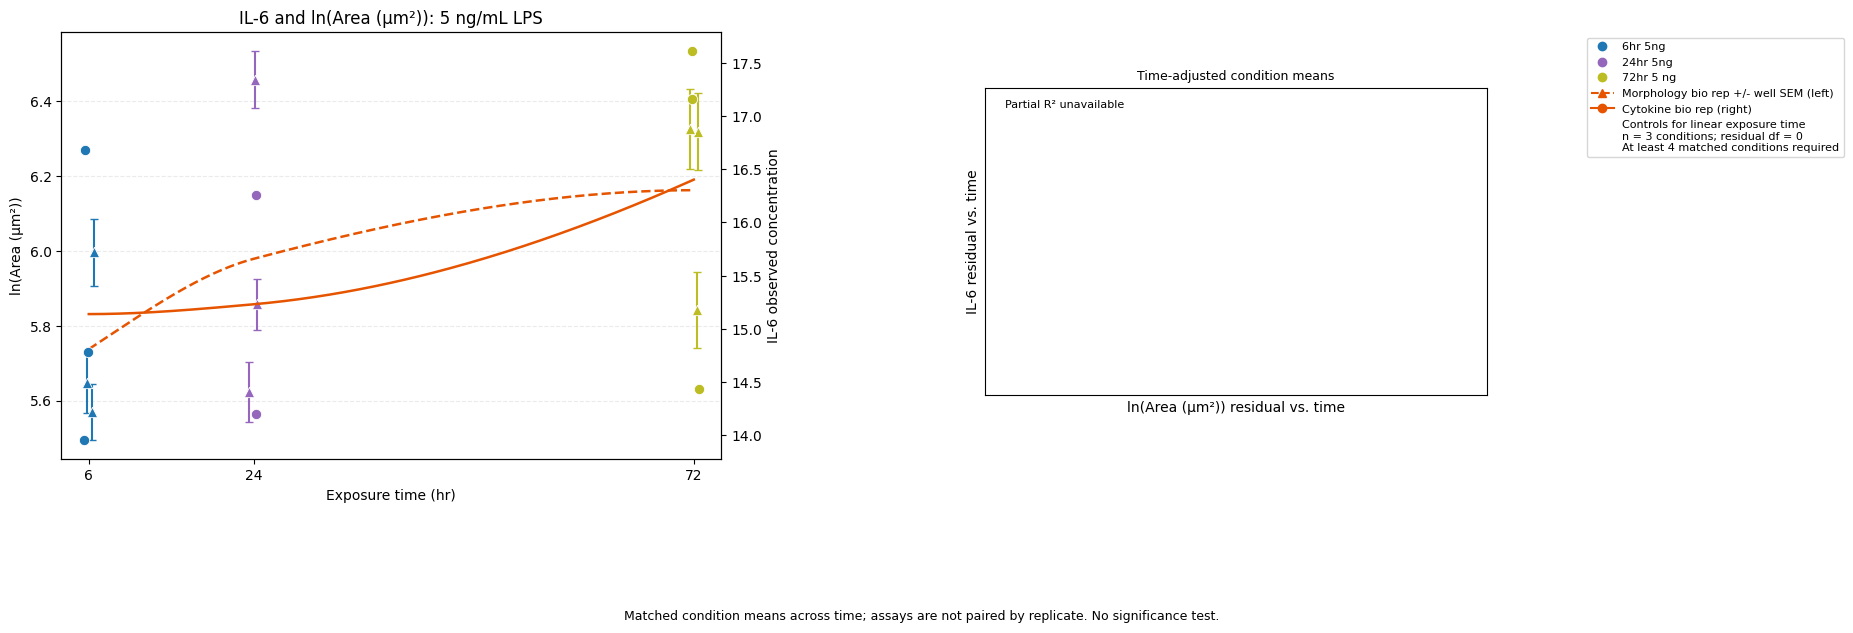

TNFα, Area (µm²), 100 ng/mL: At least 4 matched conditions required; n=3 conditions.


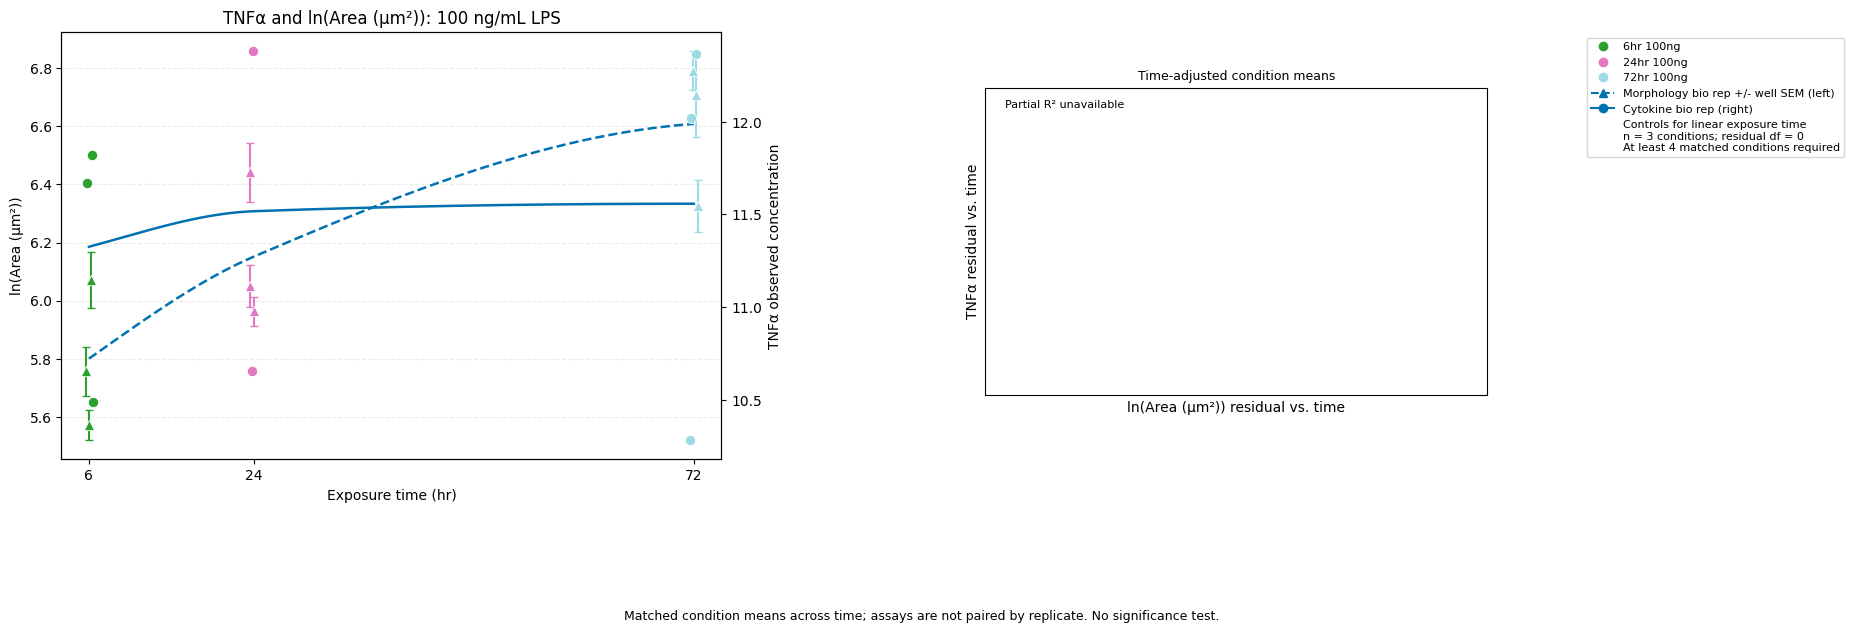

TNFα, Area (µm²), 5 ng/mL: At least 4 matched conditions required; n=3 conditions.


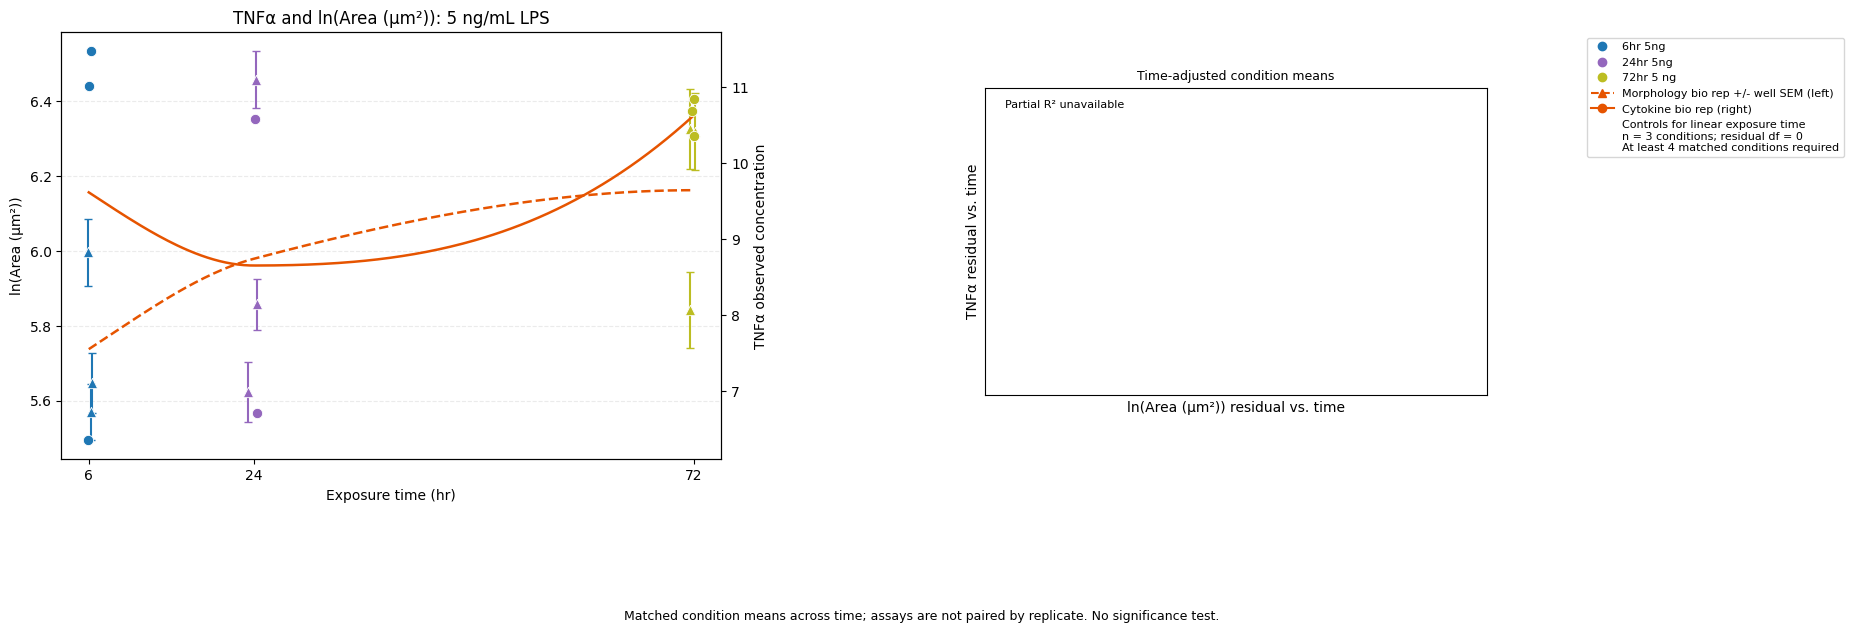

IL-1β, Area (µm²), 100 ng/mL: At least 4 matched conditions required; n=3 conditions.


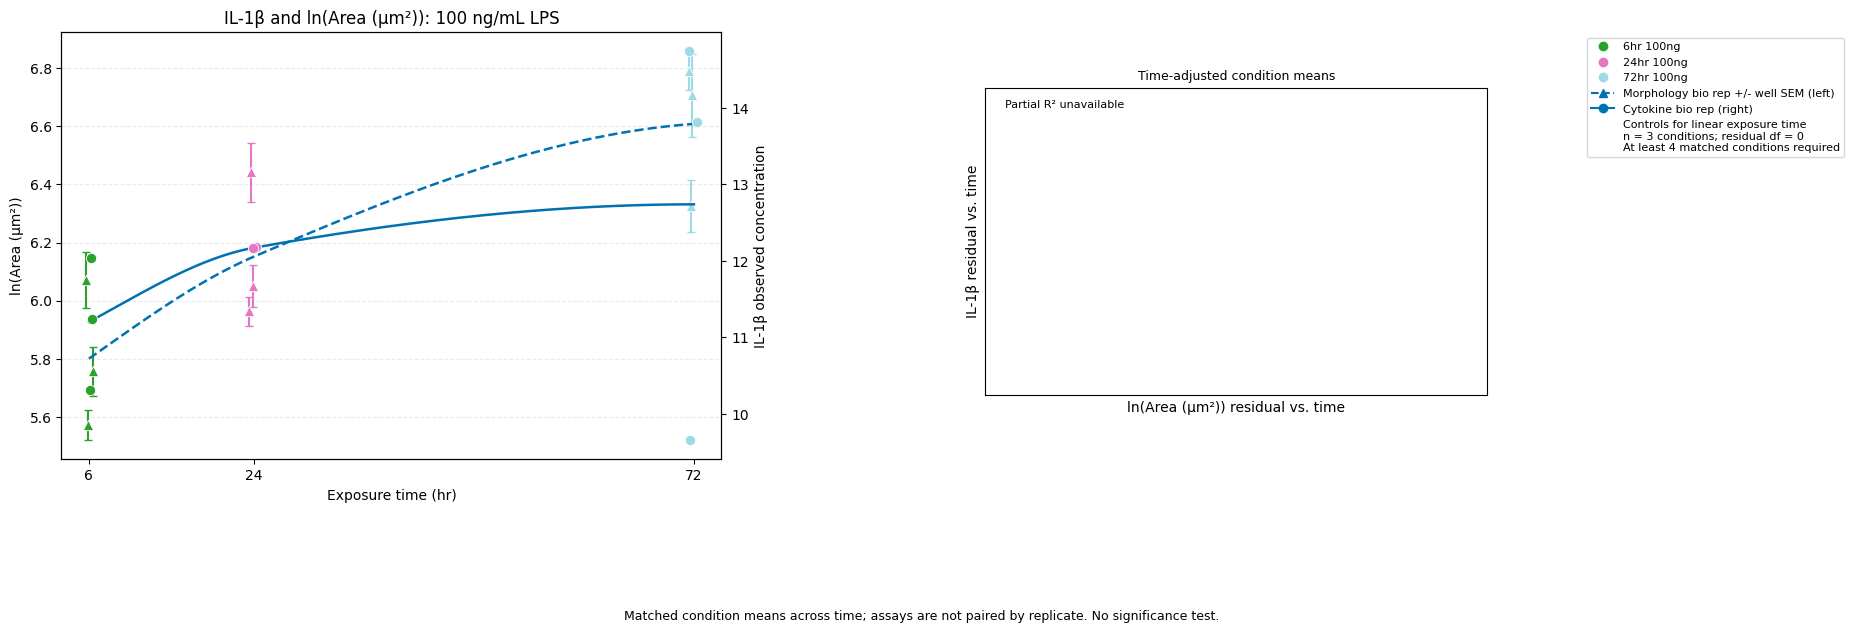

IL-1β, Area (µm²), 5 ng/mL: At least 4 matched conditions required; n=3 conditions.


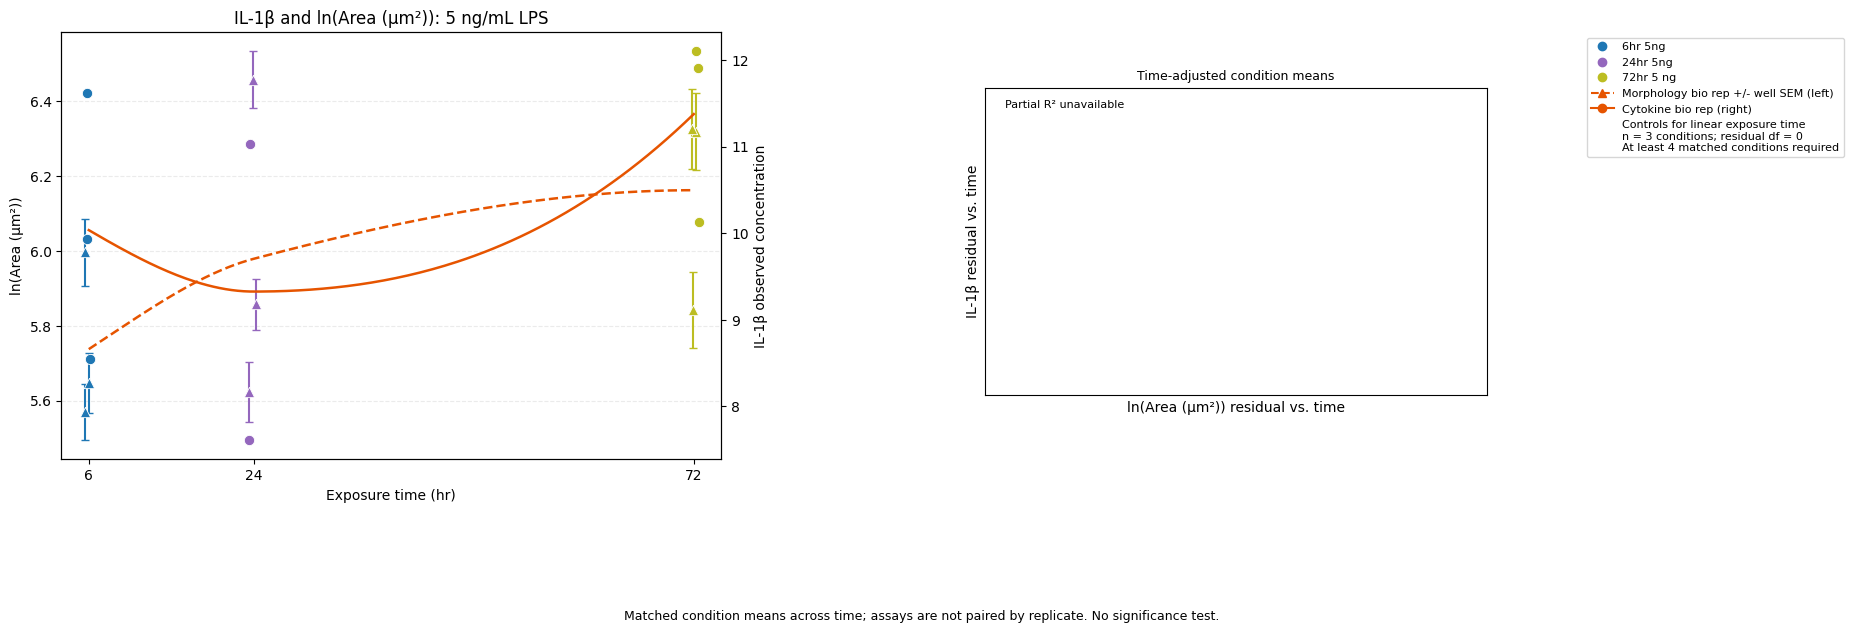

Saved 6 correlation-inset plots and workbook to /Users/allisonpickle/Desktop/261007_Cytokine Reanalysis/Cytokine_Morphology_Correlations/Time_Adjusted.


,Cytokine,Metric,Morphology_Scale,LPS_ng_mL,n_conditions,Partial_r,Partial_R_squared,Residual_Slope,Residual_Intercept,Status,Residual_df
0,IL-6,Area (µm²),ln,100,3,NaN,NaN,NaN,NaN,At least 4 matched conditions required,0
1,IL-6,Area (µm²),ln,5,3,NaN,NaN,NaN,NaN,At least 4 matched conditions required,0
2,TNFα,Area (µm²),ln,100,3,NaN,NaN,NaN,NaN,At least 4 matched conditions required,0
3,TNFα,Area (µm²),ln,5,3,NaN,NaN,NaN,NaN,At least 4 matched conditions required,0
4,IL-1β,Area (µm²),ln,100,3,NaN,NaN,NaN,NaN,At least 4 matched conditions required,0
5,IL-1β,Area (µm²),ln,5,3,NaN,NaN,NaN,NaN,At least 4 matched conditions required,0


Created 156 original-style timecourse/compilation plots and 6 correlation-added plots.


In [4]:
from pathlib import Path
import importlib.util

correlation_modules = {}
for module_name in ("Cytokine_Scatter_Analysis", "Cytokine_Morphology_Analysis"):
    candidates = [
        base / filename
        for base in [Path.cwd(), *Path.cwd().parents]
        for filename in (f"{module_name}.py", f"Cytokine Analysis/{module_name}.py")
    ]
    module_path = next((path for path in candidates if path.is_file()), None)
    if module_path is None:
        raise FileNotFoundError(f"Could not locate {module_name}.py from the notebook working directory.")
    spec = importlib.util.spec_from_file_location(f"_correlation_{module_name}", module_path)
    if spec is None or spec.loader is None:
        raise ImportError(f"Could not load analysis implementation at {module_path}.")
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    correlation_modules[module_name] = module

correlation_file_path = Path("/Users/allisonpickle/Desktop/261007_Cytokine Reanalysis/Compiled_Cytokines_3BioReps.xlsx")
correlation_morphology_folder = Path("/Users/allisonpickle/Desktop/Super LPS/3 BioReps Analysis/All BioReps Microglia Morphology FINAL")
correlation_cytokines = ["IL-6", "TNFα", "IL-1β"]
correlation_input_df, _, _ = correlation_modules["Cytokine_Scatter_Analysis"].Plot_Cytokine_Scatter_Plots(
    correlation_file_path,
    sheet_selections=[
        {"sheet_name": "261018 Updated Analysis", "header_row": 1,
         "data_start_row": 194, "data_end_row": 235,
         "start_col": "F", "obs_conc_offset": 1},
    ],
    include_all_samples=False,
    include_48hr=False,
    run_statistics=False,
    save_results=False,
    display_results=False,
)
correlation_cytokine_points, correlation_morphology_points, correlation_timecourse_paths = correlation_modules["Cytokine_Morphology_Analysis"].Plot_Cytokine_Morphology_Plots(
    correlation_input_df,
    correlation_morphology_folder,
    cytokines=correlation_cytokines,
    output_dir=correlation_file_path.parent / "Cytokine_Morphology_Correlations" / "Timecourses",
    save_results=True,
    display_results=False,
)

correlation_means, correlation_statistics, correlation_saved_paths = Plot_Cytokine_Morphology_Correlation_Plots(
    correlation_cytokine_points,
    correlation_morphology_points,
    cytokines=correlation_cytokines,
    metrics=["Area (µm²)"],
    morphology_scale="ln",
    descriptive_only=True,
    output_dir=correlation_file_path.parent / "Cytokine_Morphology_Correlations" / "Descriptive",
    save_results=True,
    display_results=True,
)
display(correlation_statistics)
print(f"Created {len(correlation_timecourse_paths)} original-style timecourse/compilation plots and {len(correlation_saved_paths)} correlation-added plots.")